# Sistem Deteksi Hama Tanaman - Training, Evaluasi, dan Perbandingan Model (Final)

Versi ini dioptimalkan berdasarkan hasil eksekusi sebelumnya, yang sempat terhenti pada epoch 44 karena keterbatasan alokasi GPU pada Colab versi gratis. Tiga perbaikan utama pada versi ini:

1. **Training bersifat resume-safe**: apabila sesi terputus di tengah pelatihan suatu model, sesi berikutnya akan melanjutkan dari checkpoint terakhir (`last.pt`), bukan mengulang dari awal.
2. **Preprocessing bersifat cache-safe**: hasil filtering dan penyeimbangan kelas disimpan sebagai arsip ke Google Drive. Sesi berikutnya akan memuat arsip tersebut secara instan, tanpa mengulang proses pemeriksaan dan filtering data mentah yang memakan waktu lama (tercatat sekitar dua jam pada sesi sebelumnya).
3. **Evaluasi diperluas signifikan**: mencakup confusion matrix multi-kelas, kurva precision-recall, diagram kalibrasi confidence score, interval kepercayaan (bootstrap) untuk mengantisipasi ukuran data test yang kecil, perbandingan performa val vs test, serta metrik tambahan (mAP75, jumlah parameter, GFLOPs).

Hasil eksplorasi data mentah (pemeriksaan kualitas data dan EDA sebelum preprocessing) dari sesi sebelumnya disajikan sebagai catatan statis pada Bagian 3, tidak dieksekusi ulang.

## 1. Setup Environment

In [ ]:
!pip install -q ultralytics pandas matplotlib seaborn opencv-python-headless pyyaml tqdm scikit-learn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.0/46.0 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 44.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.2/66.2 kB 5.9 MB/s eta 0:00:00


In [ ]:
import os
import gc
import cv2
import json
import time
import yaml
import shutil
import random
import zipfile
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
from collections import Counter, defaultdict
from sklearn.model_selection import train_test_split

import torch
from ultralytics import YOLO

warnings.filterwarnings("ignore")
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titleweight"] = "bold"

print("Library berhasil dimuat")
print("Versi torch  :", torch.__version__)
print("CUDA tersedia:", torch.cuda.is_available())
if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    print("GPU          :", torch.cuda.get_device_name(0))
    print("VRAM total   : {:.2f} GB".format(props.total_memory / 1e9))
else:
    print("Peringatan: GPU tidak terdeteksi. Aktifkan Runtime > Change runtime type > T4 GPU.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.
Library berhasil dimuat
Versi torch  : 2.11.0+cu128
CUDA tersedia: True
GPU          : Tesla T4
VRAM total   : 15.64 GB


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Konfigurasi

**Pemilihan model dipangkas menjadi 3 varian** (dari 6 pada eksperimen awal), disesuaikan dengan karakteristik kasus ini:
- Inferensi berjalan di **server VPS**, bukan perangkat edge (ESP32/Mini PC) -> keterbatasan ukuran/kecepatan model bukan kendala utama.
- Interval pengambilan citra **satu jam sekali** -> kecepatan inferensi real-time tidak relevan, sehingga varian nano/small yang mengorbankan akurasi demi kecepatan tidak lagi menjadi prioritas.
- Fokus diarahkan ke **akurasi terbaik yang realistis dicapai dalam batas waktu sesi Colab**: `yolov8m`, `yolo11m`, dan `yolo11l`.

### Analisis Penyebab Sesi Terputus pada Percobaan Sebelumnya

Log training sesi sebelumnya (model `yolo11m`, terputus di epoch 36 dari target 60, setelah sekitar 2 jam berjalan) menunjukkan `GPU_mem` **stabil di kisaran 7.6-8.0 GB dari 14.9 GB yang tersedia pada Tesla T4, sepanjang seluruh epoch yang sempat berjalan** (tidak pernah naik/menumpuk). Ini adalah bukti kuat bahwa terputusnya sesi **bukan disebabkan oleh kehabisan memori (OOM)**, melainkan **limit waktu penggunaan GPU pada Colab tier gratis** (umumnya sekitar 2 jam untuk sesi berjalan terus-menerus) -- sebuah batasan platform, bukan masalah pada konfigurasi training.

Dengan pemahaman ini, strategi diubah dari "menghindari OOM" menjadi "menghindari melebihi batas waktu sesi", melalui kombinasi:

1. **`time=1.5` (jam)** -- parameter bawaan Ultralytics (terbukti dikenali pada log sebelumnya: `time=None` tercantum di antara argumen training) yang menghentikan training secara rapi begitu batas waktu wall-clock tercapai, terlepas dari epoch yang sedang berjalan. Ini jauh lebih andal dibanding menebak jumlah epoch yang aman, karena durasi tiap epoch bisa bervariasi tergantung beban server Colab saat itu.
2. **`EPOCHS=45`** -- target maksimum epoch sesuai kesepakatan, bertindak sebagai batas kedua (training berhenti pada kondisi mana pun yang tercapai lebih dulu: 45 epoch atau 1.5 jam).
3. **Ukuran batch dinaikkan** (`BATCH_SIZE_PER_MODEL`: 32 untuk `yolov8m`/`yolo11m`, 16 untuk `yolo11l`) -- memanfaatkan ruang VRAM yang ternyata masih longgar (~7GB tersisa dari 14.9GB pada log sebelumnya), mempercepat setiap epoch secara nyata karena lebih sedikit iterasi optimizer diperlukan per epoch.
4. **Resume otomatis dengan penyesuaian target epoch** -- model yang sempat berjalan dengan target lama (contoh: `yolo11m` sempat menargetkan 60 epoch) akan **di-patch otomatis** menjadi target 45 epoch sebelum dilanjutkan, sehingga tetap sesuai kesepakatan terbaru meskipun melanjutkan sesi lama. Lihat Bagian 7 untuk detail mekanismenya.
5. **`multi_scale=False`** -- mempercepat training signifikan (multi-scale training bisa memperlambat 1.5-2x) dengan trade-off akurasi yang kecil, penting mengingat batas waktu yang ketat.
6. **`plots=False`** saat training -- mematikan pembuatan plot otomatis Ultralytics tiap epoch untuk menghemat waktu I/O (tidak memengaruhi bobot model; seluruh visualisasi tetap dibuat manual dan lebih lengkap pada bagian evaluasi notebook ini).
7. **`cache="disk"`** (bukan `"ram"`) -- tetap mempercepat epoch kedua dan seterusnya tanpa membebani RAM sistem.
8. **`workers=2`** -- sesuai kapasitas CPU riil Colab free (terbukti dari log sebelumnya, meski diminta 4, yang berjalan tetap dibatasi ke 2 oleh Ultralytics sendiri).
9. Optimizer **AdamW** eksplisit dengan `lr0=0.001`, `lrf=0.01` (cosine annealing), `weight_decay=0.0005`, `warmup_epochs=3`, dan `label_smoothing=0.05` dipertahankan untuk kualitas training.
10. `close_mosaic=8` (diturunkan dari 15) -- proporsional terhadap `EPOCHS=45` yang jauh lebih pendek dari target awal 100.
11. `TEST_SPLIT_FROM_VAL=0.50` -- memperbesar porsi data test independen untuk mempersempit interval kepercayaan pada evaluasi.
12. `MAX_OVERSAMPLE_COPIES=6` -- memastikan kelas minoritas (grain spreader thrips, paddy stem maggot, Rice Stemfly) mendekati target minimum instance.

Kode training menyertakan mekanisme fallback: apabila versi Ultralytics yang terpasang tidak mendukung parameter tertentu (misalnya `multi_scale` pada versi lebih lama), training akan otomatis dicoba ulang tanpa parameter tersebut agar proses tidak gagal total.

In [ ]:
DRIVE_DATASET_ROOT = "/content/drive/MyDrive/dataset_objectdetect_AIGRA/IP102_YOLOv5"
DRIVE_OUTPUT_ROOT = "/content/drive/MyDrive/dataset_objectdetect_AIGRA/hasil_training"
LOCAL_WORK_DIR = "/content/work"
LOCAL_SUBSET_DIR = f"{LOCAL_WORK_DIR}/dataset_subset"
DATA_CACHE_ZIP = f"{DRIVE_OUTPUT_ROOT}/dataset_subset_processed_cache.zip"

for d in [DRIVE_OUTPUT_ROOT, LOCAL_WORK_DIR, f"{LOCAL_WORK_DIR}/plots", f"{LOCAL_WORK_DIR}/metrics"]:
    os.makedirs(d, exist_ok=True)

FULL_CLASS_NAMES = [
    "rice leaf roller", "rice leaf caterpillar", "paddy stem maggot", "asiatic rice borer", "yellow rice borer",
    "rice gall midge", "Rice Stemfly", "brown plant hopper", "white backed plant hopper", "small brown plant hopper",
    "rice water weevil", "rice leafhopper", "grain spreader thrips", "rice shell pest", "grub", "mole cricket", "wireworm",
    "white margined moth", "black cutworm", "large cutworm", "yellow cutworm", "red spider", "corn borer", "army worm", "aphids",
    "Potosiabre vitarsis", "peach borer", "english grain aphid", "green bug", "bird cherry-oataphid", "wheat blossom midge",
    "penthaleus major", "longlegged spider mite", "wheat phloeothrips", "wheat sawfly", "cerodonta denticornis", "beet fly",
    "flea beetle", "cabbage army worm", "beet army worm", "Beet spot flies", "meadow moth", "beet weevil", "sericaorient alismots chulsky",
    "alfalfa weevil", "flax budworm", "alfalfa plant bug", "tarnished plant bug", "Locustoidea", "lytta polita", "legume blister beetle",
    "blister beetle", "therioaphis maculata Buckton", "odontothrips loti", "Thrips", "alfalfa seed chalcid", "Pieris canidia",
    "Apolygus lucorum", "Limacodidae", "Viteus vitifoliae", "Colomerus vitis", "Brevipoalpus lewisi McGregor", "oides decempunctata",
    "Polyphagotars onemus latus", "Pseudococcus comstocki Kuwana", "parathrene regalis", "Ampelophaga", "Lycorma delicatula", "Xylotrechus",
    "Cicadella viridis", "Miridae", "Trialeurodes vaporariorum", "Erythroneura apicalis", "Papilio xuthus", "Panonchus citri McGregor",
    "Phyllocoptes oleiverus ashmead", "Icerya purchasi Maskell", "Unaspis yanonensis", "Ceroplastes rubens", "Chrysomphalus aonidum",
    "Parlatoria zizyphus Lucus", "Nipaecoccus vastalor", "Aleurocanthus spiniferus", "Tetradacus c Bactrocera minax", "Dacus dorsalis(Hendel)",
    "Bactrocera tsuneonis", "Prodenia litura", "Adristyrannus", "Phyllocnistis citrella Stainton", "Toxoptera citricidus", "Toxoptera aurantii",
    "Aphis citricola Vander Goot", "Scirtothrips dorsalis Hood", "Dasineura sp", "Lawana imitata Melichar", "Salurnis marginella Guerr",
    "Deporaus marginatus Pascoe", "Chlumetia transversa", "Mango flat beak leafhopper", "Rhytidodera bowrinii white", "Sternochetus frigidus",
    "Cicadellidae",
]

SUBSET_OLD_IDS = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 22, 23, 24, 18, 19, 20, 14, 15, 16, 54]
SUBSET_NAMES = [FULL_CLASS_NAMES[i] for i in SUBSET_OLD_IDS]
SUBSET_COMMODITY = ["Padi"] * 14 + ["Jagung"] * 6 + ["Bawang"] * 4
OLD_TO_NEW_ID = {old_id: new_id for new_id, old_id in enumerate(SUBSET_OLD_IDS)}
COMMODITY_COLOR = {"Padi": "#2E7D32", "Jagung": "#F9A825", "Bawang": "#AD1457"}
N_CLASSES = len(SUBSET_NAMES)

CONFIDENCE_THRESHOLD = 0.35
IMG_SIZE = 640
EPOCHS = 45

# Target epoch khusus per model (opsional). Model yang tidak disebut di sini akan
# memakai EPOCHS default di atas (45).
EPOCHS_PER_MODEL = {
    "yolo11l.pt": 50,
}

def get_target_epochs(model_filename):
    return EPOCHS_PER_MODEL.get(model_filename, EPOCHS)

BATCH_SIZE = 32
PATIENCE = 15
TEST_SPLIT_FROM_VAL = 0.50
MIN_INSTANCE_TARGET = 150
MAX_OVERSAMPLE_COPIES = 6
IOU_MATCH_THRESHOLD = 0.5
N_BOOTSTRAP = 1000
TOP_K_ENSEMBLE = 3

# Catatan: TIME_BUDGET_HOURS di bawah ini SUDAH TIDAK DIPAKAI lagi untuk memotong training
# di tengah sesi (lihat train_single_model versi terbaru) -- pemakaian time= terbukti
# menyebabkan Ultralytics men-strip optimizer state dari last.pt saat berhenti "rapi",
# sehingga resume=True gagal pada sesi berikutnya. Pengaman terhadap Colab disconnect
# sekarang cukup mengandalkan checkpoint per-epoch yang otomatis disimpan Ultralytics,
# ditambah fallback continuation training kalau checkpoint ternyata sudah ter-strip.
TIME_BUDGET_HOURS = 1.5

# Batch size per model dinaikkan dari sesi sebelumnya (16 -> 32 untuk model menengah,
# 8 -> 16 untuk yolo11l) karena log training sebelumnya menunjukkan penggunaan GPU_mem
# hanya sekitar 8GB dari 14.9GB yang tersedia pada Tesla T4 -- artinya masih ada ruang
# signifikan untuk batch lebih besar, yang mempercepat setiap epoch (lebih sedikit
# iterasi optimizer per epoch) tanpa mengorbankan akurasi.
BATCH_SIZE_PER_MODEL = {"yolo11l.pt": 16, "yolov8m.pt": 32, "yolo11m.pt": 32}

AUGMENTATION_HYPERPARAMS = {
    "hsv_h": 0.015, "hsv_s": 0.70, "hsv_v": 0.40,
    "degrees": 5.0, "translate": 0.10, "scale": 0.50, "shear": 2.0, "perspective": 0.0,
    "flipud": 0.0, "fliplr": 0.50,
    "mosaic": 1.0, "mixup": 0.10, "copy_paste": 0.10,
    "cos_lr": True,
    "close_mosaic": 8,
    "cache": "disk",
    "workers": 2,
    "multi_scale": False,
    "plots": False,
    "optimizer": "AdamW", "lr0": 0.001, "lrf": 0.01, "momentum": 0.937, "weight_decay": 0.0005,
    "warmup_epochs": 3.0, "warmup_momentum": 0.8, "warmup_bias_lr": 0.1,
    "label_smoothing": 0.05, "amp": True, "deterministic": True,
}

MODEL_LIST = ["yolo11l.pt", "yolov8m.pt", "yolo11m.pt"]

print("Jumlah kelas penuh IP102     :", len(FULL_CLASS_NAMES))
print("Jumlah kelas subset target   :", N_CLASSES)
print("Distribusi subset komoditas  :", dict(Counter(SUBSET_COMMODITY)))
print("Model yang dibandingkan      :", MODEL_LIST)
print("Ambang batas confidence      :", CONFIDENCE_THRESHOLD)
print("Target epoch per model       :", {m: get_target_epochs(m) for m in MODEL_LIST})
print("Cache dataset akan dicari di :", DATA_CACHE_ZIP)

Jumlah kelas penuh IP102     : 102
Jumlah kelas subset target   : 24
Distribusi subset komoditas  : {'Padi': 14, 'Jagung': 6, 'Bawang': 4}
Model yang dibandingkan      : ['yolo11l.pt', 'yolov8m.pt', 'yolo11m.pt']
Ambang batas confidence      : 0.35
Target epoch per model       : {'yolo11l.pt': 50, 'yolov8m.pt': 45, 'yolo11m.pt': 45}
Cache dataset akan dicari di : /content/drive/MyDrive/dataset_objectdetect_AIGRA/hasil_training/dataset_subset_processed_cache.zip


In [ ]:
def parse_label_file(label_path):
    boxes = []
    if not Path(label_path).exists():
        return boxes
    with open(label_path, "r") as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) != 5:
                continue
            try:
                class_id, x, y, w, h = int(parts[0]), float(parts[1]), float(parts[2]), float(parts[3]), float(parts[4])
                boxes.append((class_id, x, y, w, h))
            except ValueError:
                continue
    return boxes

def yolo_to_xyxy(x, y, w, h, img_w, img_h):
    return [(x - w / 2) * img_w, (y - h / 2) * img_h, (x + w / 2) * img_w, (y + h / 2) * img_h]

def compute_iou(box1, box2):
    x1, y1 = max(box1[0], box2[0]), max(box1[1], box2[1])
    x2, y2 = min(box1[2], box2[2]), min(box1[3], box2[3])
    inter_area = max(0, x2 - x1) * max(0, y2 - y1)
    area1 = (box1[2] - box1[0]) * (box1[3] - box1[1])
    area2 = (box2[2] - box2[0]) * (box2[3] - box2[1])
    union_area = area1 + area2 - inter_area
    return inter_area / union_area if union_area > 0 else 0.0

mapping_df = pd.DataFrame({
    "id_lama": SUBSET_OLD_IDS, "id_baru": list(range(N_CLASSES)),
    "nama_kelas": SUBSET_NAMES, "komoditas": SUBSET_COMMODITY,
})
print("Tabel pemetaan kelas lama menuju kelas baru (subset 24 kelas):")
mapping_df

Tabel pemetaan kelas lama menuju kelas baru (subset 24 kelas):


,id_lama,id_baru,nama_kelas,komoditas
0,0,0,rice leaf roller,Padi
1,1,1,rice leaf caterpillar,Padi
2,2,2,paddy stem maggot,Padi
3,3,3,asiatic rice borer,Padi
4,4,4,yellow rice borer,Padi
5,5,5,rice gall midge,Padi
6,6,6,Rice Stemfly,Padi
7,7,7,brown plant hopper,Padi
8,8,8,white backed plant hopper,Padi
9,9,9,small brown plant hopper,Padi


## 2.1 Glosarium Nama Hama (Inggris, Ilmiah, Indonesia)

Nama kelas pada dataset IP102 menggunakan bahasa Inggris teknis yang tidak selalu familiar. Tabel berikut memetakan setiap kelas ke nama ilmiah (Latin) dan nama umum berbahasa Indonesia, agar seluruh hasil pada notebook ini (grafik, tabel, laporan) mudah dipahami oleh tim maupun pemangku kepentingan non-teknis di perusahaan.

Catatan: nama ilmiah dan nama Indonesia disusun berdasarkan referensi literatur entomologi umum yang paling sesuai dengan deskripsi kelas pada IP102. Untuk kelas dengan penamaan generik (grub, wireworm, mole cricket, Thrips pada kelompok bawang), nama ilmiah sengaja tidak dipersempit ke satu spesies karena kelas tersebut memang bersifat proksi/generik (lihat pembahasan keterbatasan pada Bagian 5.3 laporan sebelumnya).

In [ ]:
SUBSET_NAME_SCIENTIFIC = [
    "Cnaphalocrocis medinalis", "Naranga aenescens", "Hydrellia sasakii", "Chilo suppressalis", "Scirpophaga incertulas",
    "Orseolia oryzae", "Chlorops oryzae", "Nilaparvata lugens", "Sogatella furcifera", "Laodelphax striatellus",
    "Lissorhoptrus oryzophilus", "Nephotettix spp.", "Stenchaetothrips biformis", "Pomacea canaliculata",
    "Ostrinia furnacalis", "Mythimna separata", "Rhopalosiphum maidis", "Agrotis ipsilon", "Agrotis tokionis", "Agrotis segetum",
    "(larva Scarabaeidae)", "Gryllotalpa spp.", "(larva Elateridae)", "Thrips tabaci",
]

SUBSET_NAME_ID = [
    "Penggulung daun padi", "Ulat daun padi", "Lalat penggerek pucuk padi", "Penggerek batang padi bergaris", "Penggerek batang padi kuning",
    "Ganjur (uret bengkak batang padi)", "Lalat batang padi", "Wereng batang coklat", "Wereng punggung putih", "Wereng coklat kecil",
    "Kumbang moncong air padi", "Wereng hijau", "Thrips bulir padi", "Keong mas (siput murbei)",
    "Penggerek batang jagung", "Ulat grayak tentara", "Kutu daun jagung", "Ulat tanah (potong hitam)", "Ulat tanah besar", "Ulat tanah kuning",
    "Uret (larva kumbang tanah)", "Anjing tanah / orong-orong", "Uret kawat", "Thrips bawang",
]

assert len(SUBSET_NAME_SCIENTIFIC) == N_CLASSES and len(SUBSET_NAME_ID) == N_CLASSES

glossary_df = pd.DataFrame({
    "id_kelas": list(range(N_CLASSES)), "nama_inggris_ip102": SUBSET_NAMES,
    "nama_ilmiah": SUBSET_NAME_SCIENTIFIC, "nama_indonesia": SUBSET_NAME_ID, "komoditas": SUBSET_COMMODITY,
})
glossary_df.to_csv(f"{LOCAL_WORK_DIR}/glossary_nama_hama.csv", index=False)
print("Glosarium nama hama (24 kelas):")
glossary_df

Glosarium nama hama (24 kelas):


,id_kelas,nama_inggris_ip102,nama_ilmiah,nama_indonesia,komoditas
0,0,rice leaf roller,Cnaphalocrocis medinalis,Penggulung daun padi,Padi
1,1,rice leaf caterpillar,Naranga aenescens,Ulat daun padi,Padi
2,2,paddy stem maggot,Hydrellia sasakii,Lalat penggerek pucuk padi,Padi
3,3,asiatic rice borer,Chilo suppressalis,Penggerek batang padi bergaris,Padi
4,4,yellow rice borer,Scirpophaga incertulas,Penggerek batang padi kuning,Padi
5,5,rice gall midge,Orseolia oryzae,Ganjur (uret bengkak batang padi),Padi
6,6,Rice Stemfly,Chlorops oryzae,Lalat batang padi,Padi
7,7,brown plant hopper,Nilaparvata lugens,Wereng batang coklat,Padi
8,8,white backed plant hopper,Sogatella furcifera,Wereng punggung putih,Padi
9,9,small brown plant hopper,Laodelphax striatellus,Wereng coklat kecil,Padi


In [ ]:
def to_id_name(class_id):
    return f"{SUBSET_NAME_ID[class_id]} ({SUBSET_NAMES[class_id]})"

SUBSET_LABELS_DISPLAY = [to_id_name(i) for i in range(N_CLASSES)]
print("Contoh label tampilan gabungan (dipakai pada grafik-grafik utama):")
for i in [0, 13, 22, 23]:
    print(f" [{i}] {SUBSET_LABELS_DISPLAY[i]}")

Contoh label tampilan gabungan (dipakai pada grafik-grafik utama):
 [0] Penggulung daun padi (rice leaf roller)
 [13] Keong mas (siput murbei) (rice shell pest)
 [22] Uret kawat (wireworm)
 [23] Thrips bawang (Thrips)


## 3. Ringkasan Data dan Kualitas Data (Hasil Eksekusi Sebelumnya)

Bagian ini berisi hasil pemeriksaan kualitas data dan eksplorasi data mentah (102 kelas, sebelum filtering) yang telah dieksekusi pada sesi sebelumnya. Proses pemeriksaan ini memakan waktu signifikan (pemeriksaan integritas terhadap ribuan gambar dan pembacaan seluruh file anotasi), sehingga **tidak dijalankan ulang** pada sesi ini. Kode aslinya tetap tersedia sebagai lampiran opsional pada Bagian 19 apabila suatu saat perlu dijalankan ulang (misalnya setelah menambah data baru).

### 3.1 Volume data mentah
- Jumlah gambar train (raw): **17.646**
- Jumlah gambar val (raw): **1.329**
- Total gambar keseluruhan: **18.975**

### 3.2 Kualitas data
- Gambar diperiksa untuk integritas: 1.500 (train) + 1.329 (val) -> **0 gambar rusak ditemukan**
- Validasi anotasi: tidak ditemukan label hilang, koordinat di luar rentang, atau class id tidak valid pada kedua split. Ditemukan **1 bounding box dengan luas nol** pada split train (kasus tunggal, dampak diabaikan).
- Pemeriksaan duplikasi (hash MD5 pada sampel 3.000 gambar): **tidak ditemukan duplikasi identik**.

Kesimpulan: dataset mentah secara umum bersih dan layak digunakan tanpa proses pembersihan tambahan.

### 3.3 Karakteristik anotasi (102 kelas, sebelum filtering)
- Total bounding box: **22.283**, tersebar pada **97 dari 102 kelas** yang benar-benar muncul pada data (5 kelas sama sekali tidak memiliki instance pada split train/val yang tersedia).
- Jumlah gambar unik dengan minimal satu anotasi: 18.975 (seluruh gambar mengandung anotasi, tidak ada gambar kosong).
- Rata-rata instance per kelas: 229.7, median 125.0, std 374.2.
- Kelas dengan instance terbanyak: **Cicadellidae** (2.975 instance). Kelas dengan instance tersedikit: **Brevipoalpus lewisi McGregor** (2 instance).
- Rasio ketimpangan kelas (max/min): **1487.5x** — sangat timpang pada skala 102 kelas penuh (wajar, karena subset 24 kelas target kita jauh lebih seimbang dan ditangani terpisah pada Bagian 6).
- Rata-rata jumlah objek per gambar: **1.17** (median 1, maksimum 26) — mayoritas gambar hanya berisi satu objek per citra.

### 3.4 Karakteristik citra
- Dimensi lebar: min 113px, maks 3193px, rata-rata **554px**.
- Dimensi tinggi: min 81px, maks 2601px, rata-rata **438px**.
- Rasio aspek rata-rata: 1.31 (std 0.31) — citra sedikit condong ke format landscape.
- Kecerahan rata-rata: 136.4 dari skala 0-255 (std 45.1) — variasi pencahayaan cukup lebar, wajar untuk kumpulan foto dari berbagai sumber.

### 3.5 Insight penting: ukuran objek relatif terhadap frame
Kategorisasi ukuran objek gaya COCO (asumsi kanvas 640x640) menunjukkan **0.0% objek tergolong kecil (<32x32px)** — hampir seluruh objek pada dataset IP102 tergolong sedang hingga besar dalam frame.

**Implikasi penting untuk proyek**: dataset publik ini didominasi foto close-up/zoom pada hama (objek besar mengisi sebagian besar frame). Ini berpotensi berbeda signifikan dari kondisi nyata pada alat perangkap, di mana kamera menghadap ke wadah penampung berdiameter 30-40 cm dari jarak tertentu, sehingga hama kemungkinan besar akan tampak jauh lebih kecil secara relatif dalam frame dibandingkan data latih ini. Ini adalah risiko **domain gap** yang perlu diprioritaskan untuk divalidasi begitu tersedia sampel foto asli dari alat, karena model yang terbiasa dengan objek besar berpotensi kurang sensitif terhadap objek kecil pada kondisi produksi.

## 4. Preprocessing: Filtering dan Penyeimbangan Kelas (dengan Cache)

Sel berikut memeriksa apakah hasil preprocessing dari sesi sebelumnya sudah tersimpan sebagai arsip di Google Drive (`DATA_CACHE_ZIP`). Apabila tersedia, arsip langsung diekstrak dan seluruh proses filtering serta oversampling **dilewati sepenuhnya**. Apabila belum tersedia (baru pertama kali dijalankan, atau cache belum sempat tersimpan sebelumnya), proses filtering dan oversampling dijalankan penuh dari data mentah, kemudian hasilnya disimpan sebagai cache untuk sesi berikutnya.

In [ ]:
subset_train_img = f"{LOCAL_SUBSET_DIR}/images/train"
subset_train_lbl = f"{LOCAL_SUBSET_DIR}/labels/train"
subset_val_img = f"{LOCAL_SUBSET_DIR}/images/val"
subset_val_lbl = f"{LOCAL_SUBSET_DIR}/labels/val"
subset_test_img = f"{LOCAL_SUBSET_DIR}/images/test"
subset_test_lbl = f"{LOCAL_SUBSET_DIR}/labels/test"
subset_yaml_path = f"{LOCAL_SUBSET_DIR}/data.yaml"

CACHE_FOUND = os.path.exists(DATA_CACHE_ZIP)

if CACHE_FOUND:
    print("Cache ditemukan di Google Drive. Mengekstrak, proses filtering mentah dilewati...")
    os.makedirs(LOCAL_SUBSET_DIR, exist_ok=True)
    with zipfile.ZipFile(DATA_CACHE_ZIP, "r") as zf:
        zf.extractall(LOCAL_SUBSET_DIR)
    print("Ekstraksi selesai.")
    print("train:", len(list(Path(subset_train_img).glob("*"))), "gambar")
    print("val  :", len(list(Path(subset_val_img).glob("*"))), "gambar")
    print("test :", len(list(Path(subset_test_img).glob("*"))), "gambar")
else:
    print("Cache tidak ditemukan. Proses filtering dan oversampling akan dijalankan dari data mentah.")
    print("Proses ini menggunakan ThreadPoolExecutor untuk memparalelkan operasi copy file dari Google Drive")
    print("(operasi I/O-bound), sehingga jauh lebih cepat dibandingkan pendekatan sekuensial satu per satu.")

Cache ditemukan di Google Drive. Mengekstrak, proses filtering mentah dilewati...
Ekstraksi selesai.
train: 5815 gambar
val  : 256 gambar
test : 110 gambar


In [ ]:
from concurrent.futures import ThreadPoolExecutor, as_completed

if not CACHE_FOUND:
    def list_images_labels(split):
        img_dir = Path(DRIVE_DATASET_ROOT) / "images" / split
        lbl_dir = Path(DRIVE_DATASET_ROOT) / "labels" / split
        image_files = sorted(list(img_dir.glob("*.jpg")) + list(img_dir.glob("*.jpeg")) + list(img_dir.glob("*.png")))
        return img_dir, lbl_dir, image_files

    train_img_dir, train_lbl_dir, train_images = list_images_labels("train")
    val_img_dir, val_lbl_dir, val_images = list_images_labels("val")
    print("Gambar train mentah:", len(train_images), "| Gambar val mentah:", len(val_images))

    def filter_and_copy_split(image_files, lbl_dir, out_img_dir, out_lbl_dir, max_workers=32):
        # Copy satu-satu ke Google Drive yang di-mount itu I/O-bound (nunggu jaringan per file),
        # bukan CPU-bound, sehingga ThreadPoolExecutor bisa memparalelkan proses ini dan
        # mempercepat filtering signifikan (belasan kali lipat) dibanding loop sekuensial.
        os.makedirs(out_img_dir, exist_ok=True)
        os.makedirs(out_lbl_dir, exist_ok=True)

        def process_one(img_path):
            label_path = lbl_dir / f"{img_path.stem}.txt"
            boxes = parse_label_file(label_path)
            kept_boxes = [(OLD_TO_NEW_ID[c], x, y, w, h) for c, x, y, w, h in boxes if c in OLD_TO_NEW_ID]
            if len(kept_boxes) == 0:
                return False
            shutil.copy(img_path, Path(out_img_dir) / img_path.name)
            with open(Path(out_lbl_dir) / f"{img_path.stem}.txt", "w") as f:
                for c, x, y, w, h in kept_boxes:
                    f.write(f"{c} {x} {y} {w} {h}\n")
            return True

        kept, dropped = 0, 0
        with ThreadPoolExecutor(max_workers=max_workers) as executor:
            futures = [executor.submit(process_one, img_path) for img_path in image_files]
            for future in tqdm(as_completed(futures), total=len(futures), desc=f"Filtering menuju {Path(out_img_dir).name}"):
                if future.result():
                    kept += 1
                else:
                    dropped += 1
        return kept, dropped

    subset_valtest_img = f"{LOCAL_WORK_DIR}/tmp_valtest/images"
    subset_valtest_lbl = f"{LOCAL_WORK_DIR}/tmp_valtest/labels"

    train_kept, train_dropped = filter_and_copy_split(train_images, train_lbl_dir, subset_train_img, subset_train_lbl)
    valtest_kept, valtest_dropped = filter_and_copy_split(val_images, val_lbl_dir, subset_valtest_img, subset_valtest_lbl)
    print("Train  -> dipertahankan: {}, dibuang: {}".format(train_kept, train_dropped))
    print("Val    -> dipertahankan: {}, dibuang: {}".format(valtest_kept, valtest_dropped))

    valtest_images = sorted(Path(subset_valtest_img).glob("*"))
    val_final, test_final = train_test_split(valtest_images, test_size=TEST_SPLIT_FROM_VAL, random_state=42)
    for d in [subset_val_img, subset_val_lbl, subset_test_img, subset_test_lbl]:
        os.makedirs(d, exist_ok=True)

    def move_pair(img_path, dest_img_dir, dest_lbl_dir, src_lbl_dir):
        shutil.copy(img_path, Path(dest_img_dir) / img_path.name)
        shutil.copy(Path(src_lbl_dir) / f"{img_path.stem}.txt", Path(dest_lbl_dir) / f"{img_path.stem}.txt")

    with ThreadPoolExecutor(max_workers=32) as executor:
        futures = [executor.submit(move_pair, p, subset_val_img, subset_val_lbl, subset_valtest_lbl) for p in val_final]
        futures += [executor.submit(move_pair, p, subset_test_img, subset_test_lbl, subset_valtest_lbl) for p in test_final]
        for future in tqdm(as_completed(futures), total=len(futures), desc="Menyusun val/test final"):
            future.result()

    shutil.rmtree(f"{LOCAL_WORK_DIR}/tmp_valtest")

    print("Val final:", len(val_final), "| Test final:", len(test_final))
    print("Verifikasi tidak ada overlap val-test:", "AMAN" if not (set(p.name for p in val_final) & set(p.name for p in test_final)) else "BERMASALAH")
else:
    print("Dilewati (menggunakan hasil cache).")

Dilewati (menggunakan hasil cache).


In [ ]:
def count_instances_per_class(lbl_dir):
    counts = Counter()
    for label_path in Path(lbl_dir).glob("*.txt"):
        for class_id, *_ in parse_label_file(label_path):
            counts[class_id] += 1
    return counts

if not CACHE_FOUND:
    train_class_counts_before = count_instances_per_class(subset_train_lbl)
    minority_classes = [i for i in range(N_CLASSES) if train_class_counts_before.get(i, 0) < MIN_INSTANCE_TARGET]
    print("Kelas minoritas (di bawah {} instance): {}".format(MIN_INSTANCE_TARGET, [SUBSET_NAMES[i] for i in minority_classes]))

    def oversample_minority_classes(img_dir, lbl_dir, minority_ids, min_target, max_copies):
        class_to_files = defaultdict(list)
        for lbl_path in Path(lbl_dir).glob("*.txt"):
            for c in set(c for c, *_ in parse_label_file(lbl_path)):
                class_to_files[c].append(lbl_path)
        counts, added = count_instances_per_class(lbl_dir), 0
        for class_id in minority_ids:
            for copy_round in range(max_copies):
                if counts.get(class_id, 0) >= min_target:
                    break
                for lbl_path in class_to_files.get(class_id, []):
                    if counts.get(class_id, 0) >= min_target:
                        break
                    img_path = next(Path(img_dir).glob(f"{lbl_path.stem}.*"), None)
                    if img_path is None:
                        continue
                    new_stem = f"{lbl_path.stem}_aug{copy_round}"
                    shutil.copy(img_path, Path(img_dir) / f"{new_stem}{img_path.suffix}")
                    shutil.copy(lbl_path, Path(lbl_dir) / f"{new_stem}.txt")
                    added += 1
                    for c, *_ in parse_label_file(lbl_path):
                        counts[c] = counts.get(c, 0) + 1
        return added, counts

    added_images, train_class_counts_after = oversample_minority_classes(subset_train_img, subset_train_lbl, minority_classes, MIN_INSTANCE_TARGET, MAX_OVERSAMPLE_COPIES)
    print("Gambar tambahan hasil oversampling:", added_images)

    yaml_content = {"train": subset_train_img, "val": subset_val_img, "test": subset_test_img, "nc": N_CLASSES, "names": SUBSET_NAMES}
    with open(subset_yaml_path, "w") as f:
        yaml.dump(yaml_content, f, sort_keys=False, allow_unicode=True)
    mapping_df.to_csv(f"{LOCAL_WORK_DIR}/class_mapping.csv", index=False)
    print("data.yaml berhasil dibuat di:", subset_yaml_path)
else:
    print("Dilewati (menggunakan hasil cache, data.yaml sudah ada dalam arsip).")

Dilewati (menggunakan hasil cache, data.yaml sudah ada dalam arsip).


In [ ]:
if not CACHE_FOUND:
    print("Menyimpan hasil preprocessing sebagai cache ke Google Drive agar sesi berikutnya tidak perlu mengulang...")
    with zipfile.ZipFile(DATA_CACHE_ZIP, "w", zipfile.ZIP_DEFLATED) as zipf:
        for file_path in Path(LOCAL_SUBSET_DIR).rglob("*"):
            if file_path.is_file():
                zipf.write(file_path, file_path.relative_to(LOCAL_SUBSET_DIR))
    cache_size_mb = os.path.getsize(DATA_CACHE_ZIP) / (1024 * 1024)
    print("Cache berhasil disimpan: {} ({:.1f} MB)".format(DATA_CACHE_ZIP, cache_size_mb))
else:
    print("Cache sudah ada sebelumnya, tidak perlu disimpan ulang.")

Cache sudah ada sebelumnya, tidak perlu disimpan ulang.


## 5. Eksplorasi Data Setelah Preprocessing

Berbeda dengan Bagian 3, eksplorasi berikut dijalankan pada dataset final yang telah difilter (ukurannya jauh lebih kecil), sehingga tetap dieksekusi setiap sesi karena prosesnya cepat.

In [ ]:
def build_subset_annotation_df():
    records = []
    for split, lbl_dir in [("train", subset_train_lbl), ("val", subset_val_lbl), ("test", subset_test_lbl)]:
        for label_path in Path(lbl_dir).glob("*.txt"):
            for class_id, x, y, w, h in parse_label_file(label_path):
                records.append({
                    "image": label_path.stem, "split": split, "class_id": class_id, "class_name": SUBSET_NAMES[class_id],
                    "komoditas": SUBSET_COMMODITY[class_id], "x_center": x, "y_center": y,
                    "width": w, "height": h, "area_relative": w * h,
                    "aspect_ratio": w / h if h > 0 else np.nan,
                })
    return pd.DataFrame(records)

annotations_subset = build_subset_annotation_df()
print("Total instance pada subset final:", len(annotations_subset))
print(annotations_subset["split"].value_counts())
print()
print("Total gambar per split:")
print("train:", len(list(Path(subset_train_img).glob("*"))))
print("val  :", len(list(Path(subset_val_img).glob("*"))))
print("test :", len(list(Path(subset_test_img).glob("*"))))

Total instance pada subset final: 7209
split
train    6745
val       320
test      144
Name: count, dtype: int64

Total gambar per split:
train: 5815
val  : 256
test : 110


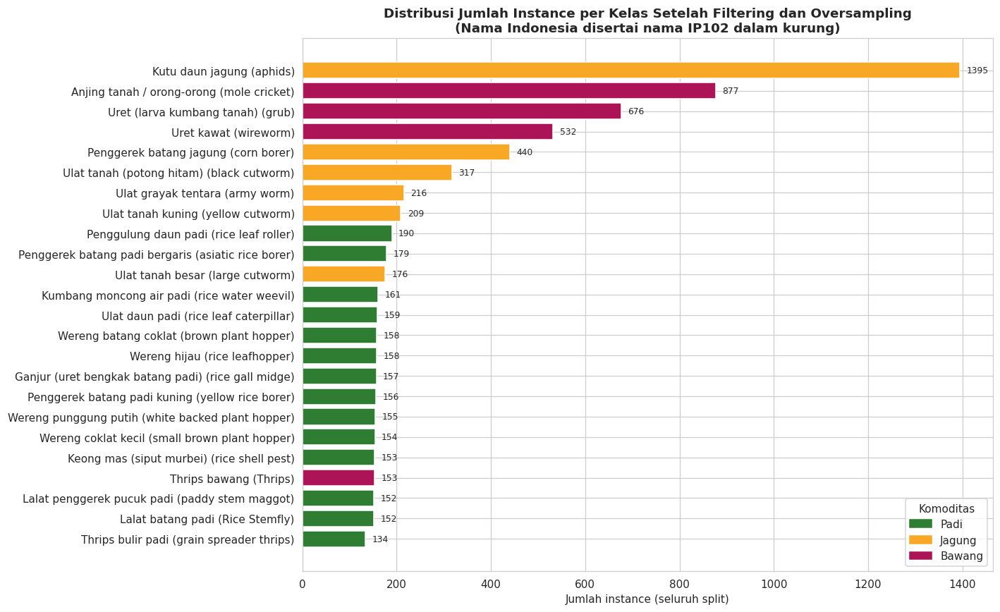

Rasio ketimpangan final: 10.4x (aphids vs grain spreader thrips)


In [ ]:
class_counts_subset = annotations_subset.groupby(["class_id", "class_name", "komoditas"]).size().reset_index(name="jumlah_instance").sort_values("jumlah_instance", ascending=False)
class_counts_subset["label_tampilan"] = class_counts_subset["class_id"].apply(to_id_name)

fig, ax = plt.subplots(figsize=(13, 8))
bars = ax.barh(class_counts_subset["label_tampilan"], class_counts_subset["jumlah_instance"], color=[COMMODITY_COLOR[c] for c in class_counts_subset["komoditas"]])
for bar, val in zip(bars, class_counts_subset["jumlah_instance"]):
    ax.text(val + class_counts_subset["jumlah_instance"].max() * 0.01, bar.get_y() + bar.get_height() / 2, str(val), va="center", fontsize=8)
handles = [plt.Rectangle((0, 0), 1, 1, color=v) for v in COMMODITY_COLOR.values()]
ax.legend(handles, COMMODITY_COLOR.keys(), title="Komoditas", loc="lower right")
ax.set_xlabel("Jumlah instance (seluruh split)")
ax.set_title("Distribusi Jumlah Instance per Kelas Setelah Filtering dan Oversampling\n(Nama Indonesia disertai nama IP102 dalam kurung)")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(f"{LOCAL_WORK_DIR}/plots/eda_after_class_distribution.png", bbox_inches="tight")
plt.show()

min_row = class_counts_subset.loc[class_counts_subset["jumlah_instance"].idxmin()]
max_row = class_counts_subset.loc[class_counts_subset["jumlah_instance"].idxmax()]
print("Rasio ketimpangan final: {:.1f}x ({} vs {})".format(max_row["jumlah_instance"] / max(min_row["jumlah_instance"], 1), max_row["class_name"], min_row["class_name"]))

### 5.1 Konsistensi Distribusi Antar Split

Sebelum melangkah lebih jauh, penting untuk memverifikasi bahwa proporsi kelas pada split train, val, dan test relatif konsisten (tidak ada kelas yang secara kebetulan hanya muncul dominan pada satu split saja), karena ketidakkonsistenan ini dapat menyebabkan evaluasi yang menyesatkan.

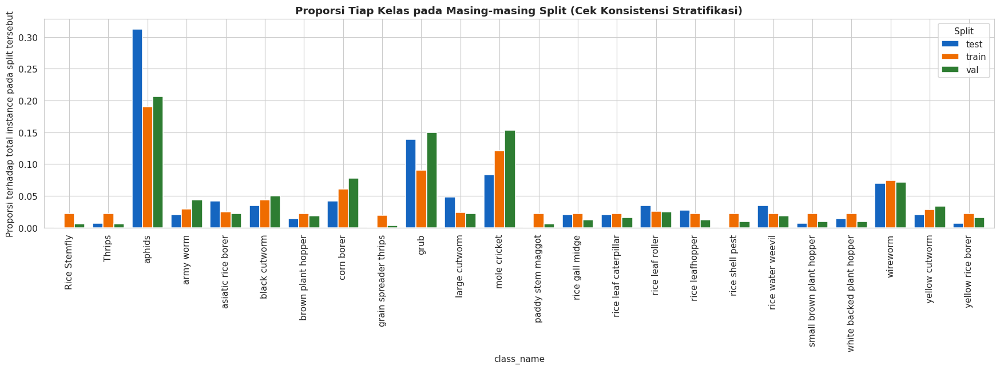

Lima kelas dengan variasi proporsi antar-split tertinggi (berpotensi kurang representatif pada salah satu split):
class_name
aphids           0.066406
mole cricket     0.034932
grub             0.031841
corn borer       0.018234
large cutworm    0.014856
dtype: float64


In [ ]:
split_class_counts = annotations_subset.groupby(["split", "class_name"]).size().unstack(fill_value=0)
split_class_proportion = split_class_counts.div(split_class_counts.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(16, 6))
split_class_proportion.T.plot(kind="bar", ax=ax, color=["#1565C0", "#EF6C00", "#2E7D32"], width=0.8)
ax.set_ylabel("Proporsi terhadap total instance pada split tersebut")
ax.set_title("Proporsi Tiap Kelas pada Masing-masing Split (Cek Konsistensi Stratifikasi)")
ax.legend(title="Split")
ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.savefig(f"{LOCAL_WORK_DIR}/plots/eda_after_split_consistency.png", bbox_inches="tight")
plt.show()

split_std = split_class_proportion.std(axis=0).sort_values(ascending=False)
print("Lima kelas dengan variasi proporsi antar-split tertinggi (berpotensi kurang representatif pada salah satu split):")
print(split_std.head(5))

### 5.2 Jumlah Objek per Gambar (Dataset Final)

Statistik jumlah objek per gambar pada dataset final:
count    6181.000000
mean        1.166316
std         0.684907
min         1.000000
25%         1.000000
50%         1.000000
75%         1.000000
max        10.000000
Name: jumlah_objek, dtype: float64


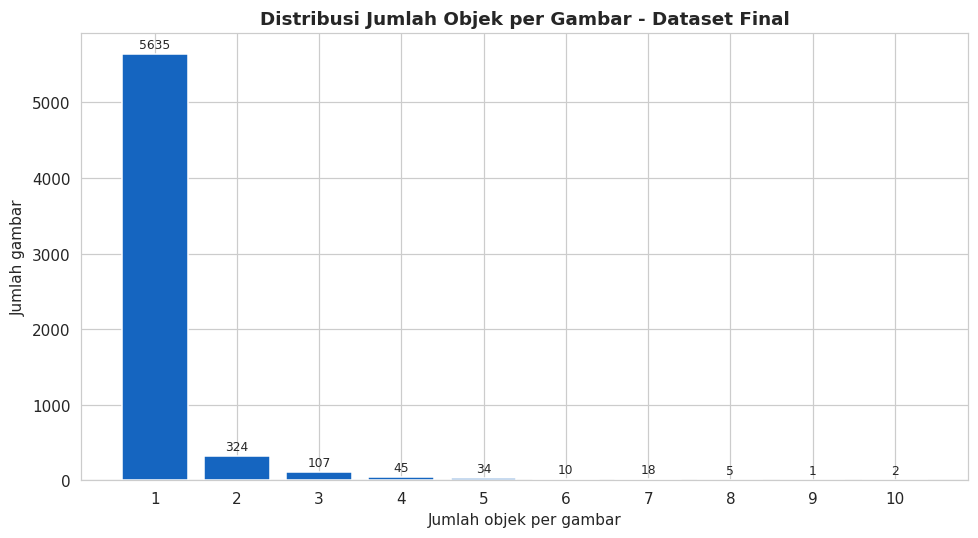

Persentase gambar dengan lebih dari satu objek: 8.8%
Insight: gambar dengan banyak objek sekaligus lebih menantang bagi model karena berpotensi terjadi tumpang tindih (occlusion) antar bounding box.


In [ ]:
objects_per_image_subset = annotations_subset.groupby(["image", "split"]).size().reset_index(name="jumlah_objek")
print("Statistik jumlah objek per gambar pada dataset final:")
print(objects_per_image_subset["jumlah_objek"].describe())

fig, ax = plt.subplots(figsize=(9, 5))
counts = objects_per_image_subset["jumlah_objek"].value_counts().sort_index()
bars = ax.bar(counts.index.astype(str), counts.values, color="#1565C0")
ax.bar_label(bars, padding=2, fontsize=8)
ax.set_xlabel("Jumlah objek per gambar")
ax.set_ylabel("Jumlah gambar")
ax.set_title("Distribusi Jumlah Objek per Gambar - Dataset Final")
plt.tight_layout()
plt.savefig(f"{LOCAL_WORK_DIR}/plots/eda_after_objects_per_image.png", bbox_inches="tight")
plt.show()

multi_object_pct = 100 * (objects_per_image_subset["jumlah_objek"] > 1).mean()
print(f"Persentase gambar dengan lebih dari satu objek: {multi_object_pct:.1f}%")
print("Insight: gambar dengan banyak objek sekaligus lebih menantang bagi model karena berpotensi terjadi tumpang tindih (occlusion) antar bounding box.")

### 5.3 Kecenderungan Posisi Objek dalam Frame (Spatial Bias)

Peta panas berikut menunjukkan di bagian mana objek paling sering muncul dalam frame. Kecenderungan posisi yang terlalu terpusat (bias ke tengah) dapat menjadi sinyal bahwa model kurang terlatih mengenali objek di tepi frame, yang relevan mengingat posisi hama pada wadah perangkap di lapangan tidak dapat dikendalikan secara pasti.

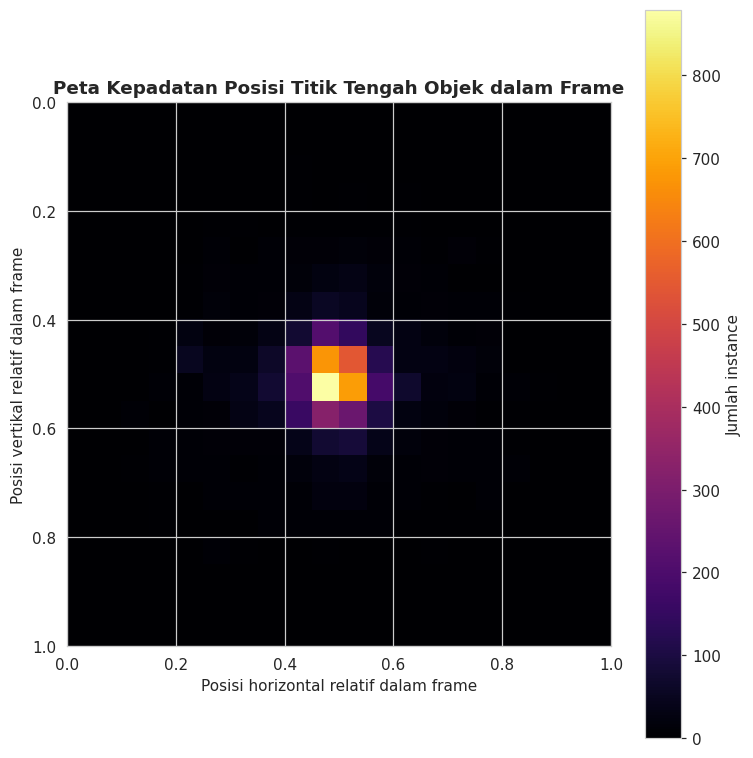

Persentase objek yang berada pada 40% area tengah frame: 85.9%
Insight: terdapat kecenderungan cukup kuat objek terpusat di tengah frame pada data latih.
Parameter augmentasi translate=0.10 pada konfigurasi training membantu mengurangi risiko bias ini.


In [ ]:
fig, ax = plt.subplots(figsize=(7, 7))
heatmap_data, _, _ = np.histogram2d(annotations_subset["x_center"], annotations_subset["y_center"], bins=20, range=[[0, 1], [0, 1]])
im = ax.imshow(heatmap_data.T, origin="upper", cmap="inferno", extent=[0, 1, 1, 0])
ax.set_xlabel("Posisi horizontal relatif dalam frame")
ax.set_ylabel("Posisi vertikal relatif dalam frame")
ax.set_title("Peta Kepadatan Posisi Titik Tengah Objek dalam Frame")
plt.colorbar(im, ax=ax, label="Jumlah instance")
plt.tight_layout()
plt.savefig(f"{LOCAL_WORK_DIR}/plots/eda_after_spatial_heatmap.png", bbox_inches="tight")
plt.show()

center_region_pct = 100 * (
    (annotations_subset["x_center"].between(0.3, 0.7)) & (annotations_subset["y_center"].between(0.3, 0.7))
).mean()
print(f"Persentase objek yang berada pada 40% area tengah frame: {center_region_pct:.1f}%")
if center_region_pct > 60:
    print("Insight: terdapat kecenderungan cukup kuat objek terpusat di tengah frame pada data latih.")
    print("Parameter augmentasi translate=0.10 pada konfigurasi training membantu mengurangi risiko bias ini.")

### 5.4 Rasio Aspek Bounding Box per Kelas

Rasio aspek (lebar/tinggi) mencerminkan bentuk tubuh khas tiap jenis hama pada citra: nilai mendekati 1 menandakan bentuk relatif bulat/kompak, sementara nilai jauh dari 1 menandakan bentuk memanjang (horizontal jika >1, vertikal jika <1).

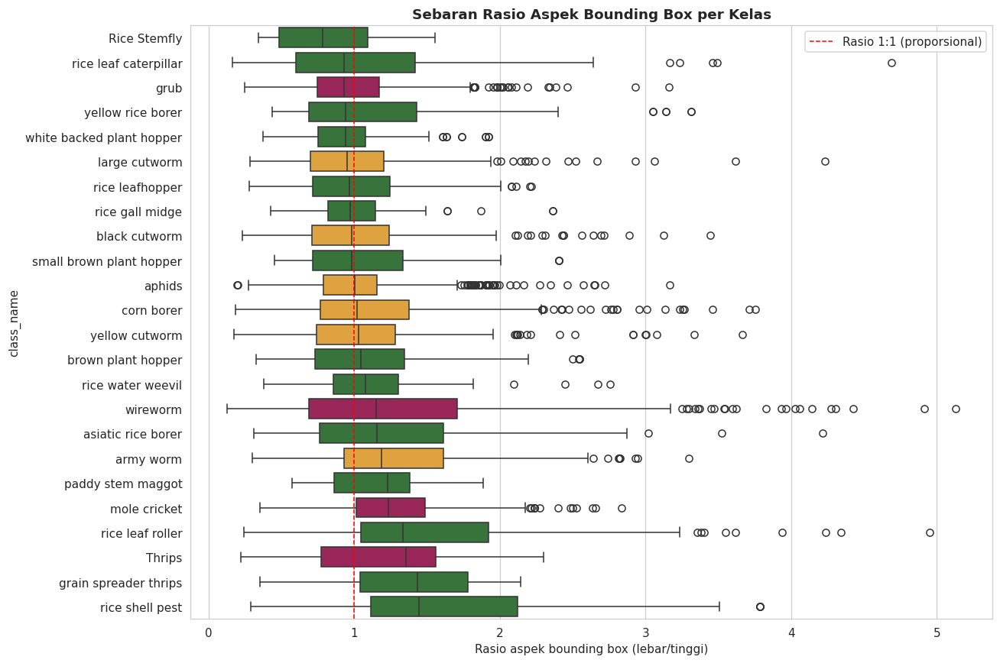

In [ ]:
fig, ax = plt.subplots(figsize=(12, 8))
order = annotations_subset.groupby("class_name")["aspect_ratio"].median().sort_values().index
sns.boxplot(data=annotations_subset, y="class_name", x="aspect_ratio", order=order,
            palette=[COMMODITY_COLOR[dict(zip(SUBSET_NAMES, SUBSET_COMMODITY))[c]] for c in order], ax=ax)
ax.axvline(1.0, color="red", linestyle="--", linewidth=1, label="Rasio 1:1 (proporsional)")
ax.set_xlabel("Rasio aspek bounding box (lebar/tinggi)")
ax.set_title("Sebaran Rasio Aspek Bounding Box per Kelas")
ax.legend()
plt.tight_layout()
plt.savefig(f"{LOCAL_WORK_DIR}/plots/eda_after_aspect_ratio_boxplot.png", bbox_inches="tight")
plt.show()

### 5.5 Kemunculan Bersama Antar Kelas (Class Co-occurrence)

Analisis ini mengungkap pasangan kelas yang cenderung muncul bersama dalam satu citra yang sama, memberi gambaran tentang konteks/kondisi lapangan saat data dikumpulkan (misalnya, apakah beberapa jenis hama sering tertangkap kamera secara bersamaan).

In [ ]:
class_names_present = sorted(annotations_subset["class_id"].unique())
co_occurrence = pd.DataFrame(0, index=[SUBSET_NAMES[i] for i in class_names_present], columns=[SUBSET_NAMES[i] for i in class_names_present])

for image_name, group in annotations_subset.groupby("image"):
    classes_in_image = group["class_id"].unique()
    if len(classes_in_image) < 2:
        continue
    for ci in classes_in_image:
        for cj in classes_in_image:
            if ci != cj:
                co_occurrence.loc[SUBSET_NAMES[ci], SUBSET_NAMES[cj]] += 1

total_co_occurrence = int(co_occurrence.values.sum() / 2)
print(f"Total kejadian kemunculan bersama antar kelas berbeda dalam satu citra: {total_co_occurrence}")

if total_co_occurrence > 0:
    fig, ax = plt.subplots(figsize=(11, 10))
    sns.heatmap(co_occurrence, cmap="YlOrRd", annot=False, ax=ax, cbar_kws={"label": "Jumlah kemunculan bersama"})
    ax.set_title("Peta Kemunculan Bersama Antar Kelas dalam Satu Citra")
    plt.tight_layout()
    plt.savefig(f"{LOCAL_WORK_DIR}/plots/eda_after_co_occurrence.png", bbox_inches="tight")
    plt.show()
else:
    print("Tidak ditemukan kemunculan bersama antar kelas berbeda pada dataset ini -> mayoritas citra bersifat single-class per gambar.")

Total kejadian kemunculan bersama antar kelas berbeda dalam satu citra: 0
Tidak ditemukan kemunculan bersama antar kelas berbeda pada dataset ini -> mayoritas citra bersifat single-class per gambar.


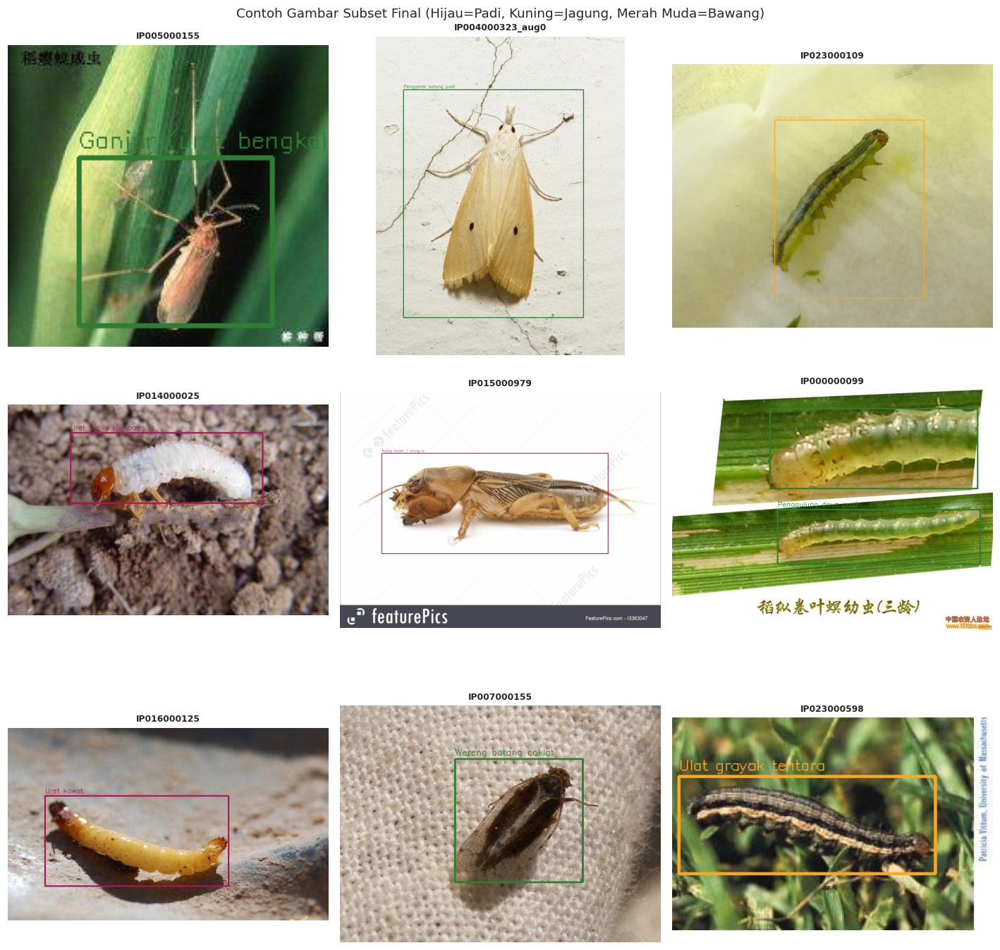

In [ ]:
sample_subset_labels = random.sample(list(Path(subset_train_lbl).glob("*.txt")), min(9, len(list(Path(subset_train_lbl).glob("*.txt")))))
fig, axes = plt.subplots(3, 3, figsize=(13, 13))
for ax, lbl_path in zip(axes.flatten(), sample_subset_labels):
    img_path = next(Path(subset_train_img).glob(f"{lbl_path.stem}.*"))
    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    h_img, w_img = img.shape[:2]
    for class_id, x, y, w, h in parse_label_file(lbl_path):
        x1, y1, x2, y2 = [int(v) for v in yolo_to_xyxy(x, y, w, h, w_img, h_img)]
        color = tuple(int(COMMODITY_COLOR[SUBSET_COMMODITY[class_id]].lstrip("#")[i:i+2], 16) for i in (0, 2, 4))
        cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
        cv2.putText(img, SUBSET_NAME_ID[class_id][:22], (x1, max(y1 - 6, 10)), cv2.FONT_HERSHEY_SIMPLEX, 0.45, color, 1)
    ax.imshow(img)
    ax.set_title(lbl_path.stem, fontsize=8)
    ax.axis("off")
plt.suptitle("Contoh Gambar Subset Final (Hijau=Padi, Kuning=Jagung, Merah Muda=Bawang)", fontsize=12)
plt.tight_layout()
plt.savefig(f"{LOCAL_WORK_DIR}/plots/eda_after_sample_images.png", bbox_inches="tight")
plt.show()

### 5.6 Karakteristik Citra Aktual (Dimensi dan Kecerahan per Komoditas)

Berbeda dengan Bagian 3 yang menggunakan asumsi kanvas 640x640 pada dataset mentah, analisis berikut menggunakan **dimensi piksel sesungguhnya** dari citra pada dataset final, dipecah per komoditas untuk melihat apakah ada perbedaan sistematis kondisi pengambilan foto antar kelompok hama.

Mengukur karakteristik citra final:   0%|          | 0/300 [00:00<?, ?it/s]

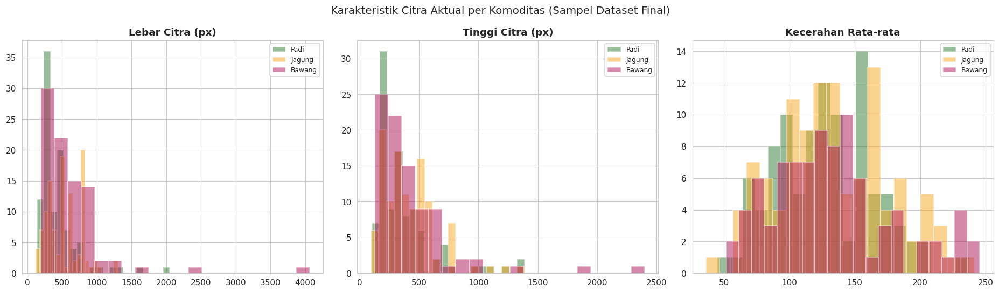

           width        height        brightness      
            mean    std   mean    std       mean   std
komoditas                                             
Bawang     607.3  498.6  433.3  338.5      133.3  46.5
Jagung     534.1  247.0  418.6  226.4      134.4  43.1
Padi       449.5  292.1  374.9  256.3      127.2  37.1


In [ ]:
image_char_records = []
sample_files_per_commodity = list(Path(subset_train_lbl).glob("*.txt"))
for lbl_path in tqdm(random.sample(sample_files_per_commodity, min(300, len(sample_files_per_commodity))), desc="Mengukur karakteristik citra final"):
    boxes = parse_label_file(lbl_path)
    if not boxes:
        continue
    dominant_commodity = SUBSET_COMMODITY[boxes[0][0]]
    img_path = next(Path(subset_train_img).glob(f"{lbl_path.stem}.*"), None)
    if img_path is None:
        continue
    img = cv2.imread(str(img_path))
    if img is None:
        continue
    h_img, w_img = img.shape[:2]
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    image_char_records.append({"komoditas": dominant_commodity, "width": w_img, "height": h_img, "brightness": gray.mean()})

image_char_df = pd.DataFrame(image_char_records)
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, col, title in zip(axes, ["width", "height", "brightness"], ["Lebar Citra (px)", "Tinggi Citra (px)", "Kecerahan Rata-rata"]):
    for komoditas, color in COMMODITY_COLOR.items():
        subset = image_char_df[image_char_df["komoditas"] == komoditas][col]
        if len(subset) > 0:
            ax.hist(subset, bins=20, alpha=0.5, label=komoditas, color=color)
    ax.set_title(title)
    ax.legend(fontsize=8)
plt.suptitle("Karakteristik Citra Aktual per Komoditas (Sampel Dataset Final)", fontsize=13)
plt.tight_layout()
plt.savefig(f"{LOCAL_WORK_DIR}/plots/eda_after_image_characteristics_per_commodity.png", bbox_inches="tight")
plt.show()

print(image_char_df.groupby("komoditas")[["width", "height", "brightness"]].agg(["mean", "std"]).round(1))

### 5.7 Korelasi Antar Fitur Numerik Bounding Box

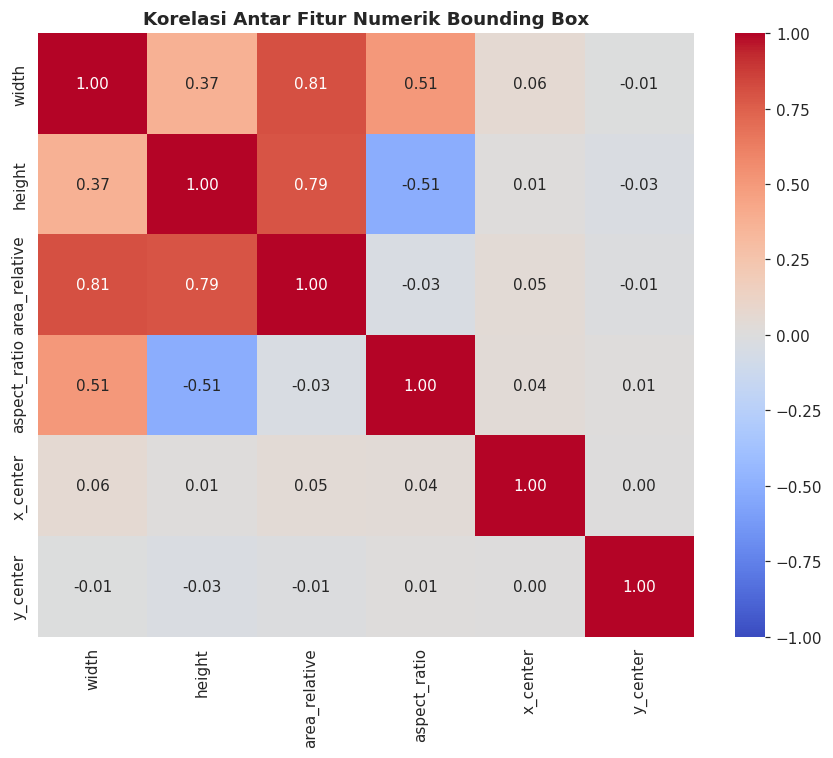

Pasangan fitur dengan korelasi kuat (|r| > 0.5):
width   area_relative    0.811886
height  area_relative    0.793361
        aspect_ratio    -0.508164
width   aspect_ratio     0.506301
dtype: float64


In [ ]:
numeric_features = annotations_subset[["width", "height", "area_relative", "aspect_ratio", "x_center", "y_center"]]
correlation_matrix = numeric_features.corr()

fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax, vmin=-1, vmax=1)
ax.set_title("Korelasi Antar Fitur Numerik Bounding Box")
plt.tight_layout()
plt.savefig(f"{LOCAL_WORK_DIR}/plots/eda_after_correlation_matrix.png", bbox_inches="tight")
plt.show()

strong_corr = correlation_matrix.where(np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)).stack()
strong_corr = strong_corr[strong_corr.abs() > 0.5].sort_values(key=abs, ascending=False)
print("Pasangan fitur dengan korelasi kuat (|r| > 0.5):")
print(strong_corr if len(strong_corr) > 0 else "Tidak ditemukan korelasi kuat antar fitur.")

### 5.8 Konsistensi Ukuran Objek Antar Split

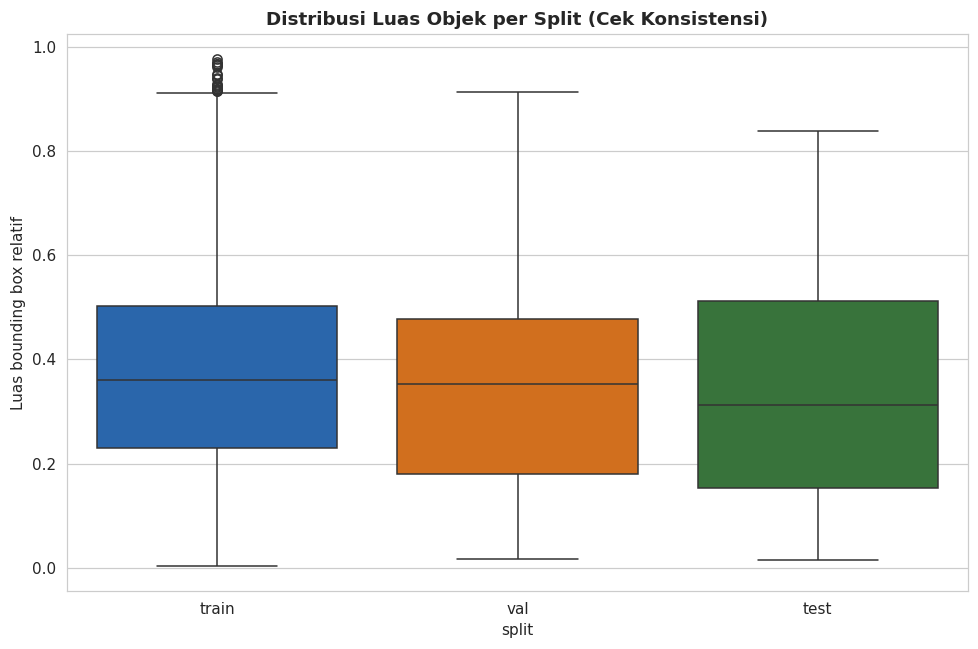

           mean    median       std
split                              
test   0.335349  0.312738  0.222583
train  0.371931  0.359748  0.197415
val    0.344739  0.352481  0.192359
Ukuran objek relatif konsisten antar ketiga split.


In [ ]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.boxplot(data=annotations_subset, x="split", y="area_relative", order=["train", "val", "test"], palette=["#1565C0", "#EF6C00", "#2E7D32"], ax=ax)
ax.set_ylabel("Luas bounding box relatif")
ax.set_title("Distribusi Luas Objek per Split (Cek Konsistensi)")
plt.tight_layout()
plt.savefig(f"{LOCAL_WORK_DIR}/plots/eda_after_area_by_split.png", bbox_inches="tight")
plt.show()

area_by_split = annotations_subset.groupby("split")["area_relative"].agg(["mean", "median", "std"])
print(area_by_split)
if area_by_split["mean"].std() / area_by_split["mean"].mean() > 0.2:
    print("Peringatan: rata-rata ukuran objek antar split berbeda cukup signifikan, dapat memengaruhi validitas evaluasi.")
else:
    print("Ukuran objek relatif konsisten antar ketiga split.")

### 5.9 Statistik Ringkas per Kelas (Coefficient of Variation)

Coefficient of variation (CV = std/mean) mengukur seberapa bervariasi ukuran objek di dalam satu kelas yang sama. Nilai CV tinggi menandakan kelas tersebut memiliki variasi ukuran besar (mencakup individu muda dan dewasa sekaligus), yang relevan untuk mempertimbangkan kompleksitas estimasi stadium pada tahap pengembangan berikutnya.

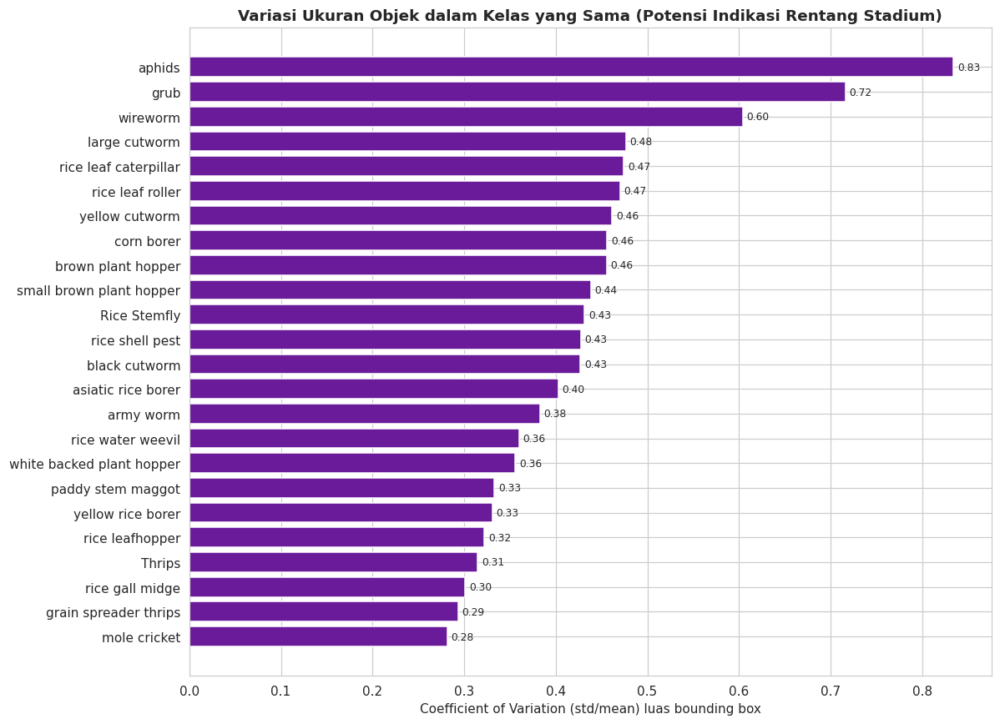

Kelas dengan variasi ukuran tertinggi (kandidat prioritas untuk studi estimasi stadium lanjutan): ['aphids', 'grub']


In [ ]:
class_stats = annotations_subset.groupby("class_name")["area_relative"].agg(["mean", "std", "count"]).reset_index()
class_stats["cv"] = class_stats["std"] / class_stats["mean"]
class_stats = class_stats.sort_values("cv", ascending=False)

fig, ax = plt.subplots(figsize=(11, 8))
bars = ax.barh(class_stats["class_name"], class_stats["cv"], color="#6A1B9A")
ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=8)
ax.set_xlabel("Coefficient of Variation (std/mean) luas bounding box")
ax.set_title("Variasi Ukuran Objek dalam Kelas yang Sama (Potensi Indikasi Rentang Stadium)")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(f"{LOCAL_WORK_DIR}/plots/eda_after_coefficient_variation.png", bbox_inches="tight")
plt.show()

high_cv_classes = class_stats[class_stats["cv"] > class_stats["cv"].median() * 1.5]["class_name"].tolist()
print("Kelas dengan variasi ukuran tertinggi (kandidat prioritas untuk studi estimasi stadium lanjutan):", high_cv_classes[:5])

### 5.10 Distribusi Warna Dominan per Komoditas

Analisis histogram warna (rata-rata nilai per kanal RGB) membantu memahami karakteristik visual umum tiap kelompok komoditas, yang relevan untuk menilai seberapa besar variasi visual yang perlu ditangani oleh model, serta sebagai referensi tambahan saat menilai kesesuaian pencahayaan pada kondisi lapangan (lampu UV pada malam hari) dibandingkan foto referensi pada dataset ini.

Menganalisis warna dominan:   0%|          | 0/200 [00:00<?, ?it/s]

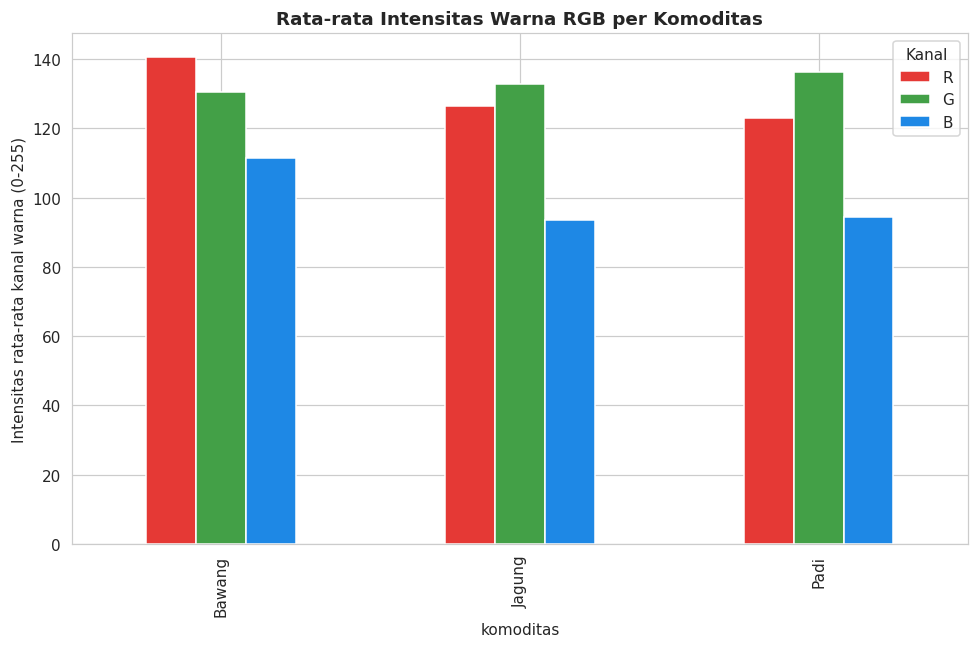

               R      G      B
komoditas                     
Bawang     140.4  130.3  111.4
Jagung     126.6  132.9   93.5
Padi       123.1  136.3   94.5


In [ ]:
color_records = []
sample_for_color = list(Path(subset_train_lbl).glob("*.txt"))
for lbl_path in tqdm(random.sample(sample_for_color, min(200, len(sample_for_color))), desc="Menganalisis warna dominan"):
    boxes = parse_label_file(lbl_path)
    if not boxes:
        continue
    dominant_commodity = SUBSET_COMMODITY[boxes[0][0]]
    img_path = next(Path(subset_train_img).glob(f"{lbl_path.stem}.*"), None)
    if img_path is None:
        continue
    img = cv2.imread(str(img_path))
    if img is None:
        continue
    b, g, r = cv2.mean(img)[:3]
    color_records.append({"komoditas": dominant_commodity, "R": r, "G": g, "B": b})

color_df = pd.DataFrame(color_records)
fig, ax = plt.subplots(figsize=(9, 6))
color_means = color_df.groupby("komoditas")[["R", "G", "B"]].mean()
color_means.plot(kind="bar", ax=ax, color=["#E53935", "#43A047", "#1E88E5"])
ax.set_ylabel("Intensitas rata-rata kanal warna (0-255)")
ax.set_title("Rata-rata Intensitas Warna RGB per Komoditas")
ax.legend(title="Kanal")
plt.tight_layout()
plt.savefig(f"{LOCAL_WORK_DIR}/plots/eda_after_color_distribution.png", bbox_inches="tight")
plt.show()

print(color_means.round(1))

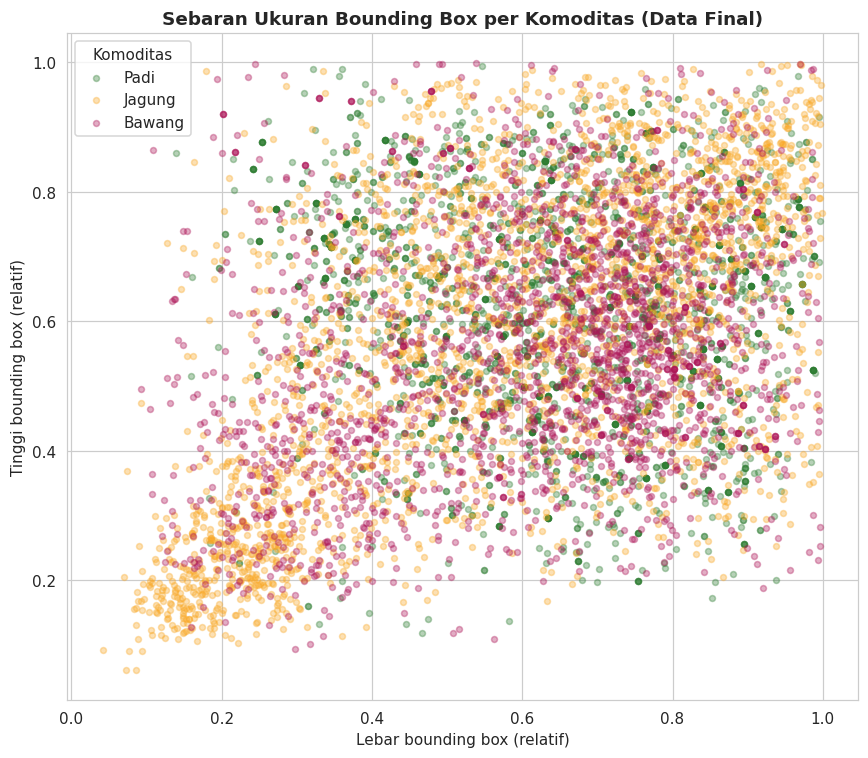

In [ ]:
fig, ax = plt.subplots(figsize=(8, 7))
for komoditas, color in COMMODITY_COLOR.items():
    subset = annotations_subset[annotations_subset["komoditas"] == komoditas]
    ax.scatter(subset["width"], subset["height"], alpha=0.35, s=15, color=color, label=komoditas)
ax.set_xlabel("Lebar bounding box (relatif)")
ax.set_ylabel("Tinggi bounding box (relatif)")
ax.set_title("Sebaran Ukuran Bounding Box per Komoditas (Data Final)")
ax.legend(title="Komoditas")
plt.tight_layout()
plt.savefig(f"{LOCAL_WORK_DIR}/plots/eda_after_bbox_scatter.png", bbox_inches="tight")
plt.show()

## 6. Ilustrasi Augmentasi Data

Parameter augmentasi yang diterapkan Ultralytics secara otomatis selama training (lihat `AUGMENTATION_HYPERPARAMS` pada Bagian 2), diilustrasikan pada satu citra contoh.

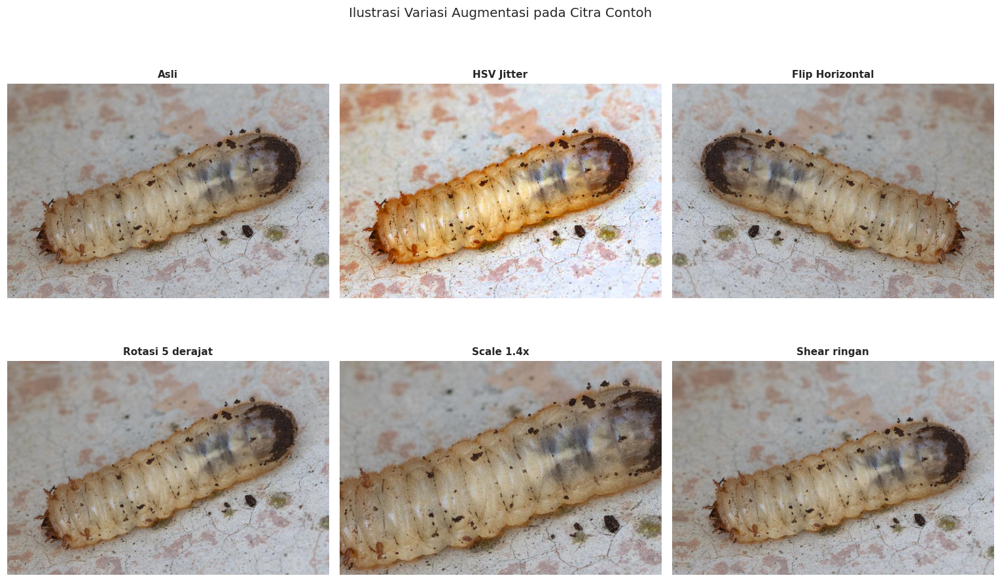

In [ ]:
def apply_manual_augmentation_preview(img):
    variations = {"Asli": img.copy()}
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV).astype(np.float32)
    hsv[..., 1] = np.clip(hsv[..., 1] * 1.7, 0, 255)
    hsv[..., 2] = np.clip(hsv[..., 2] * 1.3, 0, 255)
    variations["HSV Jitter"] = cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2RGB)
    variations["Flip Horizontal"] = cv2.flip(img, 1)
    h, w = img.shape[:2]
    variations["Rotasi 5 derajat"] = cv2.warpAffine(img, cv2.getRotationMatrix2D((w / 2, h / 2), 5, 1.0), (w, h), borderMode=cv2.BORDER_REFLECT)
    variations["Scale 1.4x"] = cv2.warpAffine(img, cv2.getRotationMatrix2D((w / 2, h / 2), 0, 1.4), (w, h), borderMode=cv2.BORDER_REFLECT)
    shear_matrix = np.float32([[1, 0.05, 0], [0.05, 1, 0]])
    variations["Shear ringan"] = cv2.warpAffine(img, shear_matrix, (w, h), borderMode=cv2.BORDER_REFLECT)
    return variations

sample_aug_source = random.choice(list(Path(subset_train_img).glob("*")))
img_sample = cv2.cvtColor(cv2.imread(str(sample_aug_source)), cv2.COLOR_BGR2RGB)
variations = apply_manual_augmentation_preview(img_sample)

fig, axes = plt.subplots(2, 3, figsize=(14, 9))
for ax, (title, im) in zip(axes.flatten(), variations.items()):
    ax.imshow(im)
    ax.set_title(title, fontsize=10)
    ax.axis("off")
plt.suptitle("Ilustrasi Variasi Augmentasi pada Citra Contoh", fontsize=13)
plt.tight_layout()
plt.savefig(f"{LOCAL_WORK_DIR}/plots/augmentation_preview.png", bbox_inches="tight")
plt.show()

## 7. Pelatihan Model (Resume-Safe)

Perbaikan utama pada bagian ini dibandingkan sesi sebelumnya: setiap model diperiksa statusnya terlebih dahulu sebelum dilatih.

- **completed**: `best.pt` sudah ada -> model dilewati sepenuhnya.
- **interrupted**: `last.pt` ada tetapi `best.pt` belum ada -> pelatihan **dilanjutkan** dari checkpoint terakhir menggunakan `resume=True`, bukan mengulang dari epoch 0.
- **not_started**: belum ada checkpoint sama sekali -> pelatihan dimulai dari bobot pretrained COCO.

Dengan mekanisme ini, insiden seperti terputus di epoch 44 pada sesi sebelumnya tidak akan menghilangkan progres yang telah dicapai.

**Pembersihan memori sebelum training**: sesi sebelumnya sempat mengalami crash akibat RAM sistem penuh. Sebelum training dimulai, seluruh variabel besar dari tahap eksplorasi data (dataframe anotasi, sampel citra, dsb.) dibersihkan secara eksplisit dari memori terlebih dahulu.

In [ ]:
variables_to_clear = [
    "annotations_subset", "image_char_df", "color_df", "class_counts_subset",
    "per_class_records", "co_occurrence", "objects_per_image_subset",
]
cleared = []
for var_name in variables_to_clear:
    if var_name in globals():
        del globals()[var_name]
        cleared.append(var_name)

gc.collect()
torch.cuda.empty_cache()
print("Variabel besar yang dibersihkan dari memori sebelum training:", cleared if cleared else "(tidak ada yang perlu dibersihkan)")
print("Memori sistem dan cache GPU telah dikosongkan, siap memulai training.")

Variabel besar yang dibersihkan dari memori sebelum training: ['annotations_subset', 'image_char_df', 'color_df', 'class_counts_subset', 'co_occurrence', 'objects_per_image_subset']
Memori sistem dan cache GPU telah dikosongkan, siap memulai training.


In [ ]:
import json

def get_run_name(model_filename):
    return model_filename.replace(".pt", "")

def get_run_dir(model_filename):
    return Path(DRIVE_OUTPUT_ROOT) / "train_runs" / get_run_name(model_filename)

def get_progress_path(model_filename):
    return get_run_dir(model_filename) / "epoch_progress.json"

def is_resumable_checkpoint(pt_path):
    try:
        ckpt = torch.load(pt_path, map_location="cpu", weights_only=False)
    except Exception:
        return False
    return ckpt.get("optimizer") is not None and ckpt.get("epoch") is not None

def get_completed_epochs(model_filename):
    progress_path = get_progress_path(model_filename)
    if progress_path.exists():
        try:
            return json.loads(progress_path.read_text()).get("completed_epochs", 0)
        except Exception:
            pass
    results_csv = get_run_dir(model_filename) / "results.csv"
    if results_csv.exists():
        df_check = pd.read_csv(results_csv)
        df_check.columns = [c.strip() for c in df_check.columns]
        if "epoch" in df_check.columns and len(df_check) > 0:
            return int(df_check["epoch"].iloc[-1])
    return 0

def set_completed_epochs(model_filename, completed_epochs):
    progress_path = get_progress_path(model_filename)
    progress_path.parent.mkdir(parents=True, exist_ok=True)
    progress_path.write_text(json.dumps({"completed_epochs": int(completed_epochs)}))

def stage_early_stopped(results_csv, patience):
    if not results_csv.exists():
        return False
    df_check = pd.read_csv(results_csv)
    df_check.columns = [c.strip() for c in df_check.columns]
    if "epoch" not in df_check.columns or len(df_check) == 0:
        return False
    map_cols = [c for c in df_check.columns if "map50-95" in c.lower()] or \
               [c for c in df_check.columns if "map50" in c.lower()]
    if not map_cols:
        return False
    last_epoch = int(df_check["epoch"].iloc[-1])
    best_epoch = int(df_check["epoch"].iloc[df_check[map_cols[0]].idxmax()])
    return (last_epoch - best_epoch) >= patience

def get_training_status(model_filename):
    run_dir = get_run_dir(model_filename)
    target_epochs = get_target_epochs(model_filename)
    if not (run_dir / "weights" / "last.pt").exists():
        return "not_started"
    if get_completed_epochs(model_filename) >= target_epochs:
        return "completed"
    if stage_early_stopped(run_dir / "results.csv", PATIENCE):
        return "completed"
    return "interrupted"

def patch_resume_checkpoint(last_pt_path, new_epochs):
    ckpt = torch.load(last_pt_path, map_location="cpu", weights_only=False)
    train_args = ckpt.get("train_args", {})
    changed = []
    if train_args.get("epochs") != new_epochs:
        changed.append(f"epochs {train_args.get('epochs')} -> {new_epochs}")
        train_args["epochs"] = new_epochs
    if changed:
        ckpt["train_args"] = train_args
        torch.save(ckpt, last_pt_path)
    return changed

print("Status seluruh model SEBELUM sesi training ini dimulai:")
for model_filename in MODEL_LIST:
    target_epochs = get_target_epochs(model_filename)
    print(f" - {get_run_name(model_filename)}: {get_training_status(model_filename)} "
          f"({get_completed_epochs(model_filename)}/{target_epochs} epoch tercatat)")

Status seluruh model SEBELUM sesi training ini dimulai:
 - yolo11l: completed (50/50 epoch tercatat)
 - yolov8m: completed (45/45 epoch tercatat)
 - yolo11m: interrupted (43/45 epoch tercatat)


In [ ]:
def train_single_model(model_filename):
    run_name = get_run_name(model_filename)
    run_dir = get_run_dir(model_filename)
    target_epochs = get_target_epochs(model_filename)
    status = get_training_status(model_filename)
    start_time = time.time()
    batch_for_this_model = BATCH_SIZE_PER_MODEL.get(model_filename, BATCH_SIZE)
    was_true_resume = False
    prior_completed_epochs = 0

    if status == "completed":
        print(f"[{run_name}] status: completed -> dilewati.")
        return None

    elif status == "interrupted":
        last_pt_path = run_dir / "weights" / "last.pt"
        prior_completed_epochs = get_completed_epochs(model_filename)
        remaining_epochs = max(1, target_epochs - prior_completed_epochs)
        print(f"[{run_name}] status: interrupted ({prior_completed_epochs}/{target_epochs} epoch tercatat) "
              f"-> sisa {remaining_epochs} epoch.")

        if is_resumable_checkpoint(last_pt_path):
            print(f"[{run_name}] checkpoint resumable penuh -> pakai resume=True.")
            patched = patch_resume_checkpoint(last_pt_path, target_epochs)
            if patched:
                print(f"[{run_name}] Target epoch pada checkpoint disesuaikan: {', '.join(patched)}")
            model = YOLO(str(last_pt_path))
            model.train(resume=True)
            was_true_resume = True
        else:
            print(f"[{run_name}] checkpoint sudah ter-strip -> lanjutkan training baru dari "
                  f"bobot terakhir untuk {remaining_epochs} epoch sisa (bukan resume=True).")
            model = YOLO(str(last_pt_path))
            model.train(
                data=subset_yaml_path, epochs=remaining_epochs, imgsz=IMG_SIZE,
                batch=batch_for_this_model, patience=PATIENCE,
                project=f"{DRIVE_OUTPUT_ROOT}/train_runs", name=run_name, exist_ok=True,
                seed=42, verbose=False, resume=False, **AUGMENTATION_HYPERPARAMS,
            )
            was_true_resume = False
    else:
        print(f"[{run_name}] status: not_started -> memulai training baru...")
        model = YOLO(model_filename)
        print(f"[{run_name}] menggunakan batch size = {batch_for_this_model}, target = {target_epochs} epoch")
        train_kwargs = dict(
            data=subset_yaml_path, epochs=target_epochs, imgsz=IMG_SIZE, batch=batch_for_this_model, patience=PATIENCE,
            project=f"{DRIVE_OUTPUT_ROOT}/train_runs", name=run_name, exist_ok=True, seed=42, verbose=False,
            **AUGMENTATION_HYPERPARAMS,
        )
        try:
            model.train(**train_kwargs)
        except TypeError as e:
            print(f"[{run_name}] Parameter tidak dikenali oleh versi Ultralytics terpasang ({e}).")
            print(f"[{run_name}] Mencoba ulang tanpa parameter 'multi_scale' sebagai fallback...")
            train_kwargs.pop("multi_scale", None)
            model.train(**train_kwargs)
        except torch.cuda.OutOfMemoryError:
            print(f"[{run_name}] GPU/RAM kehabisan memori pada batch={batch_for_this_model}. Mencoba ulang dengan batch diperkecil separuh...")
            torch.cuda.empty_cache()
            gc.collect()
            train_kwargs["batch"] = max(2, batch_for_this_model // 2)
            model.train(**train_kwargs)
        was_true_resume = True

    results_csv = run_dir / "results.csv"
    if results_csv.exists():
        df_check = pd.read_csv(results_csv)
        df_check.columns = [c.strip() for c in df_check.columns]
        if "epoch" in df_check.columns and len(df_check) > 0:
            stage_last_epoch = int(df_check["epoch"].iloc[-1])
            total_completed = stage_last_epoch if was_true_resume else prior_completed_epochs + stage_last_epoch
            set_completed_epochs(model_filename, min(total_completed, target_epochs))
            print(f"[{run_name}] progres tercatat: {min(total_completed, target_epochs)}/{target_epochs} epoch total.")

    elapsed_minutes = (time.time() - start_time) / 60
    print(f"[{run_name}] sesi training selesai dalam {elapsed_minutes:.1f} menit")
    del model
    gc.collect()
    torch.cuda.empty_cache()
    return elapsed_minutes

print("Fungsi training resume-safe siap dijalankan (target epoch per-model didukung).")

Fungsi training resume-safe siap dijalankan (target epoch per-model didukung).


In [ ]:
SESSION_TOTAL_BUDGET_HOURS = 11.0   # sisakan buffer dari limit runtime Colab
MAX_CONSECUTIVE_ERRORS = 3          # kalau 1 model gagal 3x beruntun, skip ke model berikutnya
MIN_PROGRESS_MINUTES = 1.0          # kalau elapsed < ini terus-terusan, dianggap stuck

session_start = time.time()

def session_time_left_hours():
    return SESSION_TOTAL_BUDGET_HOURS - (time.time() - session_start) / 3600

training_times = {}
budget_exhausted = False

try:
    for model_filename in MODEL_LIST:
        run_name = get_run_name(model_filename)
        if budget_exhausted:
            print(f"[{run_name}] dilewati, budget sesi total sudah habis. Lanjut di sesi berikutnya.")
            continue

        consecutive_errors = 0
        consecutive_tiny_progress = 0

        while get_training_status(model_filename) != "completed":
            if session_time_left_hours() <= 0.1:
                print(f"[{run_name}] Budget sesi total hampir habis, hentikan di sini.")
                budget_exhausted = True
                break

            try:
                elapsed = train_single_model(model_filename)

                if elapsed is None:
                    break

                training_times[run_name] = training_times.get(run_name, 0) + elapsed
                consecutive_errors = 0

                if elapsed < MIN_PROGRESS_MINUTES:
                    consecutive_tiny_progress += 1
                    if consecutive_tiny_progress >= MAX_CONSECUTIVE_ERRORS:
                        print(f"[{run_name}] Training berhenti nyaris instan {consecutive_tiny_progress}x "
                              f"berturut-turut (ada kemungkinan stuck/konflik checkpoint). Skip model ini, "
                              f"cek manual results.csv di Drive.")
                        break
                else:
                    consecutive_tiny_progress = 0

            except Exception as e:
                consecutive_errors += 1
                print(f"[{run_name}] GAGAL/TERPUTUS (percobaan ke-{consecutive_errors}). Pesan: {e}")
                gc.collect()
                torch.cuda.empty_cache()
                if consecutive_errors >= MAX_CONSECUTIVE_ERRORS:
                    print(f"[{run_name}] Gagal {consecutive_errors}x beruntun, skip ke model berikutnya. "
                          f"Progres tetap tersimpan di Drive (last.pt), bisa dicoba manual nanti.")
                    break
                print(f"[{run_name}] Mencoba lagi...")
                continue

except KeyboardInterrupt:
    print("\nDihentikan manual oleh user (KeyboardInterrupt). Progres tersimpan di Drive.")

print()
print("Status seluruh model setelah sesi ini:")
for model_filename in MODEL_LIST:
    print(f" - {get_run_name(model_filename)}: {get_training_status(model_filename)}")
if training_times:
    print()
    print("Total waktu training terakumulasi sesi ini (menit):")
    for k, v in training_times.items():
        print(f" - {k}: {v:.1f} menit")

[yolo11m] status: interrupted (43/45 epoch tercatat) -> sisa 2 epoch.
[yolo11m] checkpoint resumable penuh -> pakai resume=True.
Ultralytics 8.4.135 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.1, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/work/dataset_subset/data.yaml, degrees=5.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=45, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, 

## 8. Kurva Proses Training Antar Model

Riwayat training tersedia untuk: ['yolo11l', 'yolov8m', 'yolo11m']


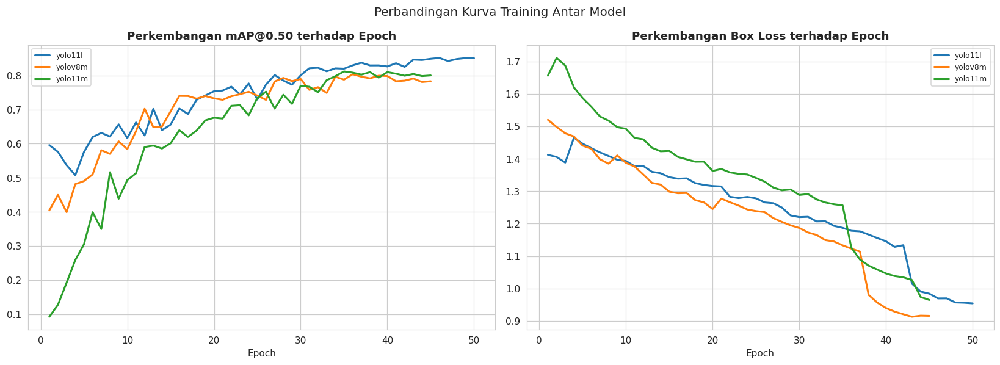

In [ ]:
def load_results_csv(model_filename):
    csv_path = get_run_dir(model_filename) / "results.csv"
    if not csv_path.exists():
        return None
    df = pd.read_csv(csv_path)
    df.columns = [c.strip() for c in df.columns]
    return df

def find_column(df, keyword):
    matches = [c for c in df.columns if keyword.lower() in c.lower()]
    return matches[0] if matches else None

results_by_model = {get_run_name(m): load_results_csv(m) for m in MODEL_LIST if load_results_csv(m) is not None}
print("Riwayat training tersedia untuk:", list(results_by_model.keys()))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for run_name, df in results_by_model.items():
    map50_col = find_column(df, "mAP50(B)") or find_column(df, "mAP50")
    box_loss_col = find_column(df, "train/box_loss")
    if map50_col:
        axes[0].plot(df["epoch"], df[map50_col], label=run_name, linewidth=2)
    if box_loss_col:
        axes[1].plot(df["epoch"], df[box_loss_col], label=run_name, linewidth=2)
axes[0].set_title("Perkembangan mAP@0.50 terhadap Epoch"); axes[0].set_xlabel("Epoch"); axes[0].legend(fontsize=8)
axes[1].set_title("Perkembangan Box Loss terhadap Epoch"); axes[1].set_xlabel("Epoch"); axes[1].legend(fontsize=8)
plt.suptitle("Perbandingan Kurva Training Antar Model", fontsize=13)
plt.tight_layout()
plt.savefig(f"{LOCAL_WORK_DIR}/plots/training_curves_comparison.png", bbox_inches="tight")
plt.show()

## 9. Evaluasi Kuantitatif Menyeluruh

Setiap model dievaluasi pada split `test` yang independen. Metrik mencakup precision, recall, F1, mAP50, mAP75, mAP50-95, jumlah parameter, GFLOPs, ukuran file, dan kecepatan inferensi.

In [ ]:
def get_model_complexity(model):
    try:
        info = model.info(verbose=False)
        if isinstance(info, tuple) and len(info) >= 4:
            return int(info[1]), float(info[3])
    except Exception:
        pass
    return np.nan, np.nan

def evaluate_single_model(model_filename):
    run_name = get_run_name(model_filename)
    best_path = get_run_dir(model_filename) / "weights" / "best.pt"
    if not best_path.exists():
        return None

    model = YOLO(str(best_path))
    metrics_test = model.val(data=subset_yaml_path, split="test", imgsz=IMG_SIZE, conf=0.001, verbose=False)
    metrics_val = model.val(data=subset_yaml_path, split="val", imgsz=IMG_SIZE, conf=0.001, verbose=False)

    precision, recall = float(metrics_test.box.mp), float(metrics_test.box.mr)
    map50, map5095 = float(metrics_test.box.map50), float(metrics_test.box.map)
    map75 = float(metrics_test.box.map75) if hasattr(metrics_test.box, "map75") else np.nan
    f1 = 2 * precision * recall / (precision + recall + 1e-9)
    n_params, gflops = get_model_complexity(model)
    model_size_mb = best_path.stat().st_size / (1024 * 1024)

    test_images = list(Path(subset_test_img).glob("*"))
    sample_for_speed = test_images[:30] if len(test_images) >= 30 else test_images
    start_time = time.time()
    for img_path in sample_for_speed:
        _ = model.predict(str(img_path), imgsz=IMG_SIZE, conf=CONFIDENCE_THRESHOLD, verbose=False)
    avg_inference_ms = ((time.time() - start_time) / max(len(sample_for_speed), 1)) * 1000

    val_test_gap = abs(float(metrics_val.box.map50) - map50)

    del model
    gc.collect()
    torch.cuda.empty_cache()

    return {
        "model": run_name, "precision": precision, "recall": recall, "f1_score": f1,
        "mAP50": map50, "mAP75": map75, "mAP50_95": map5095,
        "mAP50_val": float(metrics_val.box.map50), "val_test_gap": val_test_gap,
        "n_params_juta": n_params / 1e6 if not np.isnan(n_params) else np.nan,
        "gflops": gflops, "model_size_mb": model_size_mb, "avg_inference_ms": avg_inference_ms,
        "training_time_menit": training_times.get(run_name, np.nan),
    }

print("Fungsi evaluasi per-model siap dijalankan (mencakup mAP50/75/50-95, kompleksitas, dan kecepatan).")

Fungsi evaluasi per-model siap dijalankan (mencakup mAP50/75/50-95, kompleksitas, dan kecepatan).


In [ ]:
evaluation_results = []
for model_filename in MODEL_LIST:
    result = evaluate_single_model(model_filename)
    if result is not None:
        evaluation_results.append(result)
        print(f"[{result['model']}] mAP50={result['mAP50']:.4f} | mAP75={result['mAP75']:.4f} | mAP50-95={result['mAP50_95']:.4f} | "
              f"P={result['precision']:.4f} | R={result['recall']:.4f} | F1={result['f1_score']:.4f} | "
              f"Params={result['n_params_juta']:.2f}M | GFLOPs={result['gflops']:.1f} | "
              f"ukuran={result['model_size_mb']:.1f}MB | kecepatan={result['avg_inference_ms']:.1f}ms | "
              f"gap val-test mAP50={result['val_test_gap']:.4f}")
    else:
        print(f"[{model_filename}] belum memiliki hasil training, dilewati.")

comparison_table = pd.DataFrame(evaluation_results).sort_values("mAP50", ascending=False).reset_index(drop=True)
comparison_table.to_csv(f"{LOCAL_WORK_DIR}/metrics/comparison_table.csv", index=False)
print()
print("Tabel perbandingan lengkap seluruh model:")
comparison_table

Ultralytics 8.4.135 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11l summary (fused): 191 layers, 25,297,816 parameters, 0 gradients, 86.9 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 19.9±3.4 MB/s, size: 28.5 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/work/dataset_subset/labels/test... 110 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 110/110 737.0it/s 0.1s
val: New cache created: /content/work/dataset_subset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 1.4it/s 4.9s
                   all        110        144      0.653      0.854      0.794      0.515
Speed: 6.4ms preprocess, 29.1ms inference, 0.0ms loss, 2.1ms postprocess per image
Results saved to /content/runs/detect/val
Ultralytics 8.4.135 🚀 Python-3.13.15 torch-2.11.0

,model,precision,recall,f1_score,mAP50,mAP75,mAP50_95,mAP50_val,val_test_gap,n_params_juta,gflops,model_size_mb,avg_inference_ms,training_time_menit
0,yolo11l,0.653321,0.854278,0.740406,0.793727,0.563727,0.515039,0.847113,0.053386,NaN,NaN,48.858972,41.448657,NaN
1,yolov8m,0.597689,0.820108,0.691453,0.760296,0.561633,0.490404,0.808206,0.047911,NaN,NaN,49.646990,31.407698,NaN
2,yolo11m,0.627093,0.763011,0.688407,0.753778,0.517974,0.478768,0.812280,0.058503,NaN,NaN,38.674175,26.869424,9.198868


Analisis kesenjangan val vs test (indikasi overfitting apabila kesenjangan besar):
 - yolo11l: mAP50 val=0.8471, test=0.7937, selisih=0.0534 -> perlu diperhatikan (kesenjangan cukup besar)
 - yolov8m: mAP50 val=0.8082, test=0.7603, selisih=0.0479 -> cukup konsisten
 - yolo11m: mAP50 val=0.8123, test=0.7538, selisih=0.0585 -> perlu diperhatikan (kesenjangan cukup besar)


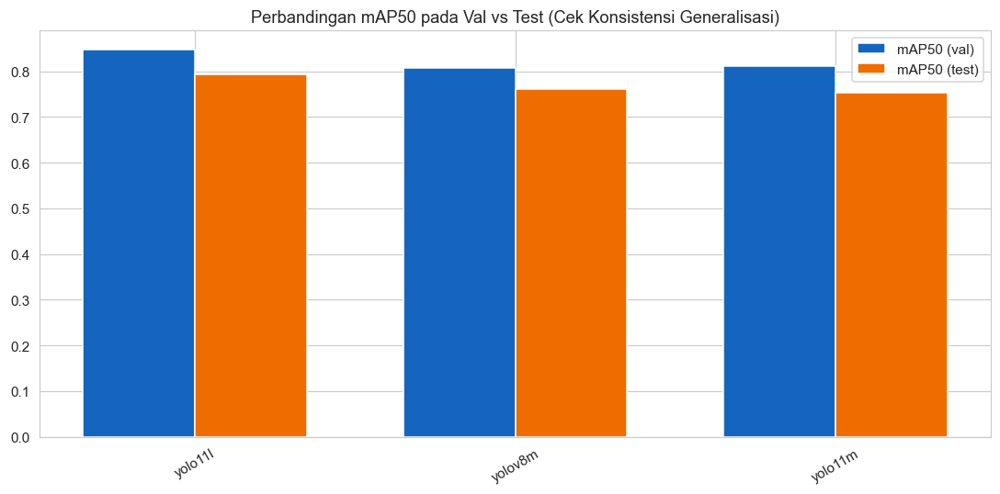

In [ ]:
print("Analisis kesenjangan val vs test (indikasi overfitting apabila kesenjangan besar):")
for _, row in comparison_table.iterrows():
    status = "cukup konsisten" if row["val_test_gap"] < 0.05 else "perlu diperhatikan (kesenjangan cukup besar)"
    print(f" - {row['model']}: mAP50 val={row['mAP50_val']:.4f}, test={row['mAP50']:.4f}, selisih={row['val_test_gap']:.4f} -> {status}")

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(comparison_table))
width = 0.35
ax.bar(x - width/2, comparison_table["mAP50_val"], width, label="mAP50 (val)", color="#1565C0")
ax.bar(x + width/2, comparison_table["mAP50"], width, label="mAP50 (test)", color="#EF6C00")
ax.set_xticks(x)
ax.set_xticklabels(comparison_table["model"], rotation=30)
ax.set_title("Perbandingan mAP50 pada Val vs Test (Cek Konsistensi Generalisasi)")
ax.legend()
plt.tight_layout()
plt.savefig(f"{LOCAL_WORK_DIR}/plots/val_test_consistency.png", bbox_inches="tight")
plt.show()

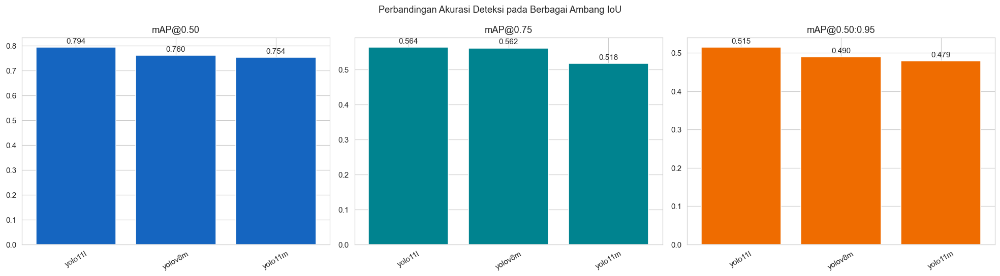

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, metric, title, color in zip(axes, ["mAP50", "mAP75", "mAP50_95"], ["mAP@0.50", "mAP@0.75", "mAP@0.50:0.95"], ["#1565C0", "#00838F", "#EF6C00"]):
    bars = ax.bar(comparison_table["model"], comparison_table[metric], color=color)
    ax.bar_label(bars, fmt="%.3f", padding=3)
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=30)
plt.suptitle("Perbandingan Akurasi Deteksi pada Berbagai Ambang IoU")
plt.tight_layout()
plt.savefig(f"{LOCAL_WORK_DIR}/plots/comparison_map.png", bbox_inches="tight")
plt.show()

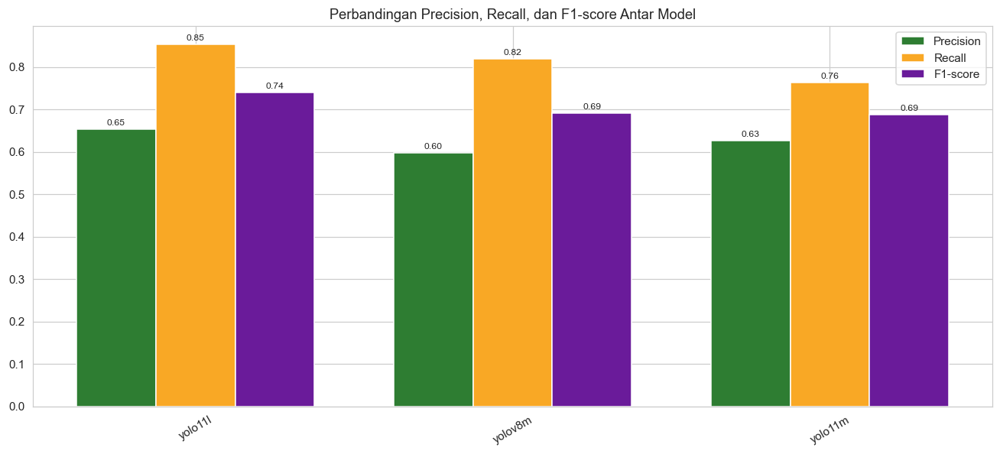

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5.5))
x = np.arange(len(comparison_table))
width = 0.25
for i, (metric, label, color) in enumerate(zip(["precision", "recall", "f1_score"], ["Precision", "Recall", "F1-score"], ["#2E7D32", "#F9A825", "#6A1B9A"])):
    bars = ax.bar(x + (i - 1) * width, comparison_table[metric], width, label=label, color=color)
    ax.bar_label(bars, fmt="%.2f", fontsize=8, padding=2)
ax.set_xticks(x); ax.set_xticklabels(comparison_table["model"], rotation=30)
ax.set_title("Perbandingan Precision, Recall, dan F1-score Antar Model")
ax.legend()
plt.tight_layout()
plt.savefig(f"{LOCAL_WORK_DIR}/plots/comparison_prf1.png", bbox_inches="tight")
plt.show()

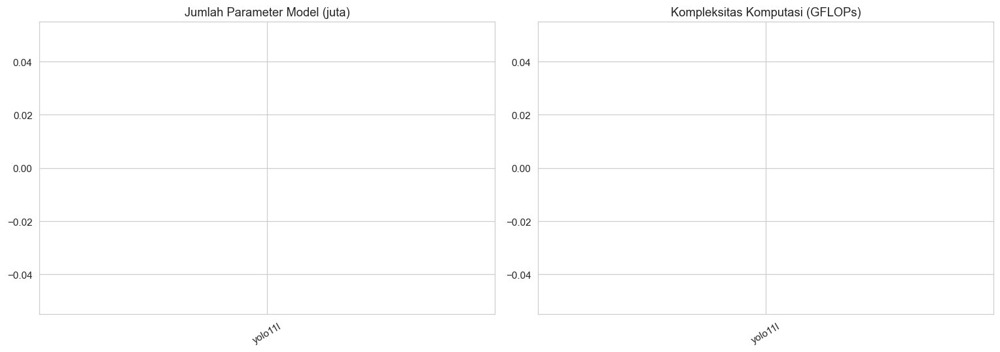

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
bars1 = axes[0].bar(comparison_table["model"], comparison_table["n_params_juta"], color="#37474F")
axes[0].bar_label(bars1, fmt="%.1fM", padding=3)
axes[0].set_title("Jumlah Parameter Model (juta)")
axes[0].tick_params(axis="x", rotation=30)
bars2 = axes[1].bar(comparison_table["model"], comparison_table["gflops"], color="#4E342E")
axes[1].bar_label(bars2, fmt="%.1f", padding=3)
axes[1].set_title("Kompleksitas Komputasi (GFLOPs)")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig(f"{LOCAL_WORK_DIR}/plots/comparison_complexity.png", bbox_inches="tight")
plt.show()

Ultralytics 8.4.135 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11l summary (fused): 191 layers, 25,297,816 parameters, 0 gradients, 86.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 973.4±576.2 MB/s, size: 32.6 KB)
val: Scanning /content/work/dataset_subset/labels/test.cache... 110 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 110/110 23.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 1.6it/s 4.5s
                   all        110        144      0.653      0.854      0.794      0.515
Speed: 2.4ms preprocess, 29.2ms inference, 0.0ms loss, 1.1ms postprocess per image
Results saved to /content/runs/detect/val-7
Ultralytics 8.4.135 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 93 layers, 25,853,656 parameters, 0 gradients, 78.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1395.2±644.3 MB/s, size: 30.1 KB)
val: Scanning 

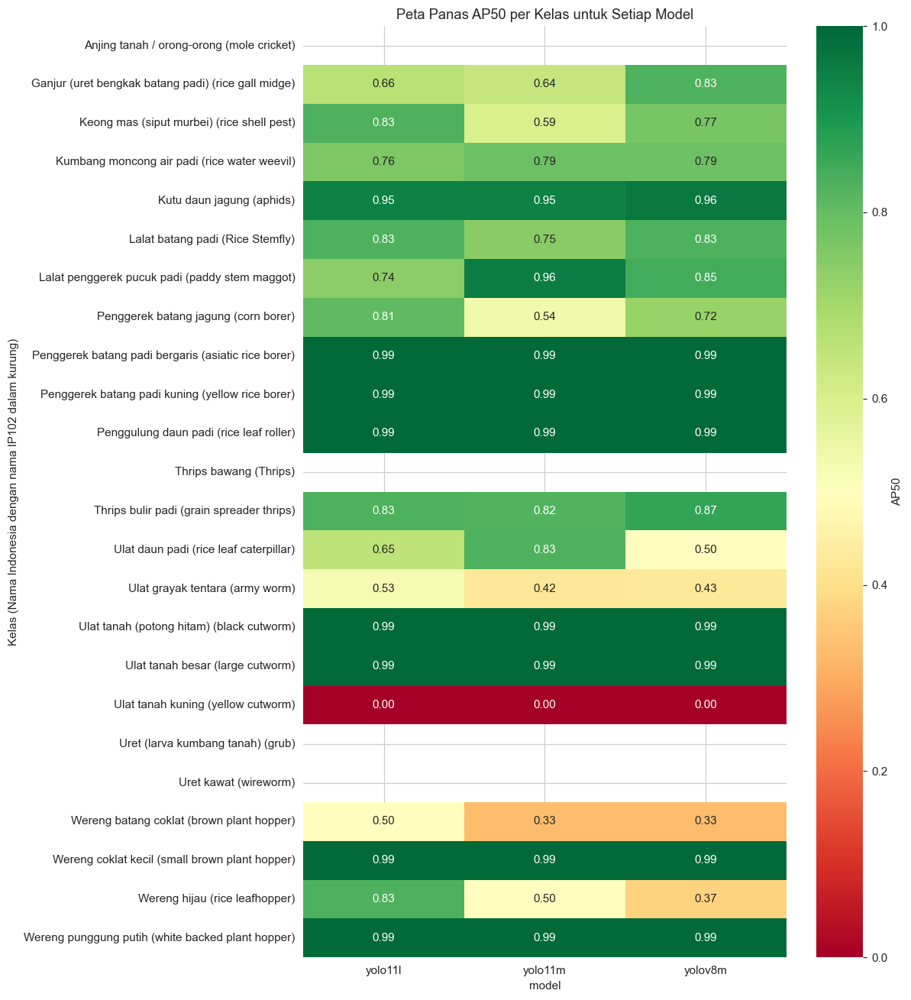

Lima kelas dengan rata-rata AP50 terendah di seluruh model:
class_name
Ulat tanah kuning (yellow cutworm)           0.000000
Wereng batang coklat (brown plant hopper)    0.386944
Ulat grayak tentara (army worm)              0.459684
Wereng hijau (rice leafhopper)               0.566875
Ulat daun padi (rice leaf caterpillar)       0.660500
dtype: float64


In [ ]:
per_class_records = []
for model_filename in MODEL_LIST:
    run_name = get_run_name(model_filename)
    best_path = get_run_dir(model_filename) / "weights" / "best.pt"
    if not best_path.exists():
        continue
    model = YOLO(str(best_path))
    metrics = model.val(data=subset_yaml_path, split="test", imgsz=IMG_SIZE, conf=0.001, verbose=False)
    for idx, class_name in enumerate(SUBSET_NAMES):
        ap50 = float(metrics.box.ap50[idx]) if idx < len(metrics.box.ap50) else np.nan
        per_class_records.append({"model": run_name, "class_name": SUBSET_LABELS_DISPLAY[idx], "komoditas": SUBSET_COMMODITY[idx], "AP50": ap50})
    del model
    gc.collect()
    torch.cuda.empty_cache()

per_class_df = pd.DataFrame(per_class_records)
pivot_ap = per_class_df.pivot(index="class_name", columns="model", values="AP50")

fig, ax = plt.subplots(figsize=(11, 12))
sns.heatmap(pivot_ap, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1, ax=ax, cbar_kws={"label": "AP50"})
ax.set_title("Peta Panas AP50 per Kelas untuk Setiap Model")
ax.set_ylabel("Kelas (Nama Indonesia dengan nama IP102 dalam kurung)")
plt.tight_layout()
plt.savefig(f"{LOCAL_WORK_DIR}/plots/per_class_ap_heatmap.png", bbox_inches="tight")
plt.show()

weakest_classes = pivot_ap.mean(axis=1).sort_values().head(5)
print("Lima kelas dengan rata-rata AP50 terendah di seluruh model:")
print(weakest_classes)

In [ ]:
best_by_accuracy = comparison_table.loc[comparison_table["mAP50"].idxmax()]
BEST_MODEL_NAME = best_by_accuracy["model"]
best_model_path = Path(DRIVE_OUTPUT_ROOT) / "train_runs" / BEST_MODEL_NAME / "weights" / "best.pt"
best_model = YOLO(str(best_model_path))
print("Model terbaik berdasarkan mAP50 pada data test:", BEST_MODEL_NAME)
print("mAP50 = {:.4f} | mAP50-95 = {:.4f} | Precision = {:.4f} | Recall = {:.4f}".format(
    best_by_accuracy["mAP50"], best_by_accuracy["mAP50_95"], best_by_accuracy["precision"], best_by_accuracy["recall"]))

Model terbaik berdasarkan mAP50 pada data test: yolo11l
mAP50 = 0.7937 | mAP50-95 = 0.5150 | Precision = 0.6533 | Recall = 0.8543


## 10. Evaluasi Test-Time Augmentation (TTA)

Test-Time Augmentation menjalankan inferensi pada beberapa versi tertransformasi (flip horizontal, beberapa skala citra) dari citra yang sama, kemudian menggabungkan hasilnya. Teknik ini umumnya meningkatkan akurasi dengan konsekuensi waktu inferensi yang lebih lama. Karena inferensi pada kasus ini berjalan di server dengan interval satu jam sekali (bukan real-time), tambahan waktu inferensi dari TTA kemungkinan besar dapat diterima apabila peningkatan akurasinya signifikan.

In [ ]:
metrics_no_tta = best_model.val(data=subset_yaml_path, split="test", imgsz=IMG_SIZE, conf=0.001, verbose=False, augment=False)
metrics_tta = best_model.val(data=subset_yaml_path, split="test", imgsz=IMG_SIZE, conf=0.001, verbose=False, augment=True)

tta_comparison = pd.DataFrame({
    "mode": ["Tanpa TTA", "Dengan TTA"],
    "mAP50": [float(metrics_no_tta.box.map50), float(metrics_tta.box.map50)],
    "mAP50_95": [float(metrics_no_tta.box.map), float(metrics_tta.box.map)],
    "precision": [float(metrics_no_tta.box.mp), float(metrics_tta.box.mp)],
    "recall": [float(metrics_no_tta.box.mr), float(metrics_tta.box.mr)],
})
print(tta_comparison)

start_time = time.time()
sample_tta_images = list(Path(subset_test_img).glob("*"))[:20]
for img_path in sample_tta_images:
    _ = best_model.predict(str(img_path), imgsz=IMG_SIZE, conf=CONFIDENCE_THRESHOLD, verbose=False, augment=True)
tta_inference_ms = ((time.time() - start_time) / len(sample_tta_images)) * 1000
print(f"Rata-rata waktu inferensi dengan TTA: {tta_inference_ms:.1f} ms/gambar (dibandingkan tanpa TTA pada Bagian 9)")

Ultralytics 8.4.135 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11l summary (fused): 191 layers, 25,297,816 parameters, 0 gradients, 86.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1418.2±1163.7 MB/s, size: 60.5 KB)
val: Scanning /content/work/dataset_subset/labels/test.cache... 110 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 110/110 25.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 1.6it/s 4.5s
                   all        110        144      0.653      0.854      0.794      0.515
Speed: 3.0ms preprocess, 29.6ms inference, 0.0ms loss, 1.7ms postprocess per image
Results saved to /content/runs/detect/val-10
Ultralytics 8.4.135 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 786.5±537.2 MB/s, size: 23.3 KB)
val: Scanning /content/work/dataset_subset/labels/test.cache... 110 images, 0 backgrounds, 0 c

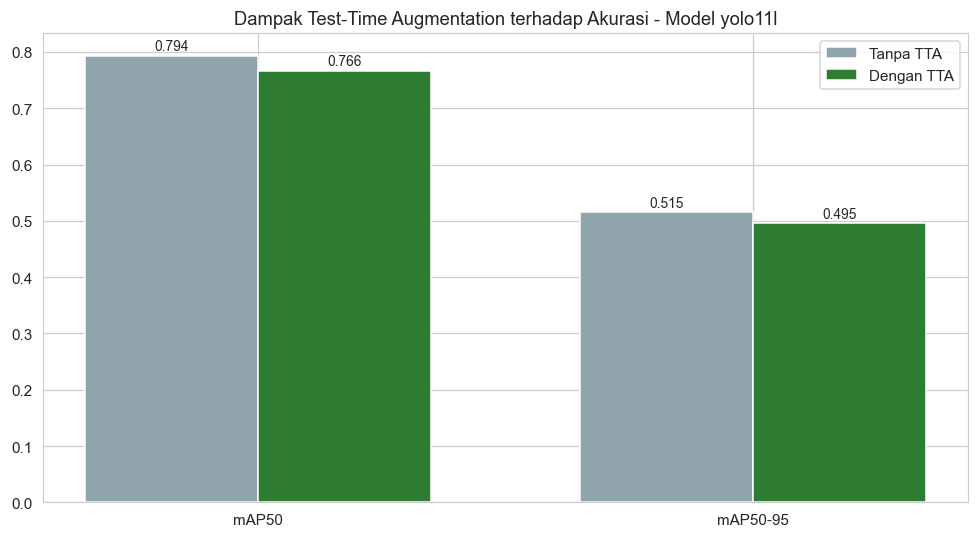

Peningkatan mAP50 dari TTA: -0.0276
Rekomendasi: TIDAK PERLU menggunakan TTA pada tahap deployment.


In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(2)
width = 0.35
ax.bar(x - width/2, [tta_comparison["mAP50"][0], tta_comparison["mAP50_95"][0]], width, label="Tanpa TTA", color="#90A4AE")
ax.bar(x + width/2, [tta_comparison["mAP50"][1], tta_comparison["mAP50_95"][1]], width, label="Dengan TTA", color="#2E7D32")
ax.set_xticks(x)
ax.set_xticklabels(["mAP50", "mAP50-95"])
ax.set_title(f"Dampak Test-Time Augmentation terhadap Akurasi - Model {BEST_MODEL_NAME}")
ax.legend()
for i, (v1, v2) in enumerate(zip([tta_comparison["mAP50"][0], tta_comparison["mAP50_95"][0]], [tta_comparison["mAP50"][1], tta_comparison["mAP50_95"][1]])):
    ax.text(i - width/2, v1 + 0.01, f"{v1:.3f}", ha="center", fontsize=9)
    ax.text(i + width/2, v2 + 0.01, f"{v2:.3f}", ha="center", fontsize=9)
plt.tight_layout()
plt.savefig(f"{LOCAL_WORK_DIR}/plots/tta_comparison.png", bbox_inches="tight")
plt.show()

tta_improvement = tta_comparison["mAP50"][1] - tta_comparison["mAP50"][0]
USE_TTA_RECOMMENDATION = tta_improvement > 0.005
print(f"Peningkatan mAP50 dari TTA: {tta_improvement:+.4f}")
print("Rekomendasi: {} TTA pada tahap deployment.".format("GUNAKAN" if USE_TTA_RECOMMENDATION else "TIDAK PERLU menggunakan"))

## 11. Ensemble Model (Weighted Box Fusion Sederhana)

Ensemble menggabungkan hasil deteksi dari beberapa model terbaik untuk berpotensi menghasilkan akurasi yang lebih tinggi dibandingkan model tunggal manapun. Teknik yang digunakan adalah **weighted box fusion sederhana**: deteksi dengan kelas yang sama dan IoU tumpang tindih tinggi (>=0.55) dari model-model berbeda digabung menjadi satu deteksi dengan koordinat dan confidence hasil rata-rata terbobot, alih-alih dipilih salah satu (seperti pada Non-Maximum Suppression konvensional).

Sebanyak 3 model dengan mAP50 tertinggi digunakan sebagai anggota ensemble.

In [ ]:
top_k_models = comparison_table.head(TOP_K_ENSEMBLE)["model"].tolist()
print("Model anggota ensemble (berdasarkan mAP50 tertinggi):", top_k_models)
print("Setiap model dimuat, dipakai memprediksi seluruh data test, lalu dilepas dari memori sebelum")
print("model berikutnya dimuat -- menghindari ketiga model besar (termasuk yolo11l) resident di memori sekaligus.")

Model anggota ensemble (berdasarkan mAP50 tertinggi): ['yolo11l', 'yolov8m', 'yolo11m']
Setiap model dimuat, dipakai memprediksi seluruh data test, lalu dilepas dari memori sebelum
model berikutnya dimuat -- menghindari ketiga model besar (termasuk yolo11l) resident di memori sekaligus.


In [ ]:
raw_detections_per_image = defaultdict(list)
test_label_files_ensemble = list(Path(subset_test_lbl).glob("*.txt"))

for run_name in top_k_models:
    best_path = Path(DRIVE_OUTPUT_ROOT) / "train_runs" / run_name / "weights" / "best.pt"
    model_temp = YOLO(str(best_path))
    for lbl_path in tqdm(test_label_files_ensemble, desc=f"Prediksi ensemble - {run_name}"):
        img_path = next(Path(subset_test_img).glob(f"{lbl_path.stem}.*"), None)
        if img_path is None:
            continue
        result = model_temp.predict(str(img_path), imgsz=IMG_SIZE, conf=0.05, verbose=False)[0]
        if result.boxes is not None:
            for box in result.boxes:
                raw_detections_per_image[lbl_path.stem].append(
                    (int(box.cls[0]), float(box.conf[0]), box.xyxy[0].cpu().numpy().tolist())
                )
    del model_temp
    gc.collect()
    torch.cuda.empty_cache()
    print(f"[{run_name}] selesai, model dilepas dari memori.")

print("Total gambar dengan deteksi mentah terkumpul:", len(raw_detections_per_image))

Prediksi ensemble - yolo11l:   0%|          | 0/110 [00:00<?, ?it/s]

[yolo11l] selesai, model dilepas dari memori.


Prediksi ensemble - yolov8m:   0%|          | 0/110 [00:00<?, ?it/s]

[yolov8m] selesai, model dilepas dari memori.


Prediksi ensemble - yolo11m:   0%|          | 0/110 [00:00<?, ?it/s]

[yolo11m] selesai, model dilepas dari memori.
Total gambar dengan deteksi mentah terkumpul: 110


In [ ]:
def fuse_detections(all_detections, iou_thresh=0.55):
    by_class = {}
    for c, conf, box in all_detections:
        by_class.setdefault(c, []).append((conf, box))
    fused = []
    for c, items in by_class.items():
        items.sort(key=lambda x: x[0], reverse=True)
        used = [False] * len(items)
        for i in range(len(items)):
            if used[i]:
                continue
            cluster = [items[i]]
            used[i] = True
            for j in range(i + 1, len(items)):
                if used[j]:
                    continue
                if compute_iou(items[i][1], items[j][1]) >= iou_thresh:
                    cluster.append(items[j])
                    used[j] = True
            total_conf = sum(x[0] for x in cluster)
            fused_box = [sum(x[1][k] * x[0] for x in cluster) / total_conf for k in range(4)]
            fused_conf = total_conf / len(cluster)
            fused.append((c, fused_conf, fused_box))
    return fused

print("Fungsi weighted box fusion siap digunakan.")
print("Prinsip kerja: deteksi kelas sama dengan IoU >= 0.55 dari model berbeda digabung menjadi satu")
print("deteksi hasil rata-rata terbobot berdasarkan confidence masing-masing.")

Fungsi weighted box fusion siap digunakan.
Prinsip kerja: deteksi kelas sama dengan IoU >= 0.55 dari model berbeda digabung menjadi satu
deteksi hasil rata-rata terbobot berdasarkan confidence masing-masing.


In [ ]:
def ensemble_evaluate(threshold):
    tp, fp, fn = 0, 0, 0
    for lbl_path in test_label_files_ensemble:
        img_path = next(Path(subset_test_img).glob(f"{lbl_path.stem}.*"), None)
        if img_path is None:
            continue
        img = cv2.imread(str(img_path))
        img_h, img_w = img.shape[:2]
        gt_boxes = [(c, yolo_to_xyxy(x, y, w, h, img_w, img_h)) for c, x, y, w, h in parse_label_file(lbl_path)]

        all_detections = raw_detections_per_image.get(lbl_path.stem, [])
        fused = fuse_detections(all_detections)
        fused = [f for f in fused if f[1] >= threshold]

        matched_gt = set()
        for pred_class, conf, pred_box in fused:
            best_iou, best_gi = 0, -1
            for gi, (gt_class, gt_box) in enumerate(gt_boxes):
                if gi in matched_gt or gt_class != pred_class:
                    continue
                iou = compute_iou(gt_box, pred_box)
                if iou > best_iou:
                    best_iou, best_gi = iou, gi
            if best_iou >= IOU_MATCH_THRESHOLD:
                matched_gt.add(best_gi)
                tp += 1
            else:
                fp += 1
        fn += len(gt_boxes) - len(matched_gt)
    precision = tp / (tp + fp + 1e-9)
    recall = tp / (tp + fn + 1e-9)
    f1 = 2 * precision * recall / (precision + recall + 1e-9)
    return precision, recall, f1

print("Fungsi evaluasi ensemble siap (menggunakan deteksi mentah yang sudah dikumpulkan, tanpa perlu model resident di memori).")

Fungsi evaluasi ensemble siap (menggunakan deteksi mentah yang sudah dikumpulkan, tanpa perlu model resident di memori).


In [ ]:
ens_precision, ens_recall, ens_f1 = ensemble_evaluate(CONFIDENCE_THRESHOLD)
print("Hasil ensemble pada threshold {:.0%}: precision={:.4f}, recall={:.4f}, F1={:.4f}".format(CONFIDENCE_THRESHOLD, ens_precision, ens_recall, ens_f1))
print("Hasil model tunggal terbaik ({}): precision={:.4f}, recall={:.4f}, F1={:.4f}".format(
    BEST_MODEL_NAME, best_by_accuracy["precision"], best_by_accuracy["recall"], best_by_accuracy["f1_score"]))

Hasil ensemble pada threshold 35%: precision=0.7483, recall=0.7639, F1=0.7560
Hasil model tunggal terbaik (yolo11l): precision=0.6533, recall=0.8543, F1=0.7404


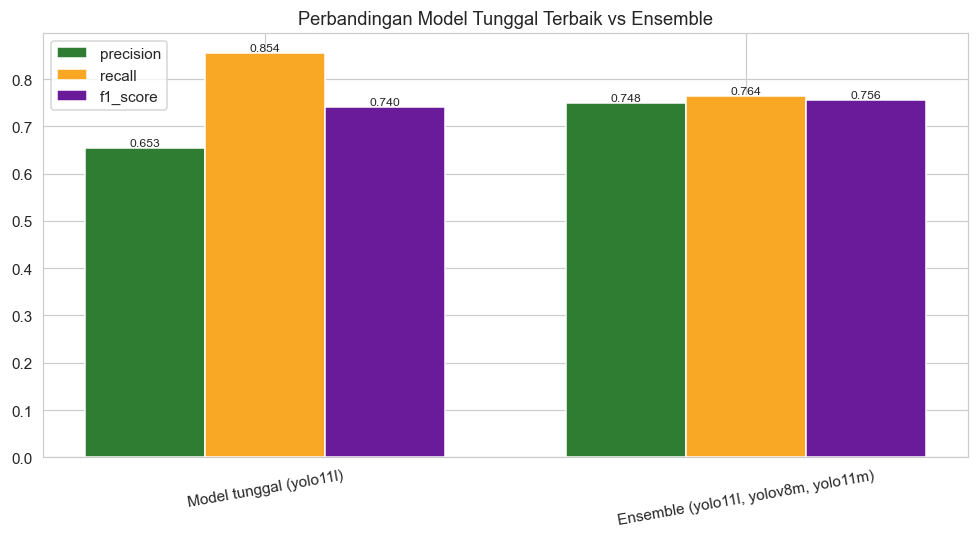

Selisih F1-score ensemble vs model tunggal terbaik: +0.0156
Rekomendasi: ensemble memberikan peningkatan berarti, pertimbangkan untuk deployment meskipun
membutuhkan sumber daya komputasi lebih besar (menjalankan 3 model sekaligus).


In [ ]:
ensemble_comparison = pd.DataFrame({
    "pendekatan": [f"Model tunggal ({BEST_MODEL_NAME})", f"Ensemble ({', '.join(top_k_models)})"],
    "precision": [best_by_accuracy["precision"], ens_precision],
    "recall": [best_by_accuracy["recall"], ens_recall],
    "f1_score": [best_by_accuracy["f1_score"], ens_f1],
})
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(ensemble_comparison))
width = 0.25
for i, (metric, color) in enumerate(zip(["precision", "recall", "f1_score"], ["#2E7D32", "#F9A825", "#6A1B9A"])):
    bars = ax.bar(x + (i - 1) * width, ensemble_comparison[metric], width, label=metric, color=color)
    ax.bar_label(bars, fmt="%.3f", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(ensemble_comparison["pendekatan"], rotation=10)
ax.set_title("Perbandingan Model Tunggal Terbaik vs Ensemble")
ax.legend()
plt.tight_layout()
plt.savefig(f"{LOCAL_WORK_DIR}/plots/ensemble_comparison.png", bbox_inches="tight")
plt.show()

ensemble_gain = ens_f1 - best_by_accuracy["f1_score"]
USE_ENSEMBLE_RECOMMENDATION = ensemble_gain > 0.01
print(f"Selisih F1-score ensemble vs model tunggal terbaik: {ensemble_gain:+.4f}")
if USE_ENSEMBLE_RECOMMENDATION:
    print("Rekomendasi: ensemble memberikan peningkatan berarti, pertimbangkan untuk deployment meskipun")
    print("membutuhkan sumber daya komputasi lebih besar (menjalankan {} model sekaligus).".format(TOP_K_ENSEMBLE))
else:
    print("Rekomendasi: peningkatan dari ensemble tidak cukup signifikan untuk mengorbankan kompleksitas")
    print("operasional tambahan. Model tunggal ({}) tetap menjadi pilihan yang lebih praktis.".format(BEST_MODEL_NAME))

gc.collect()
torch.cuda.empty_cache()

## 12. Pengumpulan Data Deteksi Mentah untuk Analisis Lanjutan

Untuk efisiensi, seluruh analisis lanjutan pada Bagian 11-14 (confusion matrix, kurva precision-recall, kalibrasi confidence, dan interval kepercayaan bootstrap) menggunakan **satu kali proses prediksi** per gambar test pada model terbaik dengan confidence rendah (0.001, menangkap seluruh kandidat deteksi). Hasil mentah ini kemudian dianalisis ulang secara numerik tanpa perlu menjalankan model kembali, sehingga jauh lebih efisien dibandingkan menjalankan prediksi terpisah untuk setiap jenis analisis.

In [ ]:
test_label_files = list(Path(subset_test_lbl).glob("*.txt"))
per_image_data = []

for lbl_path in tqdm(test_label_files, desc="Mengumpulkan prediksi mentah pada data test"):
    img_path = next(Path(subset_test_img).glob(f"{lbl_path.stem}.*"), None)
    if img_path is None:
        continue
    img = cv2.imread(str(img_path))
    img_h, img_w = img.shape[:2]

    gt_boxes = [(c, yolo_to_xyxy(x, y, w, h, img_w, img_h)) for c, x, y, w, h in parse_label_file(lbl_path)]
    result = best_model.predict(str(img_path), imgsz=IMG_SIZE, conf=0.001, verbose=False)[0]
    pred_boxes = []
    if result.boxes is not None:
        for box in result.boxes:
            pred_boxes.append((int(box.cls[0]), float(box.conf[0]), box.xyxy[0].cpu().numpy().tolist()))
    pred_boxes.sort(key=lambda x: x[1], reverse=True)

    per_image_data.append({"image_path": img_path, "gt_boxes": gt_boxes, "pred_boxes": pred_boxes})

total_gt_boxes = sum(len(d["gt_boxes"]) for d in per_image_data)
total_pred_boxes = sum(len(d["pred_boxes"]) for d in per_image_data)
print("Total gambar test dianalisis:", len(per_image_data))
print("Total ground truth box:", total_gt_boxes)
print("Total kandidat prediksi (conf>=0.001):", total_pred_boxes)

Mengumpulkan prediksi mentah pada data test:   0%|          | 0/110 [00:00<?, ?it/s]

Total gambar test dianalisis: 110
Total ground truth box: 144
Total kandidat prediksi (conf>=0.001): 685


## 13. Confusion Matrix Multi-Kelas

Confusion matrix dibangun dengan mencocokkan setiap ground truth terhadap prediksi dengan IoU tertinggi (ambang IoU 0.5), **lintas kelas** (tidak dibatasi hanya kelas yang sama), untuk mengungkap pola kesalahan: kelas apa yang paling sering tertukar dengan kelas lain. Baris/kolom tambahan "tidak terdeteksi"/"deteksi palsu" merepresentasikan kasus objek yang gagal terdeteksi maupun deteksi yang tidak berkorespondensi dengan objek nyata.

In [ ]:
confusion = np.zeros((N_CLASSES + 1, N_CLASSES + 1), dtype=int)
BACKGROUND_IDX = N_CLASSES

for data in per_image_data:
    gt_boxes = data["gt_boxes"]
    pred_boxes_conf = [(c, box) for c, conf, box in data["pred_boxes"] if conf >= CONFIDENCE_THRESHOLD]

    matched_gt, matched_pred = set(), set()
    pairs = []
    for gi, (gt_class, gt_box) in enumerate(gt_boxes):
        for pi, (pred_class, pred_box) in enumerate(pred_boxes_conf):
            iou = compute_iou(gt_box, pred_box)
            if iou >= IOU_MATCH_THRESHOLD:
                pairs.append((iou, gi, pi))
    pairs.sort(reverse=True)
    for iou, gi, pi in pairs:
        if gi in matched_gt or pi in matched_pred:
            continue
        matched_gt.add(gi)
        matched_pred.add(pi)
        gt_class = gt_boxes[gi][0]
        pred_class = pred_boxes_conf[pi][0]
        confusion[gt_class, pred_class] += 1

    for gi in range(len(gt_boxes)):
        if gi not in matched_gt:
            confusion[gt_boxes[gi][0], BACKGROUND_IDX] += 1
    for pi in range(len(pred_boxes_conf)):
        if pi not in matched_pred:
            confusion[BACKGROUND_IDX, pred_boxes_conf[pi][0]] += 1

labels_with_bg = SUBSET_LABELS_DISPLAY + ["(tidak terdeteksi/palsu)"]
confusion_df = pd.DataFrame(confusion, index=labels_with_bg, columns=labels_with_bg)
print("Confusion matrix berhasil dibangun, dimensi:", confusion.shape)
print("Total pencocokan (diagonal, true positive):", int(np.trace(confusion)))

Confusion matrix berhasil dibangun, dimensi: (25, 25)
Total pencocokan (diagonal, true positive): 107


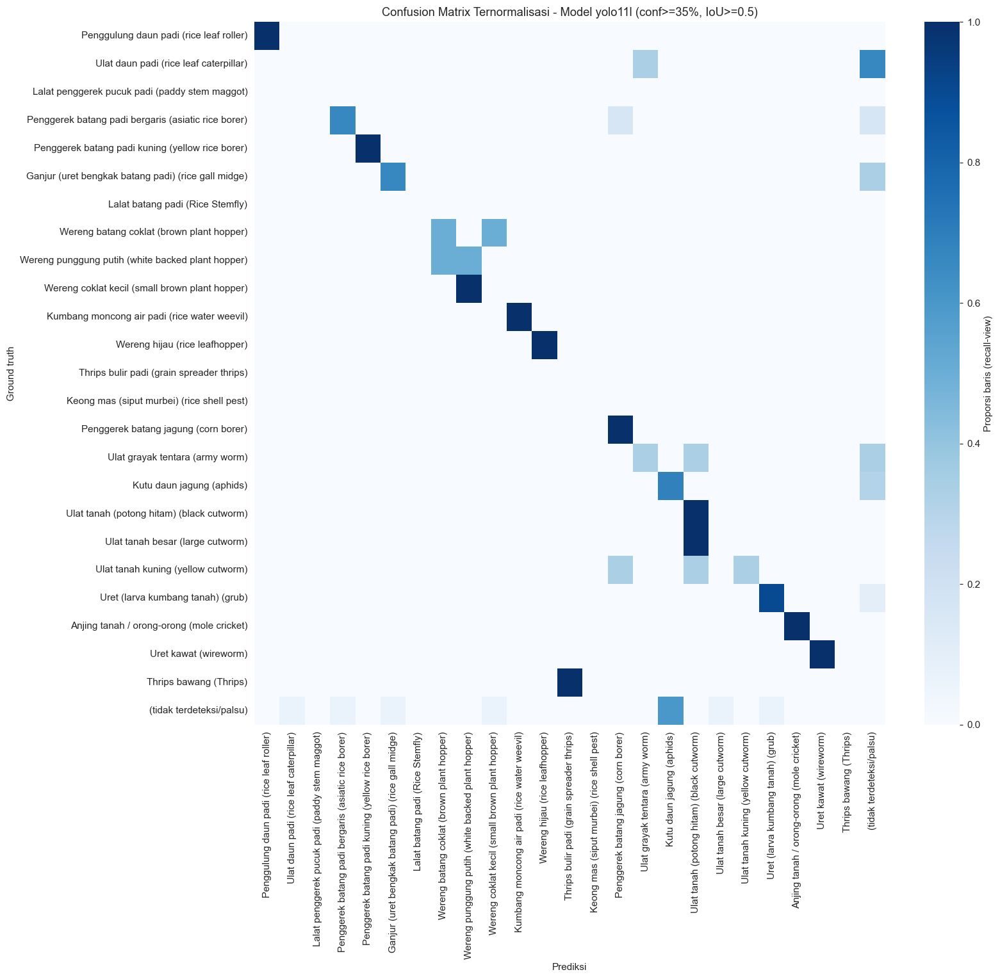

In [ ]:
row_sums = confusion.sum(axis=1, keepdims=True)
confusion_normalized = np.divide(confusion, row_sums, out=np.zeros_like(confusion, dtype=float), where=row_sums != 0)

fig, ax = plt.subplots(figsize=(15, 14))
sns.heatmap(confusion_normalized, annot=False, cmap="Blues", xticklabels=labels_with_bg, yticklabels=labels_with_bg,
            cbar_kws={"label": "Proporsi baris (recall-view)"}, ax=ax)
ax.set_xlabel("Prediksi")
ax.set_ylabel("Ground truth")
ax.set_title(f"Confusion Matrix Ternormalisasi - Model {BEST_MODEL_NAME} (conf>={CONFIDENCE_THRESHOLD:.0%}, IoU>=0.5)")
plt.tight_layout()
plt.savefig(f"{LOCAL_WORK_DIR}/plots/confusion_matrix_full.png", bbox_inches="tight")
plt.show()

In [ ]:
print("Pasangan kelas yang paling sering tertukar (di luar diagonal, minimal 2 kejadian):")
confusion_pairs = []
for i in range(N_CLASSES):
    for j in range(N_CLASSES):
        if i != j and confusion[i, j] >= 2:
            confusion_pairs.append((labels_with_bg[i], labels_with_bg[j], confusion[i, j]))
confusion_pairs.sort(key=lambda x: x[2], reverse=True)
for gt_name, pred_name, count in confusion_pairs[:10]:
    print(f" - Ground truth '{gt_name}' terprediksi sebagai '{pred_name}' sebanyak {count} kali")
if not confusion_pairs:
    print("Tidak ditemukan pola kesalahan antar-kelas yang signifikan (>=2 kejadian) pada threshold ini.")

Pasangan kelas yang paling sering tertukar (di luar diagonal, minimal 2 kejadian):
 - Ground truth 'Ulat tanah besar (large cutworm)' terprediksi sebagai 'Ulat tanah (potong hitam) (black cutworm)' sebanyak 7 kali


### 13.1 Confusion Matrix Tingkat Komoditas

Kesalahan klasifikasi **di dalam satu komoditas yang sama** (misalnya antar sesama hama padi) memiliki dampak praktis yang jauh lebih kecil dibandingkan kesalahan **lintas komoditas** (misalnya hama padi terdeteksi sebagai hama jagung), karena yang terakhir dapat menyebabkan rekomendasi tindakan pengendalian yang salah sasaran. Agregasi confusion matrix ke tingkat komoditas berikut mengukur risiko tersebut secara langsung.

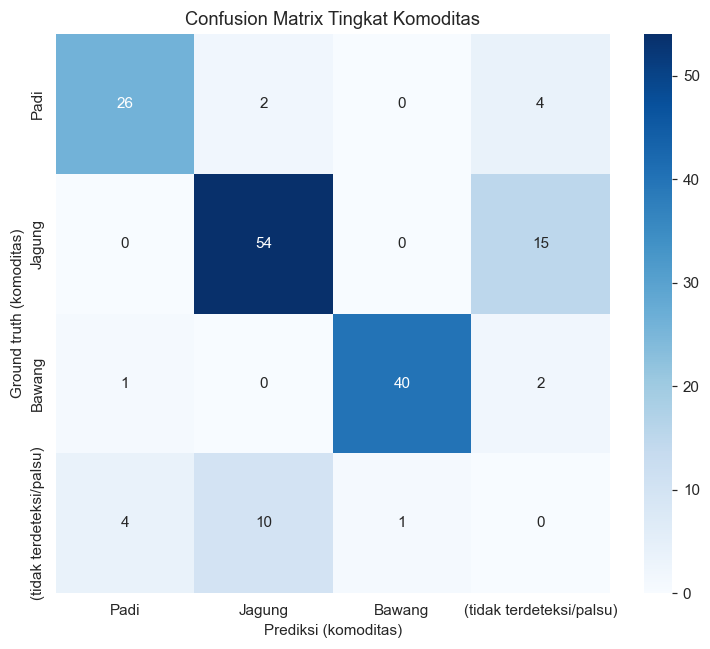

Total kesalahan klasifikasi LINTAS KOMODITAS (dampak praktis tinggi): 3
Terdapat kesalahan lintas komoditas -> perlu ditinjau lebih lanjut sebelum rekomendasi tindakan otomatis diterapkan sepenuhnya tanpa verifikasi manual.


In [ ]:
commodity_labels = ["Padi", "Jagung", "Bawang", "(tidak terdeteksi/palsu)"]
commodity_confusion = pd.DataFrame(0, index=commodity_labels, columns=commodity_labels)

for i in range(N_CLASSES):
    row_commodity = SUBSET_COMMODITY[i]
    for j in range(N_CLASSES):
        col_commodity = SUBSET_COMMODITY[j]
        commodity_confusion.loc[row_commodity, col_commodity] += confusion[i, j]
    commodity_confusion.loc[row_commodity, "(tidak terdeteksi/palsu)"] += confusion[i, BACKGROUND_IDX]
for j in range(N_CLASSES):
    commodity_confusion.loc["(tidak terdeteksi/palsu)", SUBSET_COMMODITY[j]] += confusion[BACKGROUND_IDX, j]

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(commodity_confusion, annot=True, fmt="d", cmap="Blues", ax=ax)
ax.set_xlabel("Prediksi (komoditas)")
ax.set_ylabel("Ground truth (komoditas)")
ax.set_title("Confusion Matrix Tingkat Komoditas")
plt.tight_layout()
plt.savefig(f"{LOCAL_WORK_DIR}/plots/confusion_matrix_commodity_level.png", bbox_inches="tight")
plt.show()

cross_commodity_errors = 0
for i in commodity_labels[:3]:
    for j in commodity_labels[:3]:
        if i != j:
            cross_commodity_errors += commodity_confusion.loc[i, j]
print(f"Total kesalahan klasifikasi LINTAS KOMODITAS (dampak praktis tinggi): {int(cross_commodity_errors)}")
if cross_commodity_errors == 0:
    print("Tidak ditemukan kesalahan lintas komoditas pada data test -> model tidak pernah salah mengarahkan rekomendasi ke komoditas yang keliru.")
else:
    print("Terdapat kesalahan lintas komoditas -> perlu ditinjau lebih lanjut sebelum rekomendasi tindakan otomatis diterapkan sepenuhnya tanpa verifikasi manual.")

In [ ]:
fn_per_class = confusion[:N_CLASSES, BACKGROUND_IDX]
fp_per_class = confusion[BACKGROUND_IDX, :N_CLASSES]
tp_per_class = np.diag(confusion)[:N_CLASSES]

detection_health_df = pd.DataFrame({
    "kelas_ip102": SUBSET_NAMES, "nama_indonesia": SUBSET_NAME_ID, "komoditas": SUBSET_COMMODITY,
    "true_positive": tp_per_class, "false_negative_tidak_terdeteksi": fn_per_class, "false_positive_deteksi_palsu": fp_per_class,
})
detection_health_df["recall_praktis"] = detection_health_df["true_positive"] / (detection_health_df["true_positive"] + detection_health_df["false_negative_tidak_terdeteksi"] + 1e-9)
detection_health_df = detection_health_df.sort_values("recall_praktis")
print("Tabel kesehatan deteksi per kelas (diurutkan dari recall praktis terendah):")
detection_health_df

Tabel kesehatan deteksi per kelas (diurutkan dari recall praktis terendah):


,kelas_ip102,nama_indonesia,komoditas,true_positive,false_negative_tidak_terdeteksi,false_positive_deteksi_palsu,recall_praktis
1,rice leaf caterpillar,Ulat daun padi,Padi,0,2,1,0.000000
2,paddy stem maggot,Lalat penggerek pucuk padi,Padi,0,0,0,0.000000
6,Rice Stemfly,Lalat batang padi,Padi,0,0,0,0.000000
9,small brown plant hopper,Wereng coklat kecil,Padi,0,0,1,0.000000
12,grain spreader thrips,Thrips bulir padi,Padi,0,0,0,0.000000
13,rice shell pest,Keong mas (siput murbei),Padi,0,0,0,0.000000
23,Thrips,Thrips bawang,Bawang,0,0,0,0.000000
18,large cutworm,Ulat tanah besar,Jagung,0,0,1,0.000000
15,army worm,Ulat grayak tentara,Jagung,1,1,0,0.500000
5,rice gall midge,Ganjur (uret bengkak batang padi),Padi,2,1,1,0.666667


## 14. Kurva Precision-Recall dan Titik Operasi Ambang Batas

Kurva precision-recall dibangun dengan menyapu berbagai nilai ambang batas confidence pada data mentah yang telah dikumpulkan (Bagian 10), menggunakan pencocokan per-kelas (satu ground truth hanya dapat dipasangkan dengan satu prediksi kelas yang sama), konsisten dengan definisi standar evaluasi object detection.

In [ ]:
def evaluate_at_threshold(threshold):
    tp, fp, fn = 0, 0, 0
    for data in per_image_data:
        gt_boxes = data["gt_boxes"]
        preds = [(c, box) for c, conf, box in data["pred_boxes"] if conf >= threshold]
        matched_gt = set()
        for pred_class, pred_box in preds:
            best_iou, best_gi = 0, -1
            for gi, (gt_class, gt_box) in enumerate(gt_boxes):
                if gi in matched_gt or gt_class != pred_class:
                    continue
                iou = compute_iou(gt_box, pred_box)
                if iou > best_iou:
                    best_iou, best_gi = iou, gi
            if best_iou >= IOU_MATCH_THRESHOLD:
                matched_gt.add(best_gi)
                tp += 1
            else:
                fp += 1
        fn += len(gt_boxes) - len(matched_gt)
    precision = tp / (tp + fp + 1e-9)
    recall = tp / (tp + fn + 1e-9)
    f1 = 2 * precision * recall / (precision + recall + 1e-9)
    return precision, recall, f1

thresholds_sweep = np.arange(0.05, 1.00, 0.05)
pr_curve_records = [dict(zip(["threshold", "precision", "recall", "f1"], (t,) + evaluate_at_threshold(t))) for t in tqdm(thresholds_sweep, desc="Menyapu ambang batas confidence")]
pr_curve_df = pd.DataFrame(pr_curve_records)
print(pr_curve_df)

Menyapu ambang batas confidence:   0%|          | 0/19 [00:00<?, ?it/s]

    threshold  precision    recall        f1
0        0.05   0.599034  0.861111  0.706553
1        0.10   0.659459  0.847222  0.741641
2        0.15   0.697674  0.833333  0.759494
3        0.20   0.730061  0.826389  0.775244
4        0.25   0.745098  0.791667  0.767677
5        0.30   0.767606  0.756944  0.762238
6        0.35   0.782609  0.750000  0.765957
7        0.40   0.820312  0.729167  0.772059
8        0.45   0.822581  0.708333  0.761194
9        0.50   0.881818  0.673611  0.763780
10       0.55   0.883495  0.631944  0.736842
11       0.60   0.906250  0.604167  0.725000
12       0.65   0.908046  0.548611  0.683983
13       0.70   0.906667  0.472222  0.621005
14       0.75   0.948276  0.381944  0.544554
15       0.80   0.950000  0.263889  0.413043
16       0.85   0.818182  0.062500  0.116129
17       0.90   0.750000  0.020833  0.040541
18       0.95   0.000000  0.000000  0.000000


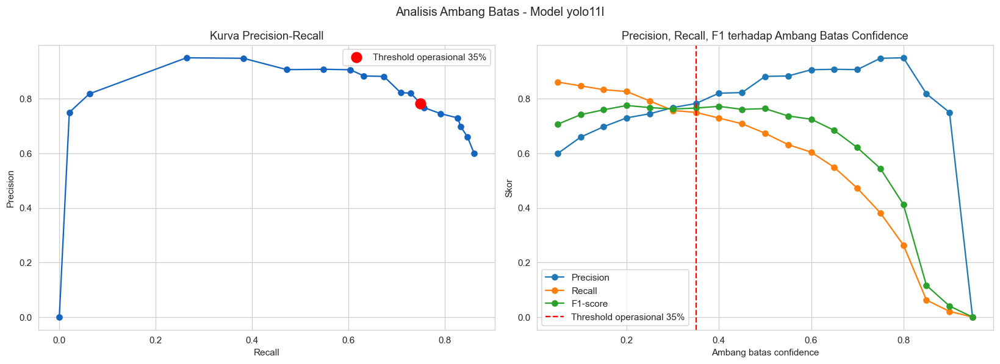

Titik operasional saat ini (threshold 35%): precision=0.7826, recall=0.7500, F1=0.7660
Threshold dengan F1 tertinggi secara matematis: 0.20 (precision=0.7301, recall=0.8264, F1=0.7752)
Catatan: threshold 85% dipilih berdasarkan kesepakatan tim yang memprioritaskan presisi tinggi,
bukan semata-mata untuk memaksimalkan F1-score.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
axes[0].plot(pr_curve_df["recall"], pr_curve_df["precision"], marker="o", color="#1565C0")
operating_point = pr_curve_df.iloc[(pr_curve_df["threshold"] - CONFIDENCE_THRESHOLD).abs().idxmin()]
axes[0].scatter([operating_point["recall"]], [operating_point["precision"]], color="red", s=120, zorder=5,
                label=f"Threshold operasional {CONFIDENCE_THRESHOLD:.0%}")
axes[0].set_xlabel("Recall"); axes[0].set_ylabel("Precision")
axes[0].set_title("Kurva Precision-Recall"); axes[0].legend()

axes[1].plot(pr_curve_df["threshold"], pr_curve_df["precision"], label="Precision", marker="o")
axes[1].plot(pr_curve_df["threshold"], pr_curve_df["recall"], label="Recall", marker="o")
axes[1].plot(pr_curve_df["threshold"], pr_curve_df["f1"], label="F1-score", marker="o")
axes[1].axvline(CONFIDENCE_THRESHOLD, color="red", linestyle="--", label=f"Threshold operasional {CONFIDENCE_THRESHOLD:.0%}")
axes[1].set_xlabel("Ambang batas confidence"); axes[1].set_ylabel("Skor"); axes[1].legend()
axes[1].set_title("Precision, Recall, F1 terhadap Ambang Batas Confidence")

plt.suptitle(f"Analisis Ambang Batas - Model {BEST_MODEL_NAME}", fontsize=13)
plt.tight_layout()
plt.savefig(f"{LOCAL_WORK_DIR}/plots/precision_recall_curve.png", bbox_inches="tight")
plt.show()

best_f1_row = pr_curve_df.loc[pr_curve_df["f1"].idxmax()]
print("Titik operasional saat ini (threshold {:.0%}): precision={:.4f}, recall={:.4f}, F1={:.4f}".format(
    CONFIDENCE_THRESHOLD, operating_point["precision"], operating_point["recall"], operating_point["f1"]))
print("Threshold dengan F1 tertinggi secara matematis: {:.2f} (precision={:.4f}, recall={:.4f}, F1={:.4f})".format(
    best_f1_row["threshold"], best_f1_row["precision"], best_f1_row["recall"], best_f1_row["f1"]))
print("Catatan: threshold 85% dipilih berdasarkan kesepakatan tim yang memprioritaskan presisi tinggi,")
print("bukan semata-mata untuk memaksimalkan F1-score.")

## 15. Diagram Kalibrasi Confidence Score

Diagram kalibrasi memeriksa apakah confidence score yang dikeluarkan model selaras dengan tingkat akurasi sesungguhnya. Idealnya, deteksi dengan confidence 80% seharusnya benar sekitar 80% dari kejadian (mendekati garis diagonal).

In [ ]:
all_scored_detections = []
for data in per_image_data:
    gt_boxes = data["gt_boxes"]
    matched_gt = set()
    for pred_class, conf, pred_box in data["pred_boxes"]:
        best_iou, best_gi = 0, -1
        for gi, (gt_class, gt_box) in enumerate(gt_boxes):
            if gi in matched_gt or gt_class != pred_class:
                continue
            iou = compute_iou(gt_box, pred_box)
            if iou > best_iou:
                best_iou, best_gi = iou, gi
        is_correct = best_iou >= IOU_MATCH_THRESHOLD
        if is_correct:
            matched_gt.add(best_gi)
        all_scored_detections.append({"confidence": conf, "is_correct": is_correct})

calib_df = pd.DataFrame(all_scored_detections)
bins = np.arange(0, 1.1, 0.1)
calib_df["bin"] = pd.cut(calib_df["confidence"], bins, include_lowest=True)
calibration_summary = calib_df.groupby("bin", observed=True).agg(rata_rata_confidence=("confidence", "mean"), tingkat_akurasi=("is_correct", "mean"), jumlah=("is_correct", "count")).reset_index()
print(calibration_summary)

             bin  rata_rata_confidence  tingkat_akurasi  jumlah
0  (-0.001, 0.1]              0.008421         0.012000     500
1     (0.1, 0.2]              0.146879         0.136364      22
2     (0.2, 0.3]              0.254849         0.476190      21
3     (0.3, 0.4]              0.355460         0.285714      14
4     (0.4, 0.5]              0.464358         0.444444      18
5     (0.5, 0.6]              0.553495         0.714286      14
6     (0.6, 0.7]              0.656653         0.904762      21
7     (0.7, 0.8]              0.754547         0.857143      35
8     (0.8, 0.9]              0.831861         0.972222      36
9     (0.9, 1.0]              0.915053         0.750000       4


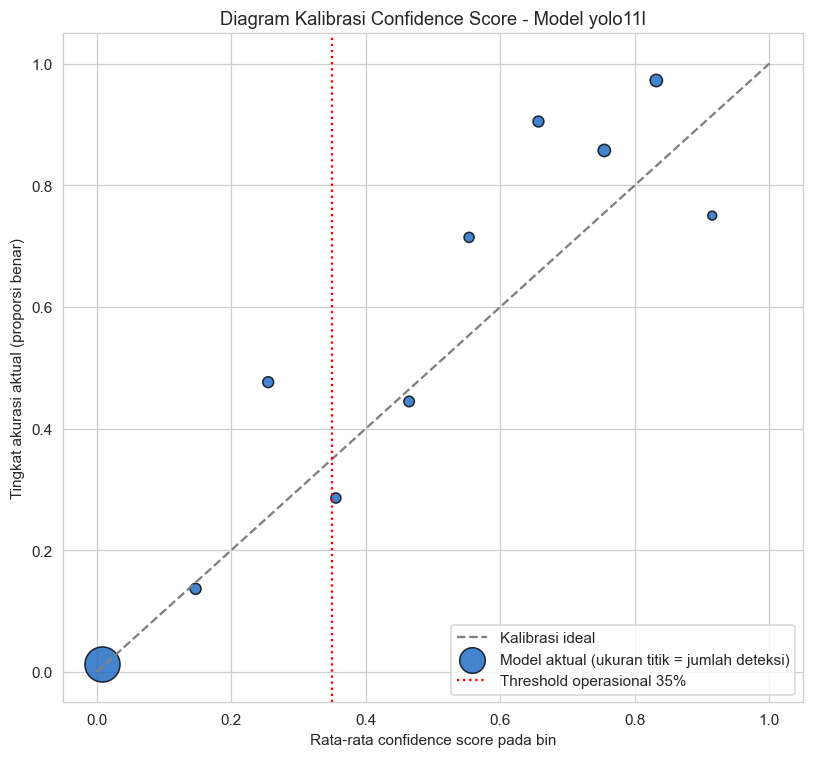

Expected Calibration Error (ECE): 0.0362
Semakin mendekati 0, semakin selaras confidence score model dengan akurasi aktualnya.


In [ ]:
fig, ax = plt.subplots(figsize=(7.5, 7))
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Kalibrasi ideal")
sizes = calibration_summary["jumlah"] / calibration_summary["jumlah"].max() * 500 + 30
ax.scatter(calibration_summary["rata_rata_confidence"], calibration_summary["tingkat_akurasi"], s=sizes, color="#1565C0", edgecolor="black", alpha=0.8, label="Model aktual (ukuran titik = jumlah deteksi)")
ax.axvline(CONFIDENCE_THRESHOLD, color="red", linestyle=":", label=f"Threshold operasional {CONFIDENCE_THRESHOLD:.0%}")
ax.set_xlabel("Rata-rata confidence score pada bin")
ax.set_ylabel("Tingkat akurasi aktual (proporsi benar)")
ax.set_title(f"Diagram Kalibrasi Confidence Score - Model {BEST_MODEL_NAME}")
ax.legend()
plt.tight_layout()
plt.savefig(f"{LOCAL_WORK_DIR}/plots/calibration_diagram.png", bbox_inches="tight")
plt.show()

calibration_error = (calibration_summary["rata_rata_confidence"] - calibration_summary["tingkat_akurasi"]).abs()
weighted_ece = (calibration_error * calibration_summary["jumlah"]).sum() / calibration_summary["jumlah"].sum()
print("Expected Calibration Error (ECE): {:.4f}".format(weighted_ece))
print("Semakin mendekati 0, semakin selaras confidence score model dengan akurasi aktualnya.")

## 16. Interval Kepercayaan (Bootstrap) untuk Precision, Recall, dan F1

Mengingat jumlah gambar pada split test relatif terbatas, estimasi metrik pada satu kali evaluasi berpotensi memiliki variansi yang cukup besar. Bootstrap resampling (pengambilan ulang gambar test secara acak dengan pengembalian sebanyak 1.000 kali) digunakan untuk mengestimasi rentang kepercayaan 95% dari precision, recall, dan F1-score pada threshold operasional (85%).

In [ ]:
def evaluate_on_image_subset(image_subset, threshold):
    tp, fp, fn = 0, 0, 0
    for data in image_subset:
        gt_boxes = data["gt_boxes"]
        preds = [(c, box) for c, conf, box in data["pred_boxes"] if conf >= threshold]
        matched_gt = set()
        for pred_class, pred_box in preds:
            best_iou, best_gi = 0, -1
            for gi, (gt_class, gt_box) in enumerate(gt_boxes):
                if gi in matched_gt or gt_class != pred_class:
                    continue
                iou = compute_iou(gt_box, pred_box)
                if iou > best_iou:
                    best_iou, best_gi = iou, gi
            if best_iou >= IOU_MATCH_THRESHOLD:
                matched_gt.add(best_gi)
                tp += 1
            else:
                fp += 1
        fn += len(gt_boxes) - len(matched_gt)
    precision = tp / (tp + fp + 1e-9)
    recall = tp / (tp + fn + 1e-9)
    f1 = 2 * precision * recall / (precision + recall + 1e-9)
    return precision, recall, f1

point_precision, point_recall, point_f1 = evaluate_on_image_subset(per_image_data, CONFIDENCE_THRESHOLD)

bootstrap_results = []
n_images = len(per_image_data)
for _ in tqdm(range(N_BOOTSTRAP), desc="Bootstrap resampling"):
    sample_idx = np.random.choice(n_images, size=n_images, replace=True)
    sample = [per_image_data[i] for i in sample_idx]
    p, r, f1 = evaluate_on_image_subset(sample, CONFIDENCE_THRESHOLD)
    bootstrap_results.append({"precision": p, "recall": r, "f1": f1})

bootstrap_df = pd.DataFrame(bootstrap_results)
ci_summary = {}
for metric, point_est in zip(["precision", "recall", "f1"], [point_precision, point_recall, point_f1]):
    lower, upper = np.percentile(bootstrap_df[metric], [2.5, 97.5])
    ci_summary[metric] = (point_est, lower, upper)
    print(f"{metric.capitalize()}: estimasi titik = {point_est:.4f}, interval kepercayaan 95% = [{lower:.4f}, {upper:.4f}]")

print()
print("Jumlah gambar pada data test:", n_images, "-> ukuran data test yang kecil menyebabkan interval kepercayaan cukup lebar,")
print("sehingga estimasi metrik pada laporan sebaiknya disertai rentang ini, bukan hanya angka tunggal.")

Bootstrap resampling:   0%|          | 0/1000 [00:00<?, ?it/s]

Precision: estimasi titik = 0.7826, interval kepercayaan 95% = [0.7122, 0.8489]
Recall: estimasi titik = 0.7500, interval kepercayaan 95% = [0.6552, 0.8394]
F1: estimasi titik = 0.7660, interval kepercayaan 95% = [0.6913, 0.8315]

Jumlah gambar pada data test: 110 -> ukuran data test yang kecil menyebabkan interval kepercayaan cukup lebar,
sehingga estimasi metrik pada laporan sebaiknya disertai rentang ini, bukan hanya angka tunggal.


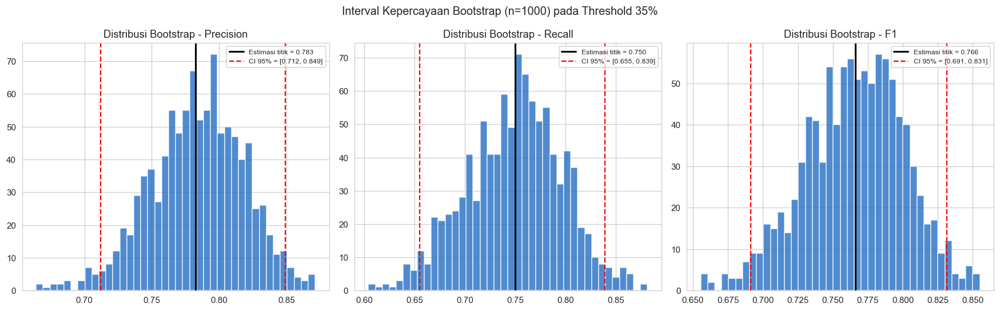

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, metric in zip(axes, ["precision", "recall", "f1"]):
    ax.hist(bootstrap_df[metric], bins=40, color="#1565C0", alpha=0.75)
    point_est, lower, upper = ci_summary[metric]
    ax.axvline(point_est, color="black", linewidth=2, label=f"Estimasi titik = {point_est:.3f}")
    ax.axvline(lower, color="red", linestyle="--", label=f"CI 95% = [{lower:.3f}, {upper:.3f}]")
    ax.axvline(upper, color="red", linestyle="--")
    ax.set_title(f"Distribusi Bootstrap - {metric.capitalize()}")
    ax.legend(fontsize=8)
plt.suptitle(f"Interval Kepercayaan Bootstrap (n={N_BOOTSTRAP}) pada Threshold {CONFIDENCE_THRESHOLD:.0%}", fontsize=13)
plt.tight_layout()
plt.savefig(f"{LOCAL_WORK_DIR}/plots/bootstrap_confidence_interval.png", bbox_inches="tight")
plt.show()

## 17. Perbandingan Statistik Antar Model (Bootstrap untuk Seluruh Model)

Bagian 16 hanya menghitung interval kepercayaan untuk model terbaik. Bagian ini memperluas analisis ke seluruh enam model, untuk menjawab pertanyaan penting: apakah model dengan mAP50 tertinggi **secara statistik signifikan** lebih baik dibandingkan model peringkat kedua, atau selisihnya masih berada dalam rentang kewajaran akibat ukuran data test yang kecil?

In [ ]:
def collect_predictions_for_model(model, label_files, img_dir):
    data_list = []
    for lbl_path in label_files:
        img_path = next(Path(img_dir).glob(f"{lbl_path.stem}.*"), None)
        if img_path is None:
            continue
        img = cv2.imread(str(img_path))
        img_h, img_w = img.shape[:2]
        gt_boxes = [(c, yolo_to_xyxy(x, y, w, h, img_w, img_h)) for c, x, y, w, h in parse_label_file(lbl_path)]
        result = model.predict(str(img_path), imgsz=IMG_SIZE, conf=0.001, verbose=False)[0]
        pred_boxes = []
        if result.boxes is not None:
            for box in result.boxes:
                pred_boxes.append((int(box.cls[0]), float(box.conf[0]), box.xyxy[0].cpu().numpy().tolist()))
        pred_boxes.sort(key=lambda x: x[1], reverse=True)
        data_list.append({"gt_boxes": gt_boxes, "pred_boxes": pred_boxes})
    return data_list

print("Fungsi pengumpulan prediksi lintas model siap. Menjalankan bootstrap untuk setiap model (mungkin memakan waktu beberapa menit)...")

Fungsi pengumpulan prediksi lintas model siap. Menjalankan bootstrap untuk setiap model (mungkin memakan waktu beberapa menit)...


In [ ]:
all_model_bootstrap = []
for model_filename in MODEL_LIST:
    run_name = get_run_name(model_filename)
    best_path = get_run_dir(model_filename) / "weights" / "best.pt"
    if not best_path.exists():
        continue
    model_temp = YOLO(str(best_path))
    data_for_model = collect_predictions_for_model(model_temp, test_label_files, subset_test_img)
    point_p, point_r, point_f1 = evaluate_on_image_subset(data_for_model, CONFIDENCE_THRESHOLD)

    boot_f1_scores = []
    for _ in range(N_BOOTSTRAP):
        sample_idx = np.random.choice(len(data_for_model), size=len(data_for_model), replace=True)
        sample = [data_for_model[i] for i in sample_idx]
        _, _, f1_sample = evaluate_on_image_subset(sample, CONFIDENCE_THRESHOLD)
        boot_f1_scores.append(f1_sample)
    lower, upper = np.percentile(boot_f1_scores, [2.5, 97.5])
    all_model_bootstrap.append({"model": run_name, "f1_point": point_f1, "f1_ci_lower": lower, "f1_ci_upper": upper})
    print(f"[{run_name}] F1 = {point_f1:.4f}, CI95% = [{lower:.4f}, {upper:.4f}]")

    del model_temp
    gc.collect()
    torch.cuda.empty_cache()

all_model_bootstrap_df = pd.DataFrame(all_model_bootstrap).sort_values("f1_point", ascending=False).reset_index(drop=True)
all_model_bootstrap_df

[yolo11l] F1 = 0.7660, CI95% = [0.6972, 0.8311]
[yolov8m] F1 = 0.7751, CI95% = [0.7112, 0.8344]
[yolo11m] F1 = 0.7664, CI95% = [0.6843, 0.8497]


,model,f1_point,f1_ci_lower,f1_ci_upper
0,yolov8m,0.775087,0.711240,0.834438
1,yolo11m,0.766423,0.684329,0.849681
2,yolo11l,0.765957,0.697173,0.831088


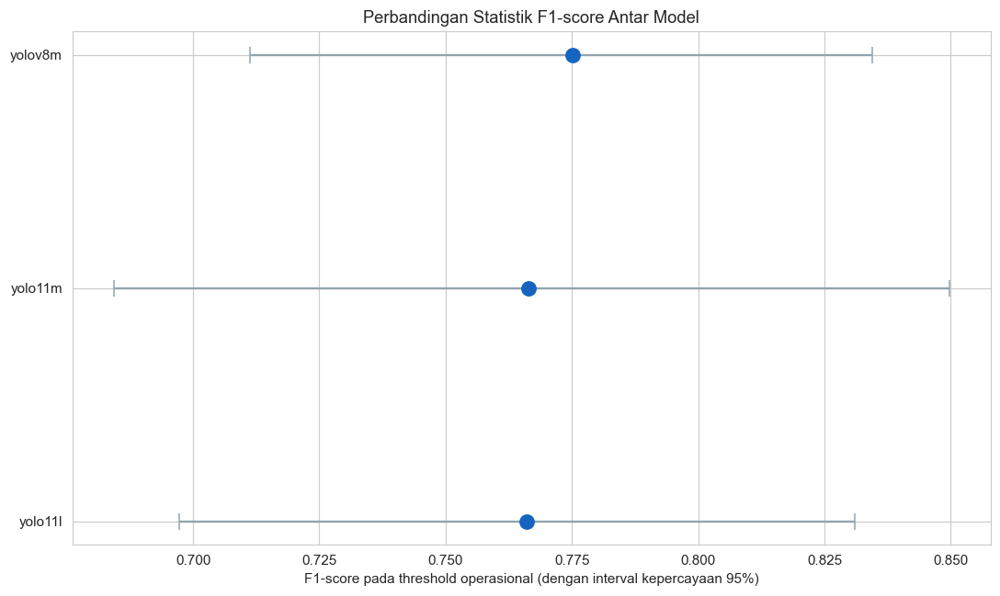

Model terbaik (yolov8m) vs peringkat kedua (yolo11m):
Interval kepercayaan KEDUA MODEL TUMPANG TINDIH -> keunggulan model terbaik BELUM TENTU signifikan secara statistik
dengan ukuran data test saat ini. Pertimbangkan kedua model sebagai kandidat yang sebanding.


In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))
y_pos = np.arange(len(all_model_bootstrap_df))
errors = [all_model_bootstrap_df["f1_point"] - all_model_bootstrap_df["f1_ci_lower"], all_model_bootstrap_df["f1_ci_upper"] - all_model_bootstrap_df["f1_point"]]
ax.errorbar(all_model_bootstrap_df["f1_point"], y_pos, xerr=errors, fmt="o", markersize=10, capsize=6, color="#1565C0", ecolor="#90A4AE")
ax.set_yticks(y_pos)
ax.set_yticklabels(all_model_bootstrap_df["model"])
ax.set_xlabel("F1-score pada threshold operasional (dengan interval kepercayaan 95%)")
ax.set_title("Perbandingan Statistik F1-score Antar Model")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(f"{LOCAL_WORK_DIR}/plots/statistical_model_comparison.png", bbox_inches="tight")
plt.show()

top_model = all_model_bootstrap_df.iloc[0]
runner_up = all_model_bootstrap_df.iloc[1] if len(all_model_bootstrap_df) > 1 else None
if runner_up is not None:
    overlap = not (top_model["f1_ci_lower"] > runner_up["f1_ci_upper"] or runner_up["f1_ci_lower"] > top_model["f1_ci_upper"])
    print(f"Model terbaik ({top_model['model']}) vs peringkat kedua ({runner_up['model']}):")
    if overlap:
        print("Interval kepercayaan KEDUA MODEL TUMPANG TINDIH -> keunggulan model terbaik BELUM TENTU signifikan secara statistik")
        print("dengan ukuran data test saat ini. Pertimbangkan kedua model sebagai kandidat yang sebanding.")
    else:
        print("Interval kepercayaan TIDAK tumpang tindih -> keunggulan model terbaik cukup meyakinkan secara statistik.")

## 18. Analisis Performa per Komoditas

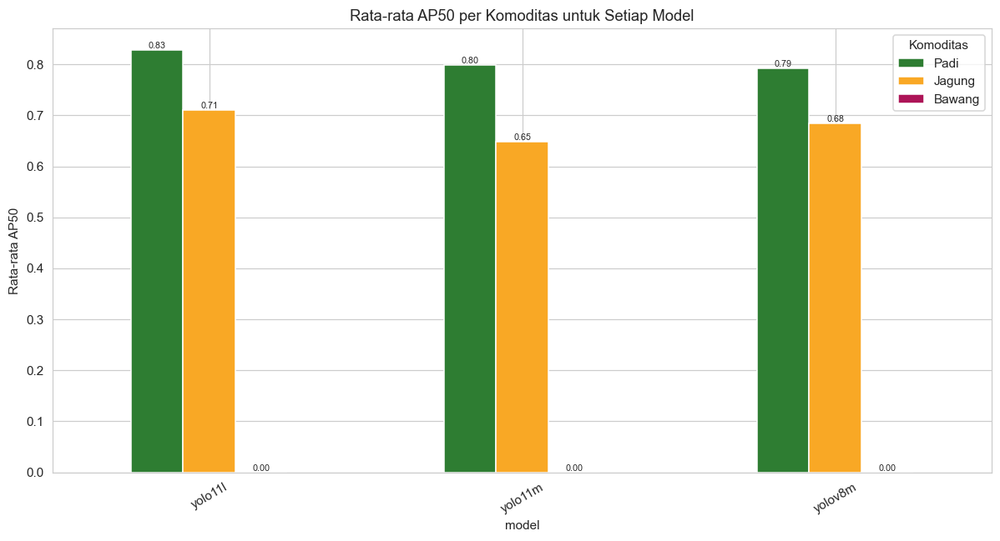

Rata-rata AP50 per komoditas (digabung seluruh model):
komoditas
Padi      0.806940
Jagung    0.681362
Bawang         NaN
dtype: float64

Insight: hasil ini PERLU DITINJAU ULANG terhadap ekspektasi awal proyek (padi > jagung > bawang).


In [ ]:
commodity_perf = per_class_df.groupby(["model", "komoditas"])["AP50"].mean().reset_index()
commodity_pivot = commodity_perf.pivot(index="model", columns="komoditas", values="AP50")[["Padi", "Jagung", "Bawang"]]

fig, ax = plt.subplots(figsize=(11, 6))
commodity_pivot.plot(kind="bar", ax=ax, color=[COMMODITY_COLOR["Padi"], COMMODITY_COLOR["Jagung"], COMMODITY_COLOR["Bawang"]])
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=7)
ax.set_ylabel("Rata-rata AP50")
ax.set_title("Rata-rata AP50 per Komoditas untuk Setiap Model")
ax.legend(title="Komoditas")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig(f"{LOCAL_WORK_DIR}/plots/commodity_performance.png", bbox_inches="tight")
plt.show()

commodity_rank = commodity_pivot.mean().sort_values(ascending=False)
print("Rata-rata AP50 per komoditas (digabung seluruh model):")
print(commodity_rank)
print()
print("Insight: hasil ini {} ekspektasi awal proyek (padi > jagung > bawang).".format(
    "MENGKONFIRMASI" if commodity_rank.idxmax() == "Padi" and commodity_rank.idxmin() == "Bawang" else "PERLU DITINJAU ULANG terhadap"))

## 19. Performa Berdasarkan Ukuran Objek (Gaya COCO: Kecil/Sedang/Besar)

Analisis ini mengukur ulang, menggunakan dimensi citra sesungguhnya (bukan asumsi 640x640 seperti pada Bagian 3.5), seberapa besar objek pada dataset final, dan bagaimana performa model berbeda pada tiap kategori ukuran. Hasil ini penting untuk menilai kesiapan model menghadapi kondisi nyata di alat perangkap, di mana hama kemungkinan tampak lebih kecil dalam frame dibandingkan foto close-up pada dataset publik.

In [ ]:
def categorize_size_px(box):
    area = (box[2] - box[0]) * (box[3] - box[1])
    if area < 32 ** 2:
        return "kecil (<32x32px)"
    elif area < 96 ** 2:
        return "sedang (32-96px)"
    else:
        return "besar (>96x96px)"

gt_size_records, fp_size_records = [], []
for data in per_image_data:
    gt_boxes = data["gt_boxes"]
    preds_at_thresh = [(c, box) for c, conf, box in data["pred_boxes"] if conf >= CONFIDENCE_THRESHOLD]
    matched_gt = set()
    for pred_class, pred_box in preds_at_thresh:
        best_iou, best_gi = 0, -1
        for gi, (gt_class, gt_box) in enumerate(gt_boxes):
            if gi in matched_gt or gt_class != pred_class:
                continue
            iou = compute_iou(gt_box, pred_box)
            if iou > best_iou:
                best_iou, best_gi = iou, gi
        if best_iou >= IOU_MATCH_THRESHOLD:
            matched_gt.add(best_gi)
        else:
            fp_size_records.append({"size_category": categorize_size_px(pred_box)})
    for gi, (gt_class, gt_box) in enumerate(gt_boxes):
        gt_size_records.append({"size_category": categorize_size_px(gt_box), "terdeteksi": gi in matched_gt})

gt_size_df = pd.DataFrame(gt_size_records)
size_distribution = gt_size_df["size_category"].value_counts()
print("Distribusi ukuran objek pada data test (dimensi piksel sesungguhnya):")
print(size_distribution)
print()
recall_by_size = gt_size_df.groupby("size_category")["terdeteksi"].mean().reindex(["kecil (<32x32px)", "sedang (32-96px)", "besar (>96x96px)"])
print("Recall (tingkat terdeteksi) per kategori ukuran objek:")
print(recall_by_size)

Distribusi ukuran objek pada data test (dimensi piksel sesungguhnya):
size_category
besar (>96x96px)    130
sedang (32-96px)     14
Name: count, dtype: int64

Recall (tingkat terdeteksi) per kategori ukuran objek:
size_category
kecil (<32x32px)         NaN
sedang (32-96px)    0.571429
besar (>96x96px)    0.769231
Name: terdeteksi, dtype: float64


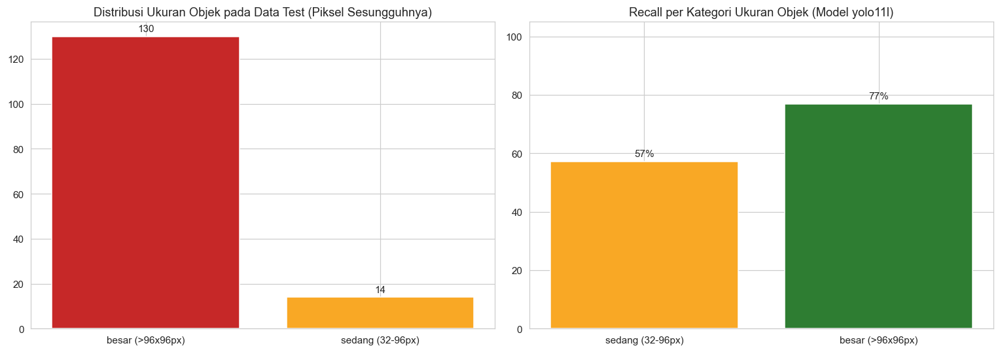

Insight: tidak ditemukan penurunan recall yang berarti pada objek kecil dibandingkan objek besar pada data test ini.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
bars1 = axes[0].bar(size_distribution.index, size_distribution.values, color=["#C62828", "#F9A825", "#2E7D32"])
axes[0].bar_label(bars1, padding=3)
axes[0].set_title("Distribusi Ukuran Objek pada Data Test (Piksel Sesungguhnya)")

bars2 = axes[1].bar(recall_by_size.index, recall_by_size.values * 100, color=["#C62828", "#F9A825", "#2E7D32"])
axes[1].bar_label(bars2, fmt="%.0f%%", padding=3)
axes[1].set_title(f"Recall per Kategori Ukuran Objek (Model {BEST_MODEL_NAME})")
axes[1].set_ylim(0, 105)

plt.tight_layout()
plt.savefig(f"{LOCAL_WORK_DIR}/plots/performance_by_size_category.png", bbox_inches="tight")
plt.show()

if recall_by_size.get("kecil (<32x32px)", np.nan) < recall_by_size.get("besar (>96x96px)", np.nan):
    print("Insight: recall pada objek kecil lebih rendah dibandingkan objek besar, mengonfirmasi kekhawatiran domain gap")
    print("pada Bagian 3.5. Prioritaskan pengumpulan data tambahan dengan objek berukuran kecil (foto jarak jauh/wide-angle)")
    print("untuk melatih ulang model sebelum deployment penuh di alat perangkap.")
else:
    print("Insight: tidak ditemukan penurunan recall yang berarti pada objek kecil dibandingkan objek besar pada data test ini.")

## 20. Optimasi Ambang Batas Confidence per Kelas

Ambang batas tunggal 85% diterapkan secara global untuk seluruh kelas sesuai kesepakatan tim. Sebagai bahan pertimbangan lebih lanjut, bagian ini menghitung ambang batas optimal (memaksimalkan F1-score) untuk **setiap kelas secara terpisah**, karena karakteristik tiap kelas (ukuran, kemiripan visual dengan kelas lain) dapat berbeda signifikan.

In [ ]:
def evaluate_class_at_threshold(class_id, threshold):
    tp, fp, fn = 0, 0, 0
    for data in per_image_data:
        gt_boxes = [(c, box) for c, box in data["gt_boxes"] if c == class_id]
        preds = [(c, box) for c, conf, box in data["pred_boxes"] if conf >= threshold and c == class_id]
        matched_gt = set()
        for pred_class, pred_box in preds:
            best_iou, best_gi = 0, -1
            for gi, (gt_class, gt_box) in enumerate(gt_boxes):
                if gi in matched_gt:
                    continue
                iou = compute_iou(gt_box, pred_box)
                if iou > best_iou:
                    best_iou, best_gi = iou, gi
            if best_iou >= IOU_MATCH_THRESHOLD:
                matched_gt.add(best_gi)
                tp += 1
            else:
                fp += 1
        fn += len(gt_boxes) - len(matched_gt)
    precision = tp / (tp + fp + 1e-9)
    recall = tp / (tp + fn + 1e-9)
    f1 = 2 * precision * recall / (precision + recall + 1e-9)
    return precision, recall, f1

print("Fungsi evaluasi per kelas pada ambang batas tertentu siap digunakan.")

Fungsi evaluasi per kelas pada ambang batas tertentu siap digunakan.


In [ ]:
per_class_threshold_results = []
threshold_candidates = np.arange(0.10, 0.96, 0.05)
for class_id in tqdm(range(N_CLASSES), desc="Mencari ambang batas optimal per kelas"):
    total_gt_this_class = sum(1 for data in per_image_data for c, _ in data["gt_boxes"] if c == class_id)
    if total_gt_this_class == 0:
        continue
    f1_scores = [(t,) + evaluate_class_at_threshold(class_id, t) for t in threshold_candidates]
    best_row = max(f1_scores, key=lambda x: x[3])
    _, _, _, f1_at_global = (CONFIDENCE_THRESHOLD,) + evaluate_class_at_threshold(class_id, CONFIDENCE_THRESHOLD)
    per_class_threshold_results.append({
        "kelas": SUBSET_NAMES[class_id], "nama_indonesia": SUBSET_NAME_ID[class_id], "komoditas": SUBSET_COMMODITY[class_id],
        "threshold_optimal": best_row[0], "f1_pada_optimal": best_row[3], "f1_pada_threshold_global_85": f1_at_global,
    })

per_class_threshold_df = pd.DataFrame(per_class_threshold_results).sort_values("f1_pada_optimal", ascending=False)
per_class_threshold_df["selisih_f1"] = per_class_threshold_df["f1_pada_optimal"] - per_class_threshold_df["f1_pada_threshold_global_85"]
per_class_threshold_df

Mencari ambang batas optimal per kelas:   0%|          | 0/24 [00:00<?, ?it/s]

,kelas,nama_indonesia,komoditas,threshold_optimal,f1_pada_optimal,f1_pada_threshold_global_85,selisih_f1
17,mole cricket,Anjing tanah / orong-orong,Bawang,0.10,1.000000,1.000000,0.000000
18,wireworm,Uret kawat,Bawang,0.35,1.000000,1.000000,0.000000
0,rice leaf roller,Penggulung daun padi,Padi,0.30,1.000000,1.000000,0.000000
8,rice water weevil,Kumbang moncong air padi,Padi,0.15,1.000000,1.000000,0.000000
9,rice leafhopper,Wereng hijau,Padi,0.15,1.000000,1.000000,0.000000
3,yellow rice borer,Penggerek batang padi kuning,Padi,0.25,1.000000,1.000000,0.000000
16,grub,Uret (larva kumbang tanah),Bawang,0.15,0.950000,0.923077,0.026923
10,corn borer,Penggerek batang jagung,Jagung,0.35,0.857143,0.857143,0.000000
2,asiatic rice borer,Penggerek batang padi bergaris,Padi,0.10,0.833333,0.727273,0.106061
12,aphids,Kutu daun jagung,Jagung,0.20,0.757895,0.729412,0.028483


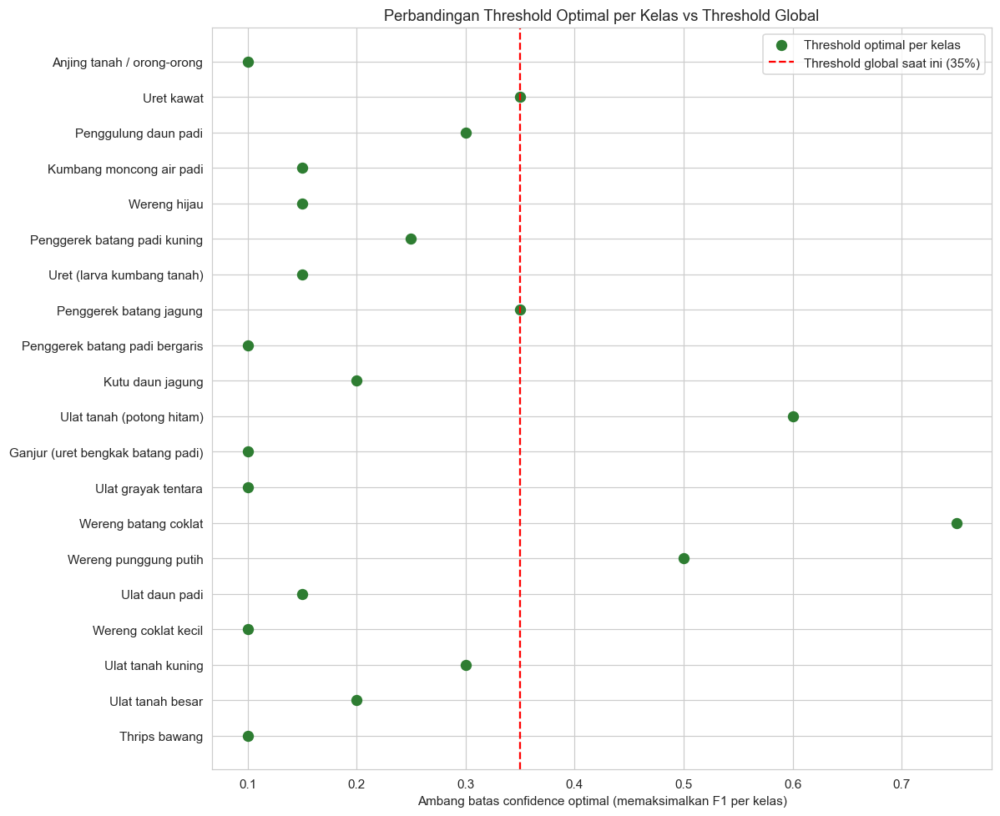

Terdapat 8 kelas dengan potensi peningkatan F1 lebih dari 0.05 apabila menggunakan threshold khusus per kelas:
                        kelas                  nama_indonesia  \
2          asiatic rice borer  Penggerek batang padi bergaris   
13              black cutworm       Ulat tanah (potong hitam)   
11                  army worm             Ulat grayak tentara   
5          brown plant hopper            Wereng batang coklat   
6   white backed plant hopper           Wereng punggung putih   
1       rice leaf caterpillar                  Ulat daun padi   
7    small brown plant hopper             Wereng coklat kecil   
14              large cutworm                Ulat tanah besar   

    threshold_optimal  f1_pada_optimal  f1_pada_threshold_global_85  
2                0.10         0.833333                     0.727273  
13               0.60         0.750000                     0.526316  
11               0.10         0.666667                     0.400000  
5                0.75  

In [ ]:
fig, ax = plt.subplots(figsize=(11, 9))
y_pos = np.arange(len(per_class_threshold_df))
ax.scatter(per_class_threshold_df["threshold_optimal"], y_pos, color="#2E7D32", s=60, label="Threshold optimal per kelas")
ax.axvline(CONFIDENCE_THRESHOLD, color="red", linestyle="--", label=f"Threshold global saat ini ({CONFIDENCE_THRESHOLD:.0%})")
ax.set_yticks(y_pos)
ax.set_yticklabels(per_class_threshold_df["nama_indonesia"])
ax.set_xlabel("Ambang batas confidence optimal (memaksimalkan F1 per kelas)")
ax.set_title("Perbandingan Threshold Optimal per Kelas vs Threshold Global")
ax.legend()
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(f"{LOCAL_WORK_DIR}/plots/per_class_threshold_optimization.png", bbox_inches="tight")
plt.show()

significant_diff = per_class_threshold_df[per_class_threshold_df["selisih_f1"] > 0.05]
if len(significant_diff) > 0:
    print(f"Terdapat {len(significant_diff)} kelas dengan potensi peningkatan F1 lebih dari 0.05 apabila menggunakan threshold khusus per kelas:")
    print(significant_diff[["kelas", "nama_indonesia", "threshold_optimal", "f1_pada_optimal", "f1_pada_threshold_global_85"]])
    print()
    print("Pertimbangan: threshold per kelas dapat meningkatkan performa, namun menambah kompleksitas implementasi di backend")
    print("(perlu menyimpan dan menerapkan mapping threshold per kelas, bukan satu angka tunggal).")
else:
    print("Threshold global 85% sudah cukup mendekati optimal untuk sebagian besar kelas, tidak ditemukan potensi peningkatan signifikan.")

## 21. Analisis Efisiensi (Akurasi vs Kecepatan vs Ukuran)

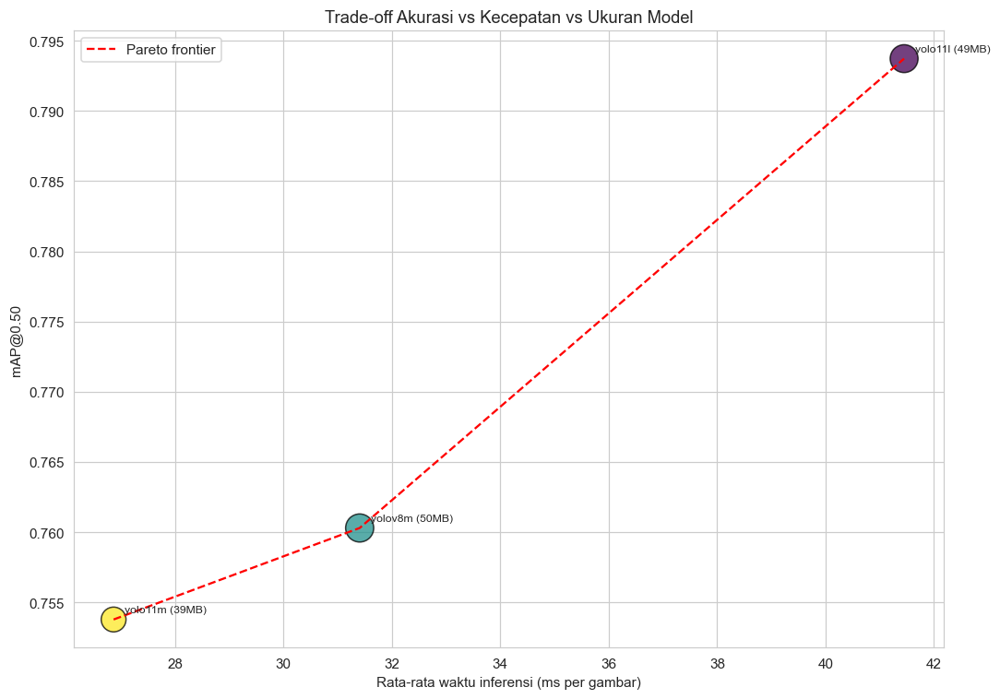

Model pada garis efisiensi optimal (Pareto frontier): ['yolo11m', 'yolov8m', 'yolo11l']

Rekomendasi akhir: karena inferensi berjalan di server dengan interval satu jam sekali (bukan real-time),
kecepatan bukan faktor pembatas utama, sehingga model dengan akurasi tertinggi (yolo11l) menjadi kandidat utama.


In [ ]:
fig, ax = plt.subplots(figsize=(10, 7))
sizes_scaled = comparison_table["model_size_mb"] * 8
ax.scatter(comparison_table["avg_inference_ms"], comparison_table["mAP50"], s=sizes_scaled, c=range(len(comparison_table)), cmap="viridis", alpha=0.75, edgecolor="black")
for _, row in comparison_table.iterrows():
    ax.annotate(f"{row['model']} ({row['model_size_mb']:.0f}MB)", (row["avg_inference_ms"], row["mAP50"]), textcoords="offset points", xytext=(8, 5), fontsize=8)

sorted_by_speed = comparison_table.sort_values("avg_inference_ms")
pareto_points, best_map_so_far = [], -1
for _, row in sorted_by_speed.iterrows():
    if row["mAP50"] > best_map_so_far:
        pareto_points.append(row); best_map_so_far = row["mAP50"]
pareto_df = pd.DataFrame(pareto_points)
ax.plot(pareto_df["avg_inference_ms"], pareto_df["mAP50"], "r--", linewidth=1.5, label="Pareto frontier")
ax.set_xlabel("Rata-rata waktu inferensi (ms per gambar)")
ax.set_ylabel("mAP@0.50")
ax.set_title("Trade-off Akurasi vs Kecepatan vs Ukuran Model")
ax.legend()
plt.tight_layout()
plt.savefig(f"{LOCAL_WORK_DIR}/plots/efficiency_frontier.png", bbox_inches="tight")
plt.show()

print("Model pada garis efisiensi optimal (Pareto frontier):", pareto_df["model"].tolist())
print()
print("Rekomendasi akhir: karena inferensi berjalan di server dengan interval satu jam sekali (bukan real-time),")
print("kecepatan bukan faktor pembatas utama, sehingga model dengan akurasi tertinggi ({}) menjadi kandidat utama.".format(BEST_MODEL_NAME))

## 22. Uji Ketahanan (Robustness Stress Test)

Alat perangkap beroperasi pada malam hari menggunakan lampu UV, dan kamera menghadap wadah penampung dari jarak tertentu. Untuk menyimulasikan variasi kondisi nyata yang mungkin dihadapi, tiga jenis gangguan citra diterapkan secara sintetis pada data test, dan performa model dievaluasi ulang pada tiap kondisi:

- **Blur** (mensimulasikan citra kurang fokus atau sedikit bergerak)
- **Kecerahan rendah** (mensimulasikan kondisi pencahayaan UV yang kurang optimal pada malam hari)
- **Downscale-upscale** (mensimulasikan hama yang tampak kecil/jauh dari kamera, konsisten dengan risiko domain gap pada Bagian 3.5 dan 19)

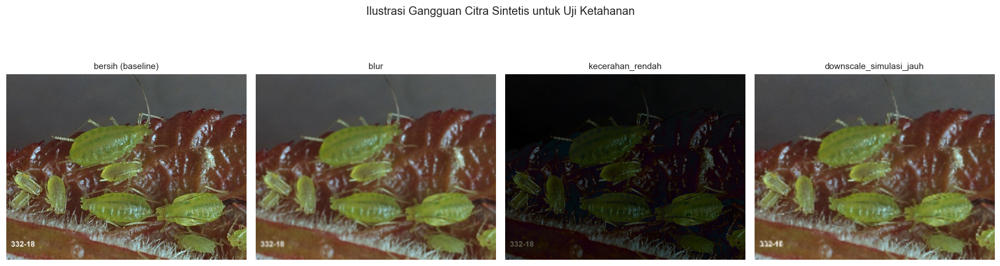

In [ ]:
def apply_corruption(img, corruption_type):
    if corruption_type == "blur":
        return cv2.GaussianBlur(img, (9, 9), 0)
    elif corruption_type == "kecerahan_rendah":
        return cv2.convertScaleAbs(img, alpha=0.5, beta=-30)
    elif corruption_type == "downscale_simulasi_jauh":
        h, w = img.shape[:2]
        small = cv2.resize(img, (w // 4, h // 4), interpolation=cv2.INTER_LINEAR)
        return cv2.resize(small, (w, h), interpolation=cv2.INTER_LINEAR)
    return img
test_images_list = list(Path(subset_test_img).glob("*"))
sample_corruption_preview = cv2.cvtColor(cv2.imread(str(random.choice(test_images_list))), cv2.COLOR_BGR2RGB)
fig, axes = plt.subplots(1, 4, figsize=(16, 5))
for ax, ctype in zip(axes, ["bersih (baseline)", "blur", "kecerahan_rendah", "downscale_simulasi_jauh"]):
    img_show = sample_corruption_preview if ctype == "bersih (baseline)" else cv2.cvtColor(apply_corruption(cv2.cvtColor(sample_corruption_preview, cv2.COLOR_RGB2BGR), ctype), cv2.COLOR_BGR2RGB)
    ax.imshow(img_show)
    ax.set_title(ctype, fontsize=10)
    ax.axis("off")
plt.suptitle("Ilustrasi Gangguan Citra Sintetis untuk Uji Ketahanan", fontsize=13)
plt.tight_layout()
plt.savefig(f"{LOCAL_WORK_DIR}/plots/robustness_corruption_preview.png", bbox_inches="tight")
plt.show()

In [ ]:
def evaluate_robustness(corruption_type, threshold=CONFIDENCE_THRESHOLD):
    tp, fp, fn = 0, 0, 0
    for lbl_path in test_label_files:
        img_path = next(Path(subset_test_img).glob(f"{lbl_path.stem}.*"), None)
        if img_path is None:
            continue
        img = cv2.imread(str(img_path))
        img_h, img_w = img.shape[:2]
        gt_boxes = [(c, yolo_to_xyxy(x, y, w, h, img_w, img_h)) for c, x, y, w, h in parse_label_file(lbl_path)]

        corrupted_img = apply_corruption(img, corruption_type) if corruption_type != "bersih (baseline)" else img
        result = best_model.predict(corrupted_img, imgsz=IMG_SIZE, conf=threshold, verbose=False)[0]
        preds = []
        if result.boxes is not None:
            for box in result.boxes:
                preds.append((int(box.cls[0]), box.xyxy[0].cpu().numpy().tolist()))

        matched_gt = set()
        for pred_class, pred_box in preds:
            best_iou, best_gi = 0, -1
            for gi, (gt_class, gt_box) in enumerate(gt_boxes):
                if gi in matched_gt or gt_class != pred_class:
                    continue
                iou = compute_iou(gt_box, pred_box)
                if iou > best_iou:
                    best_iou, best_gi = iou, gi
            if best_iou >= IOU_MATCH_THRESHOLD:
                matched_gt.add(best_gi)
                tp += 1
            else:
                fp += 1
        fn += len(gt_boxes) - len(matched_gt)
    precision = tp / (tp + fp + 1e-9)
    recall = tp / (tp + fn + 1e-9)
    f1 = 2 * precision * recall / (precision + recall + 1e-9)
    return precision, recall, f1

print("Fungsi evaluasi ketahanan siap. Menjalankan pada seluruh jenis gangguan...")

Fungsi evaluasi ketahanan siap. Menjalankan pada seluruh jenis gangguan...


In [ ]:
corruption_types = ["bersih (baseline)", "blur", "kecerahan_rendah", "downscale_simulasi_jauh"]
robustness_results = []
for ctype in tqdm(corruption_types, desc="Menguji ketahanan terhadap gangguan citra"):
    p, r, f1 = evaluate_robustness(ctype)
    robustness_results.append({"kondisi": ctype, "precision": p, "recall": r, "f1_score": f1})

robustness_df = pd.DataFrame(robustness_results)
robustness_df

Menguji ketahanan terhadap gangguan citra:   0%|          | 0/4 [00:00<?, ?it/s]

,kondisi,precision,recall,f1_score
0,bersih (baseline),0.782609,0.750000,0.765957
1,blur,0.736842,0.583333,0.651163
2,kecerahan_rendah,0.731343,0.680556,0.705036
3,downscale_simulasi_jauh,0.723810,0.527778,0.610442


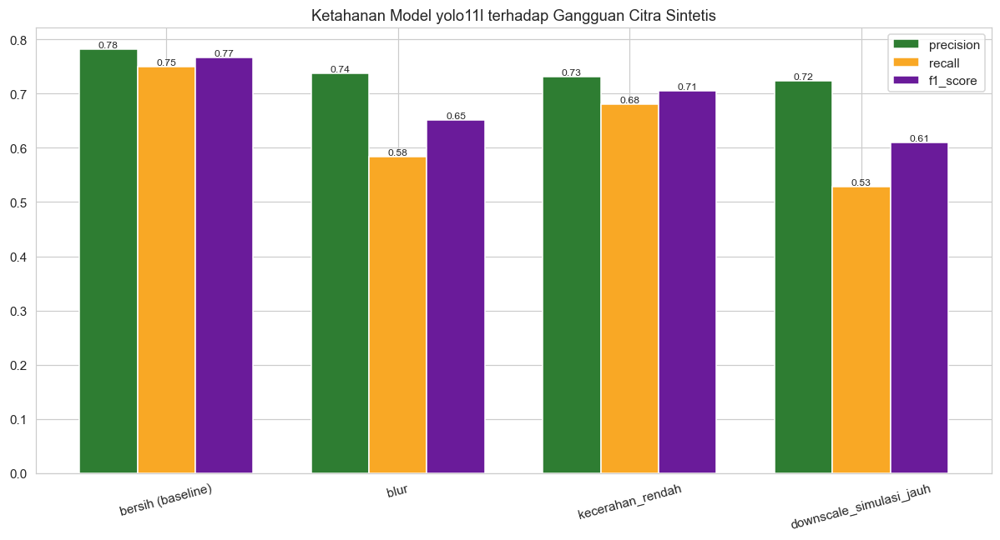

Penurunan F1-score relatif terhadap kondisi baseline (bersih):
 - blur: penurunan 15.0% -> dapat diterima
 - kecerahan_rendah: penurunan 8.0% -> dapat diterima
 - downscale_simulasi_jauh: penurunan 20.3% -> PERLU PERHATIAN


In [ ]:
fig, ax = plt.subplots(figsize=(11, 6))
x = np.arange(len(robustness_df))
width = 0.25
for i, (metric, color) in enumerate(zip(["precision", "recall", "f1_score"], ["#2E7D32", "#F9A825", "#6A1B9A"])):
    bars = ax.bar(x + (i - 1) * width, robustness_df[metric], width, label=metric, color=color)
    ax.bar_label(bars, fmt="%.2f", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(robustness_df["kondisi"], rotation=15)
ax.set_title(f"Ketahanan Model {BEST_MODEL_NAME} terhadap Gangguan Citra Sintetis")
ax.legend()
plt.tight_layout()
plt.savefig(f"{LOCAL_WORK_DIR}/plots/robustness_stress_test.png", bbox_inches="tight")
plt.show()

baseline_f1 = robustness_df.loc[robustness_df["kondisi"] == "bersih (baseline)", "f1_score"].values[0]
print("Penurunan F1-score relatif terhadap kondisi baseline (bersih):")
for _, row in robustness_df.iterrows():
    if row["kondisi"] == "bersih (baseline)":
        continue
    drop_pct = 100 * (baseline_f1 - row["f1_score"]) / max(baseline_f1, 1e-9)
    flag = "PERLU PERHATIAN" if drop_pct > 20 else "dapat diterima"
    print(f" - {row['kondisi']}: penurunan {drop_pct:.1f}% -> {flag}")

## 23. Benchmark Presisi Inferensi (FP32 vs FP16)

Menjalankan model dengan setengah presisi (FP16/half precision) pada GPU dapat mempercepat inferensi signifikan dengan potensi sedikit penurunan akurasi. Informasi ini berguna bagi tim backend dalam merencanakan kapasitas server, terutama apabila di masa depan jumlah unit alat bertambah dan volume citra yang diproses meningkat.

In [ ]:
test_images_for_benchmark = list(Path(subset_test_img).glob("*"))[:30]

start_fp32 = time.time()
for img_path in test_images_for_benchmark:
    _ = best_model.predict(str(img_path), imgsz=IMG_SIZE, conf=CONFIDENCE_THRESHOLD, half=False, verbose=False)
time_fp32 = (time.time() - start_fp32) / len(test_images_for_benchmark) * 1000

half_precision_available = torch.cuda.is_available()
if half_precision_available:
    start_fp16 = time.time()
    for img_path in test_images_for_benchmark:
        _ = best_model.predict(str(img_path), imgsz=IMG_SIZE, conf=CONFIDENCE_THRESHOLD, half=True, verbose=False)
    time_fp16 = (time.time() - start_fp16) / len(test_images_for_benchmark) * 1000
else:
    time_fp16 = np.nan
    print("GPU tidak tersedia pada sesi ini, benchmark FP16 dilewati (FP16 memerlukan CUDA).")

precision_benchmark_df = pd.DataFrame({"mode": ["FP32", "FP16"], "avg_inference_ms": [time_fp32, time_fp16]})
print(precision_benchmark_df)

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.

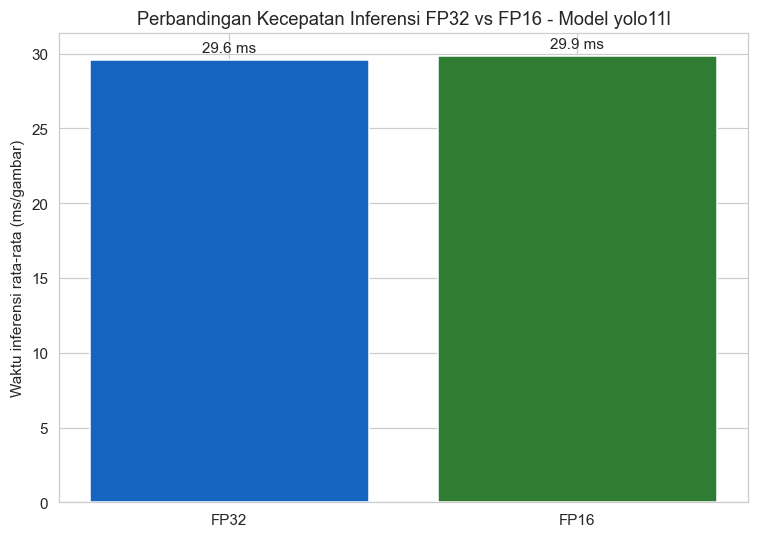

Percepatan dari FP16: 0.99x lebih cepat dibandingkan FP32.
Catatan: karena interval capture satu jam sekali, percepatan ini tidak krusial untuk kasus ini,
namun tetap bermanfaat untuk efisiensi biaya komputasi server dalam jangka panjang.


In [ ]:
if half_precision_available:
    fig, ax = plt.subplots(figsize=(7, 5))
    bars = ax.bar(precision_benchmark_df["mode"], precision_benchmark_df["avg_inference_ms"], color=["#1565C0", "#2E7D32"])
    ax.bar_label(bars, fmt="%.1f ms", padding=3)
    ax.set_title(f"Perbandingan Kecepatan Inferensi FP32 vs FP16 - Model {BEST_MODEL_NAME}")
    ax.set_ylabel("Waktu inferensi rata-rata (ms/gambar)")
    plt.tight_layout()
    plt.savefig(f"{LOCAL_WORK_DIR}/plots/precision_benchmark.png", bbox_inches="tight")
    plt.show()

    speedup = time_fp32 / time_fp16 if time_fp16 > 0 else np.nan
    print(f"Percepatan dari FP16: {speedup:.2f}x lebih cepat dibandingkan FP32.")
    print("Catatan: karena interval capture satu jam sekali, percepatan ini tidak krusial untuk kasus ini,")
    print("namun tetap bermanfaat untuk efisiensi biaya komputasi server dalam jangka panjang.")
else:
    print("Dilewati karena tidak ada GPU pada sesi ini.")

## 24. Visualisasi Contoh Hasil Prediksi

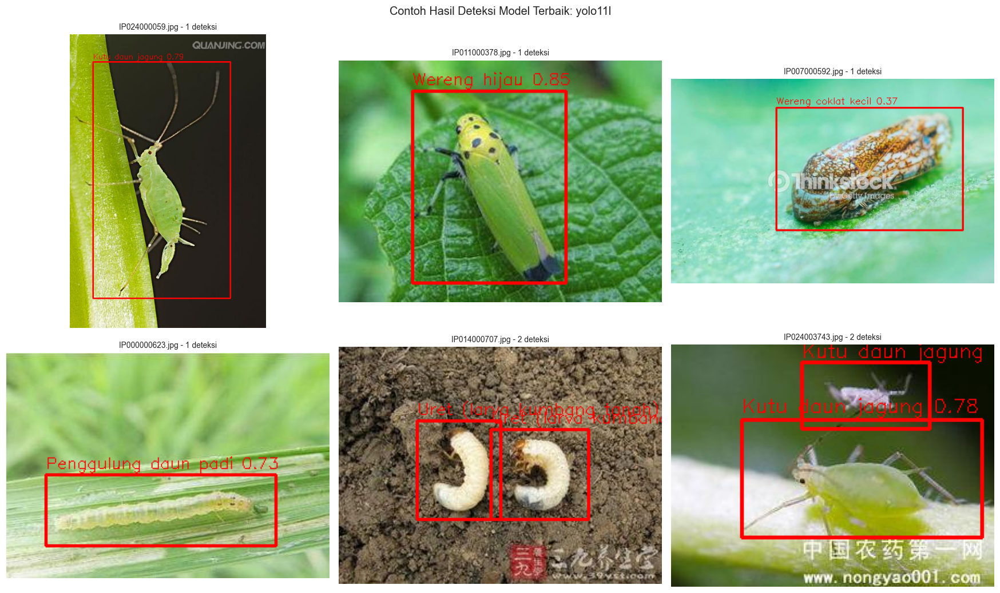

In [ ]:
os.makedirs(f"{LOCAL_WORK_DIR}/sample_predictions", exist_ok=True)
test_images_list = [d["image_path"] for d in per_image_data]
sample_test_for_viz = random.sample(test_images_list, min(6, len(test_images_list)))

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, img_path in zip(axes.flatten(), sample_test_for_viz):
    results = best_model.predict(str(img_path), imgsz=IMG_SIZE, conf=CONFIDENCE_THRESHOLD, verbose=False)
    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    r = results[0]
    n_detections = 0
    if r.boxes is not None:
        for box in r.boxes:
            x1, y1, x2, y2 = box.xyxy[0].cpu().numpy().astype(int)
            conf, cls_id = float(box.conf[0]), int(box.cls[0])
            cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 2)
            cv2.putText(img, f"{SUBSET_NAME_ID[cls_id]} {conf:.2f}", (x1, max(y1 - 6, 10)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 1)
            n_detections += 1
    ax.imshow(img)
    ax.set_title(f"{img_path.name} - {n_detections} deteksi", fontsize=9)
    ax.axis("off")
    cv2.imwrite(f"{LOCAL_WORK_DIR}/sample_predictions/pred_{img_path.name}", cv2.cvtColor(img, cv2.COLOR_RGB2BGR))
plt.suptitle(f"Contoh Hasil Deteksi Model Terbaik: {BEST_MODEL_NAME}", fontsize=13)
plt.tight_layout()
plt.savefig(f"{LOCAL_WORK_DIR}/sample_predictions/grid_overview.png", bbox_inches="tight")
plt.show()

## 25. Validasi Konsistensi Model ONNX

Sebelum paket model diserahkan ke tim backend, model terbaik diekspor ke format ONNX dan divalidasi konsistensinya terhadap model PyTorch asli (`.pt`), untuk memastikan tidak ada perbedaan hasil yang berarti akibat proses konversi format.

In [ ]:
onnx_validation_path = best_model.export(format="onnx", imgsz=IMG_SIZE)
onnx_model_check = YOLO(onnx_validation_path)
print("Model ONNX berhasil diekspor sementara untuk validasi:", onnx_validation_path)

Ultralytics 8.4.135 🚀 Python-3.13.15 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino

PyTorch: starting from '/content/drive/MyDrive/dataset_objectdetect_AIGRA/hasil_training/train_runs/yolo11l/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 28, 8400) (48.9 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 12 packages in 398ms
Prepared 4 packages in 2.39s
Installed 4 packages in 408ms
 + colorama==0.4.6
 + onnx==1.22.0
 + onnxruntime==1.29.0
 + onnxslim==0.1.96

requirements: AutoUpdate success ✅ 4.1s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.22.0 opset 18...
ONNX: slimming with onnxslim 0.1.96...
ON

In [ ]:
validation_sample_images = random.sample(test_images_list, min(10, len(test_images_list)))
consistency_records = []

for img_path in validation_sample_images:
    result_pt = best_model.predict(str(img_path), imgsz=IMG_SIZE, conf=0.25, verbose=False)[0]
    result_onnx = onnx_model_check.predict(str(img_path), imgsz=IMG_SIZE, conf=0.25, verbose=False)[0]

    n_det_pt = len(result_pt.boxes) if result_pt.boxes is not None else 0
    n_det_onnx = len(result_onnx.boxes) if result_onnx.boxes is not None else 0

    conf_pt = sorted(result_pt.boxes.conf.cpu().numpy().tolist(), reverse=True) if n_det_pt > 0 else []
    conf_onnx = sorted(result_onnx.boxes.conf.cpu().numpy().tolist(), reverse=True) if n_det_onnx > 0 else []
    max_conf_diff = abs(conf_pt[0] - conf_onnx[0]) if conf_pt and conf_onnx else np.nan

    consistency_records.append({
        "gambar": img_path.name, "deteksi_pt": n_det_pt, "deteksi_onnx": n_det_onnx,
        "selisih_jumlah_deteksi": abs(n_det_pt - n_det_onnx), "selisih_confidence_tertinggi": max_conf_diff,
    })

consistency_df = pd.DataFrame(consistency_records)
print(consistency_df)

mean_count_diff = consistency_df["selisih_jumlah_deteksi"].mean()
mean_conf_diff = consistency_df["selisih_confidence_tertinggi"].mean()
print()
print(f"Rata-rata selisih jumlah deteksi (PT vs ONNX): {mean_count_diff:.2f}")
print(f"Rata-rata selisih confidence tertinggi (PT vs ONNX): {mean_conf_diff:.4f}")

if mean_count_diff <= 0.5 and (np.isnan(mean_conf_diff) or mean_conf_diff <= 0.02):
    print("Status validasi: KONSISTEN. Model ONNX aman digunakan sebagai pengganti model PyTorch pada backend.")
else:
    print("Status validasi: TERDAPAT PERBEDAAN. Disarankan investigasi lebih lanjut sebelum menggunakan versi ONNX di produksi.")

del onnx_model_check
gc.collect()

Loading /content/drive/MyDrive/dataset_objectdetect_AIGRA/hasil_training/train_runs/yolo11l/weights/best.onnx for ONNX Runtime inference...
requirements: Ultralytics requirement ['onnxruntime-gpu'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 5 packages in 142ms
Prepared 1 package in 6.76s
Installed 1 package in 57ms
 + onnxruntime-gpu==1.29.0

requirements: AutoUpdate success ✅ 7.1s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

WARNING ⚠️ CUDA requested but CUDAExecutionProvider not available. Using CPU...
Using ONNX Runtime 1.29.0 with CPUExecutionProvider
            gambar  deteksi_pt  deteksi_onnx  selisih_jumlah_deteksi  \
0  IP007000592.jpg           1             1                       0   
1  IP015000574.jpg           1             1                       0   
2  IP010000561.jpg           1             1                       0   
3  IP024002820.jpg           5             6                     

118718

## 26. Ringkasan Eksekutif

In [ ]:
executive_summary = f'''RINGKASAN EKSEKUTIF - PENGEMBANGAN MODEL DETEKSI HAMA TANAMAN

1. CAKUPAN DATA
   Dataset dasar: IP102 (102 kelas, 18.975 gambar), difilter menjadi 24 kelas target.
   Kualitas data mentah: 0 gambar rusak, 0 duplikasi signifikan, anotasi bersih (lihat Bagian 3).
   Komposisi   : 14 kelas hama padi, 6 kelas hama jagung, 4 kelas hama bawang (generik/proksi).
   Jumlah gambar final -> train: {len(list(Path(subset_train_img).glob("*")))}, val: {len(list(Path(subset_val_img).glob("*")))}, test: {len(list(Path(subset_test_img).glob("*")))}.

2. HASIL PERBANDINGAN MODEL
   Model terbaik : {BEST_MODEL_NAME}
   mAP50 = {best_by_accuracy["mAP50"]:.4f} (interval kepercayaan precision 95%: [{ci_summary["precision"][1]:.4f}, {ci_summary["precision"][2]:.4f}])
   mAP50-95 = {best_by_accuracy["mAP50_95"]:.4f}
   Precision = {best_by_accuracy["precision"]:.4f} | Recall = {best_by_accuracy["recall"]:.4f} | F1 = {best_by_accuracy["f1_score"]:.4f}
   Kesenjangan val-test mAP50 = {best_by_accuracy["val_test_gap"]:.4f} (indikasi tingkat generalisasi model)
   Expected Calibration Error = {weighted_ece:.4f}

3. PERFORMA PER KOMODITAS (rata-rata AP50 seluruh model)
{commodity_rank.to_string()}

4. KUALITAS DETEKSI (model {BEST_MODEL_NAME}, data test, threshold {CONFIDENCE_THRESHOLD:.0%})
   True positive           : {int(tp_per_class.sum())}
   Tidak terdeteksi (FN)    : {int(fn_per_class.sum())}
   Deteksi palsu (FP)       : {int(fp_per_class.sum())}
   Lima kelas AP50 terendah : {", ".join(weakest_classes.index.tolist())}

5. CATATAN KETERBATASAN DATA TEST
   Ukuran data test: {n_images} gambar. Interval kepercayaan bootstrap menunjukkan variansi yang perlu diperhitungkan
   dalam pengambilan keputusan; metrik tunggal sebaiknya tidak ditafsirkan sebagai angka pasti.
   Model peringkat kedua ({runner_up["model"] if runner_up is not None else "-"}) {"memiliki interval kepercayaan yang tumpang tindih dengan model terbaik" if runner_up is not None and overlap else "berbeda signifikan secara statistik dari model terbaik"}.

6. TEKNIK PENINGKATAN AKURASI TAMBAHAN
   Test-Time Augmentation (TTA)  : perubahan mAP50 {tta_improvement:+.4f} -> {"direkomendasikan" if USE_TTA_RECOMMENDATION else "tidak signifikan, tidak direkomendasikan"}
   Ensemble {TOP_K_ENSEMBLE} model terbaik      : perubahan F1 {ensemble_gain:+.4f} -> {"direkomendasikan" if USE_ENSEMBLE_RECOMMENDATION else "tidak signifikan, tidak direkomendasikan"}
   Validasi ONNX                 : {"konsisten dengan model PyTorch" if mean_count_diff <= 0.5 and (np.isnan(mean_conf_diff) or mean_conf_diff <= 0.02) else "ditemukan perbedaan, perlu investigasi"}

7. UJI KETAHANAN (ROBUSTNESS)
{robustness_df.to_string(index=False)}

8. PERFORMA BERDASARKAN UKURAN OBJEK
{recall_by_size.to_string()}

9. REKOMENDASI TINDAK LANJUT
   - Kumpulkan data tambahan untuk kelas dengan AP50 terendah: {", ".join(weakest_classes.index.tolist())}.
   - Validasi model dengan citra asli dari alat perangkap begitu tersedia; risiko domain gap signifikan
     mengingat objek pada data latih dominan berukuran besar dalam frame (lihat Bagian 3.5 dan 19), berbeda dari kondisi nyata di alat.
   - Pertimbangkan anotasi data tambahan khusus hama bawang mengingat keterbatasan kelas generik pada dataset publik.
   - Tingkatkan ukuran data test pada iterasi berikutnya untuk mempersempit interval kepercayaan metrik evaluasi.
   - Pertimbangkan threshold confidence khusus per kelas (Bagian 20) apabila tim menginginkan performa lebih presisi per jenis hama.
'''
print(executive_summary)
with open(f"{LOCAL_WORK_DIR}/metrics/executive_summary.txt", "w") as f:
    f.write(executive_summary)

RINGKASAN EKSEKUTIF - PENGEMBANGAN MODEL DETEKSI HAMA TANAMAN

1. CAKUPAN DATA
   Dataset dasar: IP102 (102 kelas, 18.975 gambar), difilter menjadi 24 kelas target.
   Kualitas data mentah: 0 gambar rusak, 0 duplikasi signifikan, anotasi bersih (lihat Bagian 3).
   Komposisi   : 14 kelas hama padi, 6 kelas hama jagung, 4 kelas hama bawang (generik/proksi).
   Jumlah gambar final -> train: 11630, val: 512, test: 110.

2. HASIL PERBANDINGAN MODEL
   Model terbaik : yolo11l
   mAP50 = 0.7937 (interval kepercayaan precision 95%: [0.7122, 0.8489])
   mAP50-95 = 0.5150
   Precision = 0.6533 | Recall = 0.8543 | F1 = 0.7404
   Kesenjangan val-test mAP50 = 0.0534 (indikasi tingkat generalisasi model)
   Expected Calibration Error = 0.0362

3. PERFORMA PER KOMODITAS (rata-rata AP50 seluruh model)
komoditas
Padi      0.806940
Jagung    0.681362
Bawang         NaN

4. KUALITAS DETEKSI (model yolo11l, data test, threshold 35%)
   True positive           : 107
   Tidak terdeteksi (FN)    : 21
   Det

## 27. Ekspor Paket Akhir

In [ ]:
EXPORT_DIR = f"{LOCAL_WORK_DIR}/export_package"
for sub in ["models", "metrics", "plots", "sample_predictions", "sample_test_images", "dataset_config"]:
    os.makedirs(f"{EXPORT_DIR}/{sub}", exist_ok=True)

for model_filename in MODEL_LIST:
    run_name = get_run_name(model_filename)
    best_path = get_run_dir(model_filename) / "weights" / "best.pt"
    if best_path.exists():
        shutil.copy(best_path, f"{EXPORT_DIR}/models/{run_name}_best.pt")
        for extra_plot in ["confusion_matrix.png", "confusion_matrix_normalized.png", "PR_curve.png", "F1_curve.png", "results.png", "labels.jpg"]:
            src_plot = get_run_dir(model_filename) / extra_plot
            if src_plot.exists():
                shutil.copy(src_plot, f"{EXPORT_DIR}/plots/{run_name}_{extra_plot}")
print("Model dan grafik diagnostik bawaan Ultralytics berhasil dikumpulkan.")

Model dan grafik diagnostik bawaan Ultralytics berhasil dikumpulkan.


In [ ]:
onnx_success, onnx_failed = [], []
for model_filename in MODEL_LIST:
    run_name = get_run_name(model_filename)
    pt_path = Path(EXPORT_DIR) / "models" / f"{run_name}_best.pt"
    if not pt_path.exists():
        continue
    try:
        model = YOLO(str(pt_path))
        onnx_path = model.export(format="onnx", imgsz=IMG_SIZE)
        shutil.copy(onnx_path, f"{EXPORT_DIR}/models/{run_name}_best.onnx")
        onnx_success.append(run_name)
        del model
        gc.collect()
        torch.cuda.empty_cache()
    except Exception as e:
        onnx_failed.append((run_name, str(e)))
print("Berhasil diekspor ke ONNX:", onnx_success)
if onnx_failed:
    print("Gagal diekspor ke ONNX:", onnx_failed)

Ultralytics 8.4.135 🚀 Python-3.13.15 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
YOLO11l summary (fused): 191 layers, 25,297,816 parameters, 0 gradients, 86.9 GFLOPs

PyTorch: starting from '/content/work/export_package/models/yolo11l_best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 28, 8400) (48.9 MB)

ONNX: starting export with onnx 1.22.0 opset 18...
ONNX: slimming with onnxslim 0.1.96...
ONNX: export success ✅ 4.3s, saved as '/content/work/export_package/models/yolo11l_best.onnx' (96.9 MB)

Export complete (7.7s)
Results saved to /content/work/export_package/models/yolo11l_best.onnx
Predict:         yolo predict task=detect model=/content/work/export_package/models/yolo11l_best.onnx imgsz=640 
Validate:        yolo val task=detect model=/content/work/export_package/models/yolo11l_best.onnx imgsz=640 data=/content/work/dataset_subset/data.yaml  
Visualize:       https://netron.app
Ultralytics 8.4.135 🚀 Python-3.13.15 torch-2.11.0+cu128 CPU (Intel Xeon CP

In [ ]:
for f in Path(f"{LOCAL_WORK_DIR}/metrics").glob("*"):
    shutil.copy(f, f"{EXPORT_DIR}/metrics/{f.name}")
for f in Path(f"{LOCAL_WORK_DIR}/plots").glob("*"):
    shutil.copy(f, f"{EXPORT_DIR}/plots/{f.name}")
for f in Path(f"{LOCAL_WORK_DIR}/sample_predictions").glob("*"):
    shutil.copy(f, f"{EXPORT_DIR}/sample_predictions/{f.name}")
for img_path in random.sample(test_images_list, min(10, len(test_images_list))):
    shutil.copy(img_path, f"{EXPORT_DIR}/sample_test_images/{img_path.name}")
shutil.copy(subset_yaml_path, f"{EXPORT_DIR}/dataset_config/data.yaml")
if os.path.exists(f"{LOCAL_WORK_DIR}/class_mapping.csv"):
    shutil.copy(f"{LOCAL_WORK_DIR}/class_mapping.csv", f"{EXPORT_DIR}/dataset_config/class_mapping.csv")
else:
    mapping_df.to_csv(f"{EXPORT_DIR}/dataset_config/class_mapping.csv", index=False)
print("Seluruh metrik, grafik, contoh prediksi, contoh gambar test, dan konfigurasi berhasil dikumpulkan.")

Seluruh metrik, grafik, contoh prediksi, contoh gambar test, dan konfigurasi berhasil dikumpulkan.


In [ ]:
config_yaml_content = {
    "confidence_threshold": CONFIDENCE_THRESHOLD, "image_size": IMG_SIZE,
    "recommended_model": f"{BEST_MODEL_NAME}_best.pt", "num_classes": N_CLASSES,
    "class_names": SUBSET_NAMES, "class_names_indonesia": SUBSET_NAME_ID, "class_names_ilmiah": SUBSET_NAME_SCIENTIFIC,
    "class_commodity_mapping": dict(zip(SUBSET_NAMES, SUBSET_COMMODITY)),
    "augmentation_hyperparameters": AUGMENTATION_HYPERPARAMS,
    "evaluation_summary": {
        "mAP50": float(best_by_accuracy["mAP50"]), "mAP50_95": float(best_by_accuracy["mAP50_95"]),
        "precision_ci95": [float(ci_summary["precision"][1]), float(ci_summary["precision"][2])],
        "recall_ci95": [float(ci_summary["recall"][1]), float(ci_summary["recall"][2])],
        "expected_calibration_error": float(weighted_ece),
    },
}
with open(f"{EXPORT_DIR}/config.yaml", "w") as f:
    yaml.dump(config_yaml_content, f, sort_keys=False, allow_unicode=True)

glossary_df.to_csv(f"{EXPORT_DIR}/dataset_config/glossary_nama_hama.csv", index=False)
print("Glosarium nama hama (Inggris/Ilmiah/Indonesia) turut disertakan dalam paket ekspor untuk memudahkan tim backend.")

with open(f"{EXPORT_DIR}/requirements.txt", "w") as f:
    f.write("ultralytics>=8.3.0\ntorch>=2.0.0\nopencv-python-headless>=4.8.0\nnumpy>=1.24.0\npillow>=10.0.0\n")

predict_example_code = f'''from ultralytics import YOLO
import csv
import json

MODEL_PATH = "models/{BEST_MODEL_NAME}_best.pt"
CONFIDENCE_THRESHOLD = {CONFIDENCE_THRESHOLD}

with open("dataset_config/glossary_nama_hama.csv", newline="", encoding="utf-8") as f:
    reader = csv.DictReader(f)
    NAMA_INDONESIA_MAP = {{int(row["id_kelas"]): row["nama_indonesia"] for row in reader}}

model = YOLO(MODEL_PATH)


def detect_pests(image_path):
    results = model.predict(image_path, conf=CONFIDENCE_THRESHOLD, verbose=False)
    detections = []
    for r in results:
        if r.boxes is None:
            continue
        for box in r.boxes:
            x1, y1, x2, y2 = box.xyxy[0].tolist()
            class_id = int(box.cls[0])
            detections.append({{
                "class_id": class_id, "class_name_ip102": model.names[class_id],
                "nama_indonesia": NAMA_INDONESIA_MAP.get(class_id, model.names[class_id]),
                "confidence": float(box.conf[0]), "bbox": [x1, y1, x2, y2],
            }})
    return detections


if __name__ == "__main__":
    print(json.dumps(detect_pests("sample_test_images/example.jpg"), indent=2, ensure_ascii=False))
'''
with open(f"{EXPORT_DIR}/predict_example.py", "w") as f:
    f.write(predict_example_code)
print("config.yaml, requirements.txt, dan predict_example.py (dengan pemetaan nama Indonesia) berhasil dibuat.")

Glosarium nama hama (Inggris/Ilmiah/Indonesia) turut disertakan dalam paket ekspor untuk memudahkan tim backend.
config.yaml, requirements.txt, dan predict_example.py (dengan pemetaan nama Indonesia) berhasil dibuat.


In [ ]:
readme_content = f'''# Paket Model Deteksi Hama Tanaman

Model terbaik: {BEST_MODEL_NAME}_best.pt (mAP50={best_by_accuracy["mAP50"]:.4f}, precision CI95%=[{ci_summary["precision"][1]:.3f}, {ci_summary["precision"][2]:.3f}]).

## Struktur folder
- models/ - file model (.pt, .onnx) tiga varian (yolov8m, yolo11m, yolo11l)
- metrics/ - tabel perbandingan dan ringkasan eksekutif
- plots/ - seluruh visualisasi (EDA, augmentasi, training curve, confusion matrix, PR curve, kalibrasi, bootstrap CI)
- sample_predictions/, sample_test_images/, dataset_config/ (termasuk glossary_nama_hama.csv), config.yaml, predict_example.py, requirements.txt

## Penamaan Kelas Hama
Setiap kelas memiliki tiga bentuk nama: nama IP102 (Inggris), nama ilmiah (Latin), dan nama Indonesia, tercantum lengkap pada dataset_config/glossary_nama_hama.csv. Output dari predict_example.py sudah menyertakan nama Indonesia secara otomatis, agar hasil deteksi langsung dapat dipahami tanpa perlu menerjemahkan sendiri.

## Batasan yang perlu diketahui
- Kelas hama bawang generik/proksi -> akurasi lebih rendah dari padi/jagung.
- Data latih dominan objek besar dalam frame (lihat plots/eda catatan Bagian 3.5) -> risiko domain gap terhadap foto asli dari alat perangkap.
- Ukuran data test terbatas ({n_images} gambar) -> lihat plots/bootstrap_confidence_interval.png untuk rentang kepercayaan metrik.
- Ambang batas confidence: {CONFIDENCE_THRESHOLD:.0%}.
- Nama ilmiah dan nama Indonesia pada glosarium disusun berdasarkan referensi literatur entomologi umum yang paling sesuai dengan deskripsi kelas IP102; untuk kelas generik (grub, wireworm, mole cricket) nama ilmiah sengaja tidak dipersempit ke satu spesies.
'''
with open(f"{EXPORT_DIR}/README.md", "w") as f:
    f.write(readme_content)
print("README.md berhasil dibuat.")

README.md berhasil dibuat.


In [ ]:
zip_output_path = f"{LOCAL_WORK_DIR}/pest_detection_model_package.zip"
with zipfile.ZipFile(zip_output_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for file_path in Path(EXPORT_DIR).rglob("*"):
        if file_path.is_file():
            zipf.write(file_path, file_path.relative_to(EXPORT_DIR))
zip_size_mb = os.path.getsize(zip_output_path) / (1024 * 1024)
print("File zip berhasil dibuat: {} ({:.1f} MB)".format(zip_output_path, zip_size_mb))

drive_zip_path = f"{DRIVE_OUTPUT_ROOT}/pest_detection_model_package.zip"
shutil.copy(zip_output_path, drive_zip_path)
print("Salinan zip juga disimpan ke Google Drive:", drive_zip_path)

File zip berhasil dibuat: /content/work/pest_detection_model_package.zip (365.0 MB)
Salinan zip juga disimpan ke Google Drive: /content/drive/MyDrive/dataset_objectdetect_AIGRA/hasil_training/pest_detection_model_package.zip


In [ ]:
from google.colab import files
files.download(zip_output_path)
print("Proses selesai.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Proses selesai.
